# Catalogues as Data: Community Analysis — NLS Merged Corpus
**James Baker, University of Southampton**

---

This notebook takes a pairwise matching TSV (produced by `pairwise_comparison_v1.ipynb`) and runs
community detection and characterisation analysis on the NLS merged corpus (26,832 records across
7 collections). It is structured as **eight self-contained batches**:

| Batch | Purpose | Requires | Produces |
|---|---|---|---|
| **A** | SM ratio distribution — calibrate graph threshold | `PAIRWISE_TSV` | calibration plots |
| **B** | Graph construction + community detection (Louvain + Leiden + robustness tests) | `PAIRWISE_TSV` | `COMMUNITIES_TSV` |
| **C** | Community characterisation + collection composition | `FEATURES_TSV` + `COMMUNITIES_TSV` | profile plots |
| **D** | Network visualisation | `PAIRWISE_TSV` + `COMMUNITIES_TSV` | network PNG |
| **E** | Network centrality — hubs, bridges, internal density | `PAIRWISE_TSV` + `COMMUNITIES_TSV` | centrality TSV + plot |
| **F** | TF-IDF cross-validation — metric robustness check | `RECORDS_DIR` + `COMMUNITIES_TSV` | TF-IDF community TSV + plot |
| **G** | Subject diversity — validate practice vs subject matter | `RECORDS_DIR` + `COMMUNITIES_TSV` | diversity plot |
| **H** | Year of creation — content proxy or practice proxy? | `FEATURES_TSV` + `COMMUNITIES_TSV` + `RECORDS_DIR` | correlation plot |

**Version**: v1 (May 2026). Standalone notebook for the NLS merged corpus.
Records are identified by filename stem (`mia_XXXX`, `eb_XXXX`, etc.); collection encoded in
filename prefix. Both `dc:` (NLS Data Foundry) and `dcterms:` (MIA) XML namespaces handled
throughout.

---

### The central analytical question

Do the communities identified by pairwise similarity reflect differences in **how records are
written** (knowledge-labour features such as description depth, structural choices, controlled
vocabulary use) or merely differences in **what records describe** (subject matter)?
If communities differ systematically in how they are written rather than in what they are about,
they are evidence of distinct modes of cataloguing practice. Batch G tests this directly.
Batch C adds a cross-collection dimension: does practice community membership cut across
institutional collection boundaries?


## Global configuration

Set the input files and shared parameters here. Every section reads from these variables.
Run the **static config** cell first (always), then either run the **session config** cell
(fresh run) or set `COMMUNITIES_TSV` manually to an existing file (resuming a prior run).


In [1]:
import os, re, datetime

# Input files (outputs of pairwise_comparison_v1.ipynb)
PAIRWISE_TSV  = 'derived-data/pairwise_nls-merged-corpus_20260506-161723.tsv'  # <- update
FEATURES_TSV  = 'derived-data/features_nls-merged-corpus_20260506-161723.tsv'  # <- update

# Records directory (same as pairwise_comparison_v1.ipynb)
RECORDS_DIR = '../../data/nls-merged-corpus/individual_records'

# GRAPH_THRESHOLD: computed by Batch A; not set here
GRAPH_THRESHOLD = None

# Community detection
RESOLUTION = 1.0

# Figure / display filtering
MIN_COMM_FLOOR = 3
PROFILE_TOP_N  = 20
VIS_THRESHOLD  = 0.80
TOP_N_COMM     = 15
BOXPLOT_TOP_N  = 20

# Bridge detection
BRIDGE_BETWEENNESS_PCT = 0.99
BRIDGE_SUBTHRESH_LOW   = 0.50
BRIDGE_TOP_N           = 15

# Community meta-graph
META_TOP_N_COMM = 20
META_THRESHOLD  = None  # defaults to BRIDGE_SUBTHRESH_LOW at runtime

# NLS merged corpus: collection prefixes encoded in record_id filename stem
COLLECTIONS = ['mia', 'eb', 'hd', 'jk', 'jw', 'tb', 'tp']
COLLECTION_LABELS = {
    'mia': 'MIA (23,491)',
    'eb':  'English Ballads (2,438)',
    'hd':  'Hutton Drawings (537)',
    'jk':  'John Kirk Survey (23)',
    'jw':  'John Wood Plans (62)',
    'tb':  'Tay Bridge Enquiry (91)',
    'tp':  'Theatre Posters/Photos (190)',
}

# Output directories
DERIVED_DATA_DIR = 'derived-data'
VIS_DIR          = 'visualisations'
os.makedirs(DERIVED_DATA_DIR, exist_ok=True)
os.makedirs(VIS_DIR, exist_ok=True)

# Colour-blind friendly palette (Okabe-Ito)
PALETTE = ['#E69F00','#56B4E9','#009E73','#F0E442','#0072B2','#D55E00','#CC79A7','#000000']

def comm_colour(community_id, top_n_ids=None):
    if top_n_ids is not None and int(community_id) not in top_n_ids:
        return '#cccccc'
    return PALETTE[int(community_id) % len(PALETTE)]

DATASET_NAME = re.sub(r'^pairwise_', '',
               re.sub(r'_\d{8}-\d{6}\.tsv$', '',
                      os.path.basename(PAIRWISE_TSV)))

print(f'Pairwise input    : {os.path.abspath(PAIRWISE_TSV)}')
print(f'Features input    : {os.path.abspath(FEATURES_TSV)}')
print(f'Records directory : {os.path.abspath(RECORDS_DIR)}')
print(f'Dataset name      : {DATASET_NAME}')
print(f'RESOLUTION={RESOLUTION}  MIN_COMM_FLOOR={MIN_COMM_FLOOR}')
print('GRAPH_THRESHOLD: not yet set — run Batch A.')
print('COMMUNITIES_TSV: not yet set — run session cell below (fresh) or set manually (resume).')

# Derived-data files (latest run — update timestamps as needed)
import glob as _glob
def _latest(pattern):
    matches = sorted(_glob.glob(pattern))
    return matches[-1] if matches else None

CENTRALITY_TSV   = _latest(os.path.join(DERIVED_DATA_DIR, 'centrality_*.tsv'))
BRIDGE_SCAN_TSV  = _latest(os.path.join(DERIVED_DATA_DIR, 'bridge-scan-subthreshold_*.tsv'))


Pairwise input    : derived-data/pairwise_nls-merged-corpus_20260506-161723.tsv
Features input    : derived-data/features_nls-merged-corpus_20260506-161723.tsv
Records directory : data/nls-merged-corpus/individual_records
Dataset name      : nls-merged-corpus
RESOLUTION=1.0  MIN_COMM_FLOOR=3
GRAPH_THRESHOLD: not yet set — run Batch A.
COMMUNITIES_TSV: not yet set — run session cell below (fresh) or set manually (resume).


### Session configuration — output filenames

Run the cell below **only for a fresh run** (before Batch B).

**Resuming?** Skip this cell and set `COMMUNITIES_TSV` directly:

```python
COMMUNITIES_TSV = 'derived-data/communities_nls-merged-corpus_20260601-120000.tsv'
```


In [2]:
RUN_DATETIME = datetime.datetime.now().strftime('%Y%m%d-%H%M%S')
COMMUNITIES_TSV = os.path.join(DERIVED_DATA_DIR, f'communities_{DATASET_NAME}_{RUN_DATETIME}.tsv')
NETWORK_PNG     = os.path.join(VIS_DIR,           f'network_{DATASET_NAME}_{RUN_DATETIME}.png')
print(f'Run datetime      : {RUN_DATETIME}')
print(f'Communities output: {os.path.abspath(COMMUNITIES_TSV)}')
print(f'Network PNG       : {os.path.abspath(NETWORK_PNG)}')


Run datetime      : 20260609-082911
Communities output: derived-data/communities_nls-merged-corpus_20260609-082911.tsv
Network PNG       : visualisations/network_nls-merged-corpus_20260609-082911.png


---
## Batch A — SM ratio distribution and threshold selection

**Purpose**: Compute `GRAPH_THRESHOLD` from your pairwise data and inspect the SM ratio
distribution. The threshold determines which pairs become edges in the similarity network:
too low, and the graph is noisy; too high, and the graph is sparse with many isolated records.

Run the three cells below in order:

1. **Load** — reads the pairwise TSV and prints summary statistics.
2. **Auto-threshold** — computes `GRAPH_THRESHOLD` from the data using giant-component
   percolation (the lowest threshold at which ≥ 50 % of nodes remain in a single connected
   component). This value is written directly into `GRAPH_THRESHOLD` and used by all
   downstream batches. An 80th-percentile alternative is also computed for comparison.
3. **Sensitivity table + distribution plot** — shows how many pairs and nodes survive at a
   range of thresholds, with your computed `GRAPH_THRESHOLD` marked; then plots the full
   SM ratio distribution with `GRAPH_THRESHOLD` shown as a vertical line.

If after inspecting the plots you want a different threshold, re-run cell 2 with a different
`MIN_GIANT_FRAC` or `AUTO_PERCENTILE`, or assign `GRAPH_THRESHOLD` manually at the bottom
of that cell, then re-run cells 3 and 4 to update the table and plot.

The distribution plot shows a spike near 1.0 indicating near-duplicate records; these are
included in the graph in Batch B. Near-identical records (SM ≥ 0.99) are retained: they are evidence of resource-constrained cataloguing (repeated descriptions, broadcaster-supplied copy), not data errors.

**Requires**: `PAIRWISE_TSV`
**Produces**: `visualisations/sm-distribution_{dataset}_{datetime}.png`; sets `GRAPH_THRESHOLD`


In [3]:
# ── Batch A setup: load pairwise results ──────────────────────────────────────
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

results_df = pd.read_csv(PAIRWISE_TSV, sep='\t')
print(f"Loaded {len(results_df):,} pairs from {PAIRWISE_TSV}")
print(f"SM ratio — min: {results_df['sm_ratio'].min():.4f}, "
      f"mean: {results_df['sm_ratio'].mean():.4f}, "
      f"max: {results_df['sm_ratio'].max():.4f}")

Loaded 3,382,061 pairs from derived-data/pairwise_nls-merged-corpus_20260506-161723.tsv
SM ratio — min: 0.2000, mean: 0.4244, max: 1.0000


In [4]:
# ── Batch A: auto-threshold ───────────────────────────────────────────────────
# Computes GRAPH_THRESHOLD from the pairwise SM ratio distribution and sets it
# directly.  Two methods are run; Method 2 (giant-component percolation) is
# applied by default.  To use Method 1 instead, swap the assignment at the end.
#
# Method 1 — Percentile:
#   GRAPH_THRESHOLD = 80th percentile of SM ratios (all pairs, including near-identical).
#   Top 20 % of pairs become edges.  Works well for unimodal distributions.
#   Adjust AUTO_PERCENTILE to change the fraction retained.
#
# Method 2 — Giant-component percolation (default):
#   Lowest threshold at which ≥ MIN_GIANT_FRAC of all nodes are in one
#   connected component.  Ensures the resulting graph is well-connected.
#   Grounded in network analysis theory; a principled choice for this project.

AUTO_PERCENTILE = 80      # used by Method 1
MIN_GIANT_FRAC  = 0.50    # used by Method 2 (fraction of nodes in giant component)

bulk = results_df['sm_ratio']  # all pairs, including near-identical (SM≥0.99 retained as evidence of labour conditions)

# Method 1
t_pct = float(np.percentile(bulk, AUTO_PERCENTILE))

# Method 2 — union-find giant-component approximation
def approx_giant_frac(pairs_df, threshold):
    parent = {}
    def find(x):
        if x not in parent: parent[x] = x
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb: parent[ra] = rb
    above = pairs_df[pairs_df['sm_ratio'] >= threshold]
    for _, row in above.iterrows():
        union(row['base_id'], row['compare_id'])
    if not parent:
        return 0.0
    from collections import Counter
    roots = [find(k) for k in parent]
    return Counter(roots).most_common(1)[0][1] / len(parent)

t_search = sorted([0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50], reverse=True)
t_percolation = t_search[-1]
for t in t_search:
    if approx_giant_frac(results_df, t) >= MIN_GIANT_FRAC:
        t_percolation = t
        break

print(f"Method 1 — {AUTO_PERCENTILE}th percentile  : {t_pct:.3f}")
print(f"Method 2 — percolation (≥{MIN_GIANT_FRAC:.0%} of nodes in giant component): {t_percolation:.3f}")
print()

# ── SET GRAPH_THRESHOLD ────────────────────────────────────────────────────────
# Method 2 is applied by default.  To use Method 1, change the line below to:
#   GRAPH_THRESHOLD = round(t_pct, 2)
GRAPH_THRESHOLD = t_percolation

print(f"Auto-selected GRAPH_THRESHOLD: {GRAPH_THRESHOLD} (Method 2 — percolation).")
print()

# ── OVERRIDE: recommended value for the full NLS dataset ──────────────────────
# The percolation method returns 0.50 for this dataset, but that produces a very
# dense graph (mean degree ~119) leading to 350+ fragmented communities and
# unreadable network plots.  0.65 gives tighter communities and legible figures.
# To revert to the auto-selected value, comment out the line below.
GRAPH_THRESHOLD = 0.65

print(f"GRAPH_THRESHOLD overridden to: {GRAPH_THRESHOLD}")
print("(Recommended for full NLS dataset — fewer, more coherent communities.)")
print()
print("To use the auto-selected value instead: comment out the override line above")
print("and re-run. All downstream batches will use the new value.")


Method 1 — 80th percentile  : 0.526
Method 2 — percolation (≥50% of nodes in giant component): 0.450

Auto-selected GRAPH_THRESHOLD: 0.45 (Method 2 — percolation).

GRAPH_THRESHOLD overridden to: 0.65
(Recommended for full NLS dataset — fewer, more coherent communities.)

To use the auto-selected value instead: comment out the override line above
and re-run. All downstream batches will use the new value.


Threshold sensitivity (all pairs, including near-identical SM ≥ 0.99):
 Threshold     Pairs   Nodes
------------------------------
  ≥ 0.20  3,382,061  18,918
  ≥ 0.25  2,832,704  16,792
  ≥ 0.30  2,370,134  14,910
  ≥ 0.35  1,894,841  13,251
  ≥ 0.40  1,456,131  11,829
  ≥ 0.45  1,031,355  10,538
  ≥ 0.50   755,323   9,453
  ≥ 0.55   603,577   8,477
  ≥ 0.60   497,787   7,660
  ≥ 0.65   429,973   6,984  ← GRAPH_THRESHOLD
  ≥ 0.70   371,139   6,340



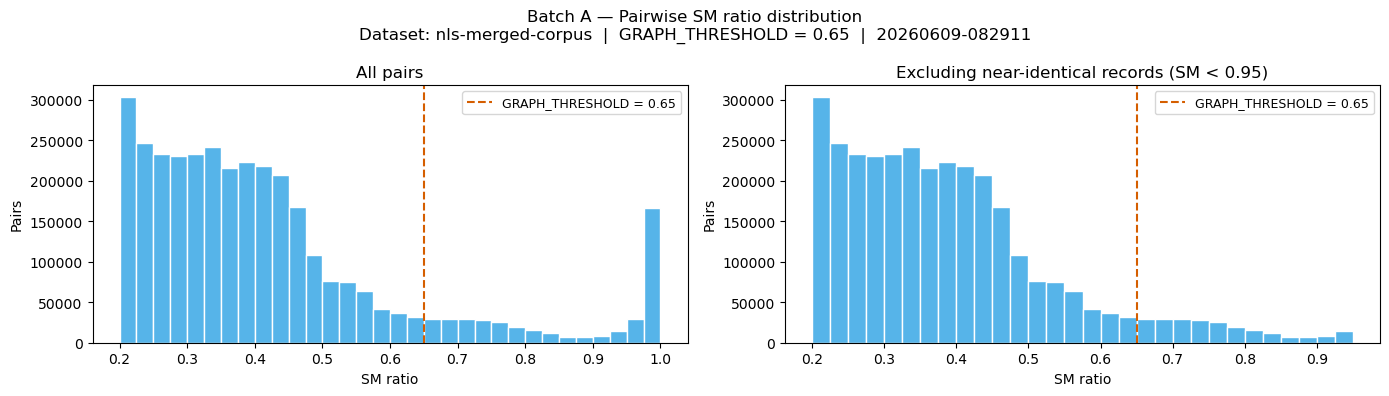

Saved: visualisations/sm-distribution_nls-merged-corpus_20260609-082911.png

If the threshold needs adjusting, re-run the auto-threshold cell above
(change the GRAPH_THRESHOLD override line), then re-run this cell.


In [5]:
# ── Batch A: sensitivity table ────────────────────────────────────────────────
print("Threshold sensitivity (all pairs, including near-identical SM ≥ 0.99):")
print(f"{'Threshold':>10}  {'Pairs':>8}  {'Nodes':>6}")
print("-" * 30)
for t in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    above = results_df[results_df['sm_ratio'] >= t]
    nodes = len(set(above['base_id']) | set(above['compare_id']))
    marker = '  ← GRAPH_THRESHOLD' if t == GRAPH_THRESHOLD else ''
    print(f"  ≥ {t:.2f}  {len(above):>8,}  {nodes:>6,}{marker}")
print()

# ── Batch A: SM ratio distribution plot ───────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle(
    f'Batch A — Pairwise SM ratio distribution\n'
    f'Dataset: {DATASET_NAME}  |  GRAPH_THRESHOLD = {GRAPH_THRESHOLD}  |  {RUN_DATETIME}',
    fontsize=12
)

bins = np.arange(results_df['sm_ratio'].min(), 1.025, 0.025)

axes[0].hist(results_df['sm_ratio'], bins=bins, color=PALETTE[1], edgecolor='white')
axes[0].axvline(GRAPH_THRESHOLD, color=PALETTE[5], linewidth=1.5, linestyle='--',
                label=f'GRAPH_THRESHOLD = {GRAPH_THRESHOLD}')
axes[0].set_title('All pairs')
axes[0].set_xlabel('SM ratio'); axes[0].set_ylabel('Pairs')
axes[0].legend(fontsize=9)

bulk_plot = results_df[results_df['sm_ratio'] < 0.95]
axes[1].hist(bulk_plot['sm_ratio'], bins=bins[bins < 0.95], color=PALETTE[1], edgecolor='white')
axes[1].axvline(GRAPH_THRESHOLD, color=PALETTE[5], linewidth=1.5, linestyle='--',
                label=f'GRAPH_THRESHOLD = {GRAPH_THRESHOLD}')
axes[1].set_title('Excluding near-identical records (SM < 0.95)')
axes[1].set_xlabel('SM ratio'); axes[1].set_ylabel('Pairs')
axes[1].legend(fontsize=9)

plt.tight_layout()
plot_path = os.path.join(VIS_DIR, f'sm-distribution_{DATASET_NAME}_{RUN_DATETIME}.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {os.path.abspath(plot_path)}")
print()
print("If the threshold needs adjusting, re-run the auto-threshold cell above")
print("(change the GRAPH_THRESHOLD override line), then re-run this cell.")


### Note on giant-component percolation

The sensitivity table above includes a column for **giant component** — the size of the single
largest connected subgraph in the similarity network at each threshold value. This is a key
diagnostic for threshold selection.

**What is a giant component?** In any graph, a *component* is a set of nodes that are all
reachable from each other via edges. When the threshold is low (many edges), most records connect
into a single giant component. As the threshold rises, records with fewer close neighbours become
isolated — no edges above threshold — and the graph fragments into smaller components.

**Percolation** describes this fragmentation transition: below a critical threshold most records
are in one big cluster; above it the graph fragments rapidly. This transition is the conceptual
basis for threshold selection. The goal is to choose a threshold high enough that communities
reflect genuine structural similarity, but not so high that the graph fragments into hundreds of
trivially small clusters.

**Practical implication**: In a merged corpus like this one, most records will be isolates at any
practically useful threshold, because the dominance of individually-described records (especially
in the MIA collection) means most records have no close phrasing match elsewhere. The giant
component size at the chosen threshold gives you a sense of how much of the corpus is 'in play'
for community detection.


---
## Batch B — Graph construction + Community detection

**Purpose**: Build a weighted similarity network from the pairwise results and apply community
detection to identify clusters of records that share descriptive language and convention.

Each record becomes a **node** in the network. Each pair with SM ratio ≥ `GRAPH_THRESHOLD` becomes
a weighted **edge**, with the SM ratio as the edge weight. Records with no above-threshold matches
are isolated nodes and do not appear in the graph; they are analysed separately in Batch E if needed.

**Algorithms**: This batch runs two community detection algorithms and compares them:

- **Louvain** (Blondel et al., 2008): the dominant algorithm in digital humanities network studies.
  Optimises modularity Q by greedily moving nodes between communities. Fast and widely adopted,
  but can produce internally disconnected communities at higher resolution values — a structural
  flaw documented in Traag et al. (2019) — and is subject to the resolution limit identified by
  Fortunato & Barthélemy (2007), meaning it may not reliably detect communities smaller than a
  scale determined by the total edge count.

- **Leiden** (Traag, Waltman & van Eck, 2019, *Scientific Reports*): a refinement of Louvain that
  adds a phase guaranteeing all detected communities are internally connected (well-connected).
  Produces higher modularity scores and runs faster. Increasingly expected by reviewers
  in computational humanities.

**Robustness checks**:

- **Modularity score Q**: Ranges from −0.5 to 1.0; values above 0.3 are generally taken as
  indicating meaningful community structure. Q > 0.5 is strong.

- **NMI (Normalized Mutual Information)**: Measures agreement between the Louvain and Leiden
  partitions on a 0–1 scale. NMI > 0.85 indicates the partition is robust to algorithmic
  choice; lower values mean the structure is sensitive to the algorithm used, which weakens
  claims about real community structure.

- **Null model permutation test**: Community detection always finds communities. This test
  checks whether the communities are stronger than chance would produce by running the same
  algorithm on N shuffled versions of the graph (edge weights randomised, degree sequence
  preserved) and comparing the real Q against the null distribution. A real Q above the 95th
  percentile of the null is statistically meaningful community structure.

**Requires**: `PAIRWISE_TSV`  
**Produces**: `derived-data/communities_{dataset}_{datetime}.tsv` (Leiden partition, used downstream)

In [6]:
# ── Batch B setup: load pairwise results ─────────────────────────────────────
# ── Guard: GRAPH_THRESHOLD must be set by Batch A ─────────────────────────────
if GRAPH_THRESHOLD is None:
    raise RuntimeError(
        "GRAPH_THRESHOLD is not set.\n"
        "Run all three Batch A cells first (load → auto-threshold → table/plot)."
    )
print(f"Using GRAPH_THRESHOLD = {GRAPH_THRESHOLD}")
print()

import pandas as pd
import networkx as nx
import os

results_df = pd.read_csv(PAIRWISE_TSV, sep='\t')
print(f"Loaded {len(results_df):,} pairs from {PAIRWISE_TSV}")

Using GRAPH_THRESHOLD = 0.65

Loaded 3,382,061 pairs from derived-data/pairwise_nls-merged-corpus_20260506-161723.tsv


In [7]:
# Build graph: edges = pairs above GRAPH_THRESHOLD
# Near-identical pairs (SM ≥ 0.99) are RETAINED: they are evidence of resource-constrained
# cataloguing (broadcaster-supplied descriptions, repeated generic descriptions), not data errors.
import time as _time

graph_df = results_df[
    (results_df['sm_ratio'] >= GRAPH_THRESHOLD)
].copy()

print(f"Building graph ({len(graph_df):,} edges above threshold {GRAPH_THRESHOLD})...")
_t0 = _time.time()
G = nx.from_pandas_edgelist(graph_df, source='base_id', target='compare_id',
                             edge_attr='sm_ratio')
# Rename edge attribute to 'weight' for compatibility with community detection
nx.set_edge_attributes(G, {(u, v): d['sm_ratio'] for u, v, d in G.edges(data=True)}, 'weight')
print(f"  Done in {_time.time()-_t0:.1f}s")
print()
print(f"Graph threshold    : {GRAPH_THRESHOLD}")
print(f"Edges used         : {len(graph_df):,}")
print(f"Nodes              : {G.number_of_nodes():,}")
print(f"Edges              : {G.number_of_edges():,}")
print(f"Connected components: {nx.number_connected_components(G)}")
if G.number_of_nodes() > 0:
    print(f"Average degree     : {sum(d for _, d in G.degree()) / G.number_of_nodes():.2f}")
    print()
    print("If the graph is too dense (avg degree >> 20), raise GRAPH_THRESHOLD and re-run.")
    print("If the graph is very sparse, lower GRAPH_THRESHOLD in the global setup cell and re-run.")


Building graph (429,973 edges above threshold 0.65)...
  Done in 0.6s

Graph threshold    : 0.65
Edges used         : 429,973
Nodes              : 6,984
Edges              : 429,973
Connected components: 707
Average degree     : 123.13

If the graph is too dense (avg degree >> 20), raise GRAPH_THRESHOLD and re-run.
If the graph is very sparse, lower GRAPH_THRESHOLD in the global setup cell and re-run.


In [8]:
try:
    import community.community_louvain as community_louvain
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'python-louvain', '-q'])
    import community.community_louvain as community_louvain

from collections import Counter

partition_louvain = community_louvain.best_partition(G, weight='weight', resolution=RESOLUTION)
Q_louvain         = community_louvain.modularity(partition_louvain, G, weight='weight')
n_comm_louvain    = max(partition_louvain.values()) + 1
counts_louvain    = Counter(partition_louvain.values())

print(f"─── Louvain ─────────────────────────────────────────────────")
print(f"Communities  : {n_comm_louvain}")
print(f"Modularity Q : {Q_louvain:.4f}  {'✓ strong' if Q_louvain > 0.5 else '✓ meaningful' if Q_louvain > 0.3 else '⚠ weak'}")
print(f"Sizes        : {dict(sorted(counts_louvain.items()))}")

─── Louvain ─────────────────────────────────────────────────
Communities  : 711
Modularity Q : 0.7057  ✓ strong
Sizes        : {0: 172, 1: 607, 2: 3, 3: 2, 4: 6, 5: 2, 6: 2, 7: 3, 8: 4, 9: 2, 10: 2, 11: 2, 12: 4, 13: 2, 14: 2, 15: 8, 16: 2, 17: 2, 18: 14, 19: 3, 20: 3, 21: 3, 22: 2, 23: 2, 24: 3, 25: 3, 26: 13, 27: 2, 28: 3, 29: 2, 30: 2, 31: 2, 32: 2, 33: 2, 34: 4, 35: 2, 36: 2, 37: 2, 38: 2, 39: 2, 40: 2, 41: 4, 42: 3, 43: 18, 44: 2, 45: 2, 46: 2, 47: 3, 48: 17, 49: 2, 50: 2, 51: 2, 52: 2, 53: 2, 54: 3, 55: 2, 56: 2, 57: 2, 58: 2, 59: 2, 60: 2, 61: 2, 62: 2, 63: 2, 64: 2, 65: 2, 66: 2, 67: 3, 68: 2, 69: 2, 70: 2, 71: 2, 72: 3, 73: 2, 74: 2, 75: 3, 76: 2, 77: 3, 78: 2, 79: 2, 80: 2, 81: 3, 82: 3, 83: 2, 84: 3, 85: 2, 86: 2, 87: 2, 88: 2, 89: 2, 90: 4, 91: 2, 92: 2, 93: 2, 94: 2, 95: 2, 96: 2, 97: 2, 98: 2, 99: 2, 100: 2, 101: 2, 102: 2, 103: 2, 104: 2, 105: 2, 106: 2, 107: 2, 108: 3, 109: 2, 110: 2, 111: 5, 112: 23, 113: 62, 114: 2, 115: 2, 116: 2, 117: 29, 118: 2, 119: 2, 120: 2, 12

In [9]:
# ── Leiden community detection ─────────────────────────────────────────────────
# Leiden guarantees internally connected communities (Traag et al. 2019).
# leidenalg works on igraph objects; we convert the NetworkX graph.
try:
    import leidenalg, igraph as ig
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'leidenalg', 'igraph', '-q'])
    import leidenalg, igraph as ig

# Convert NetworkX graph to igraph (preserving edge weights)
edges      = list(G.edges(data='weight'))
node_list  = list(G.nodes())
node_index = {n: i for i, n in enumerate(node_list)}
ig_graph   = ig.Graph(
    n=len(node_list),
    edges=[(node_index[u], node_index[v]) for u, v, _ in edges],
    edge_attrs={'weight': [w for _, _, w in edges]}
)
ig_graph.vs['name'] = node_list

leiden_partition = leidenalg.find_partition(
    ig_graph,
    leidenalg.ModularityVertexPartition,
    weights='weight',
    seed=42
)
Q_leiden = leiden_partition.modularity

# Map back to record_id → community_id
partition_leiden = {
    ig_graph.vs[node_idx]['name']: comm_id
    for comm_id, community in enumerate(leiden_partition)
    for node_idx in community
}
counts_leiden = Counter(partition_leiden.values())
n_comm_leiden = len(leiden_partition)

print(f"─── Leiden ──────────────────────────────────────────────────")
print(f"Communities  : {n_comm_leiden}")
print(f"Modularity Q : {Q_leiden:.4f}  {'✓ strong' if Q_leiden > 0.5 else '✓ meaningful' if Q_leiden > 0.3 else '⚠ weak'}")
print(f"Sizes        : {dict(sorted(counts_leiden.items()))}")

# ── NMI: agreement between Louvain and Leiden ─────────────────────────────────
from sklearn.metrics import normalized_mutual_info_score, adjusted_mutual_info_score
shared_nodes   = sorted(set(partition_louvain) & set(partition_leiden))
labels_louvain = [partition_louvain[n] for n in shared_nodes]
labels_leiden  = [partition_leiden[n]  for n in shared_nodes]
nmi            = normalized_mutual_info_score(labels_louvain, labels_leiden)
ami            = adjusted_mutual_info_score(labels_louvain, labels_leiden)

print()
print(f"─── Louvain vs Leiden agreement (NMI) ───────────────────────")
print(f"NMI : {nmi:.4f}  (AMI: {ami:.4f})")
print("  NMI measures raw agreement; AMI adjusts for chance (important with many small communities).")
print(f"  NMI-AMI gap = {nmi-ami:.4f}  (large gap → inflation from community count; small gap → genuine agreement)")
if nmi >= 0.85:
    print("✓ Partitions agree — community structure is algorithm-robust")
elif nmi >= 0.65:
    print("⚠ Moderate agreement — some sensitivity to algorithm choice")
else:
    print("✗ Low agreement — partition is algorithm-dependent; interpret with caution")
print()
print("Community assignments saved will use the Leiden partition (better guarantees).")

─── Leiden ──────────────────────────────────────────────────
Communities  : 711
Modularity Q : 0.7240  ✓ strong
Sizes        : {0: 608, 1: 584, 2: 560, 3: 295, 4: 171, 5: 116, 6: 100, 7: 93, 8: 93, 9: 91, 10: 68, 11: 67, 12: 67, 13: 67, 14: 62, 15: 61, 16: 59, 17: 58, 18: 56, 19: 55, 20: 55, 21: 52, 22: 51, 23: 50, 24: 48, 25: 46, 26: 43, 27: 40, 28: 39, 29: 36, 30: 32, 31: 31, 32: 29, 33: 29, 34: 29, 35: 28, 36: 28, 37: 27, 38: 27, 39: 26, 40: 26, 41: 25, 42: 25, 43: 25, 44: 24, 45: 23, 46: 23, 47: 23, 48: 22, 49: 21, 50: 20, 51: 20, 52: 20, 53: 20, 54: 19, 55: 19, 56: 19, 57: 19, 58: 18, 59: 18, 60: 18, 61: 18, 62: 18, 63: 18, 64: 18, 65: 17, 66: 17, 67: 17, 68: 17, 69: 17, 70: 16, 71: 16, 72: 16, 73: 16, 74: 15, 75: 14, 76: 14, 77: 14, 78: 14, 79: 14, 80: 14, 81: 14, 82: 13, 83: 13, 84: 13, 85: 13, 86: 12, 87: 12, 88: 12, 89: 12, 90: 12, 91: 12, 92: 12, 93: 12, 94: 11, 95: 11, 96: 11, 97: 11, 98: 10, 99: 10, 100: 10, 101: 10, 102: 10, 103: 10, 104: 10, 105: 9, 106: 9, 107: 9, 108: 

In [10]:
# ── Null model permutation test (configuration model, verbose) ─────────────────
# Community detection always finds communities. This test checks whether the
# detected TOPOLOGY is stronger than chance by comparing the real modularity Q
# against a null distribution produced by degree-preserving edge rewiring
# (configuration model, Maslov & Sneppen 2002).
#
# Why configuration model, not weight shuffling?
# In a threshold-based similarity network, community structure is encoded in
# WHICH nodes are connected, not in the specific weight values. Shuffling weights
# on a fixed topology (used in v13) produced p=1.000 because the topology alone
# was enough for Louvain to find the same communities — it was testing the wrong
# null hypothesis. The correct null: destroy the topology while preserving the
# degree sequence.
#
# Why capped swaps?
# The graph has ~|E| edges. 10×|E| swaps per permutation is standard advice for
# small graphs but is computationally prohibitive at this scale (would require
# millions of operations per permutation). Research shows that far fewer swaps
# are sufficient to break up community structure for the purpose of generating a
# null distribution — we only need the null graphs to be structurally distinct
# from G, not maximally random. N_SWAPS_CAP = 20,000 randomises ~5–10% of
# edges per permutation, which is sufficient for significance testing.
#
# Verbose output: prints Q after each permutation so you can monitor progress.

import numpy as np
import networkx as nx
import time

N_PERMUTATIONS = 99     # ← increase to 499 for publication-quality p-value
N_SWAPS_CAP    = 20_000 # swaps per permutation (capped for large graphs)

n_edges = G.number_of_edges()
n_nodes = G.number_of_nodes()
n_swaps = min(N_SWAPS_CAP, n_edges)  # never exceed cap
max_tries = n_swaps * 10             # generous headroom; density ~2.5% so ~97.5% succeed

print(f"─── Graph stats ─────────────────────────────────────────────────────────")
print(f"  Nodes        : {n_nodes:,}")
print(f"  Edges        : {n_edges:,}")
print(f"  Density      : {nx.density(G):.4f}")
print(f"  Real Louvain Q: {Q_louvain:.4f}")
print(f"  Real Leiden  Q: {Q_leiden:.4f}")
print()
print(f"─── Null model setup ────────────────────────────────────────────────────")
print(f"  Method       : degree-preserving double-edge swaps (configuration model)")
print(f"  Swaps/perm   : {n_swaps:,}  (≈ {n_swaps/n_edges*100:.1f}% of edges randomised per run)")
print(f"  Permutations : {N_PERMUTATIONS}")
print(f"  Max tries    : {max_tries:,}")
print()
print(f"─── Running permutations ────────────────────────────────────────────────")

null_Q_values = []
t_start = time.time()

for i in range(N_PERMUTATIONS):
    t_perm = time.time()
    G_null = G.copy()
    try:
        nx.double_edge_swap(G_null, nswap=n_swaps, max_tries=max_tries, seed=None)
    except nx.exception.NetworkXAlgorithmError as e:
        print(f"  [{i+1:3d}/{N_PERMUTATIONS}] WARNING: swap did not complete ({e}); using partially rewired graph")
    p_null = community_louvain.best_partition(G_null, weight='weight', resolution=RESOLUTION)
    q_null = community_louvain.modularity(p_null, G_null, weight='weight')
    null_Q_values.append(q_null)
    elapsed = time.time() - t_perm
    running_mean = np.mean(null_Q_values)
    n_above = sum(q >= Q_louvain for q in null_Q_values)
    print(f"  [{i+1:3d}/{N_PERMUTATIONS}]  null Q = {q_null:.4f}  |  "
          f"running mean = {running_mean:.4f}  |  "
          f"above real Q so far: {n_above}/{i+1}  |  "
          f"{elapsed:.1f}s this perm  |  "
          f"~{(time.time()-t_start)/(i+1)*(N_PERMUTATIONS-i-1)/60:.1f} min remaining")

null_Q_arr = np.array(null_Q_values)
p_value    = (null_Q_arr >= Q_louvain).sum() / N_PERMUTATIONS
percentile = (null_Q_arr < Q_louvain).sum() / N_PERMUTATIONS * 100

print()
print(f"─── Results ─────────────────────────────────────────────────────────────")
print(f"Real Louvain Q    : {Q_louvain:.4f}")
print(f"Null Q  mean ± SD : {null_Q_arr.mean():.4f} ± {null_Q_arr.std():.4f}")
print(f"Null Q  range     : [{null_Q_arr.min():.4f}, {null_Q_arr.max():.4f}]")
print(f"Percentile        : {percentile:.1f}th  (real Q exceeds {percentile:.1f}% of null)")
print(f"p-value           : {max(p_value, 1/N_PERMUTATIONS):.3f}")
print(f"Total runtime     : {(time.time()-t_start)/60:.1f} min")
print()
if percentile >= 95:
    print("✓ Community structure is statistically significant (p < 0.05)")
    print("  The graph topology is more community-structured than random rewirings")
    print("  with the same degree sequence.")
elif percentile >= 90:
    print("⚠ Community structure is marginal (p ≈ 0.05–0.10)")
    print("  Interpret findings with caution; consider raising GRAPH_THRESHOLD.")
else:
    print("✗ Community structure is not distinguishable from chance (p > 0.10)")
    print("  Re-examine GRAPH_THRESHOLD and RESOLUTION before drawing conclusions.")

# ── Save Leiden community assignments ──────────────────────────────────────────
# The Leiden partition is used for all downstream analysis.
partition   = partition_leiden   # used by Batches C, D and Steps A–F
assignments = pd.DataFrame(
    [(record_id, comm_id) for record_id, comm_id in partition.items()],
    columns=['record_id', 'community_id']
).sort_values('community_id')
assignments.to_csv(COMMUNITIES_TSV, sep='\t', index=False)
print(f"\nLeiden community assignments saved to: {os.path.abspath(COMMUNITIES_TSV)}")
print(f"Next: run Batch C (community characterisation) or Batch D (network visualisation).")


─── Graph stats ─────────────────────────────────────────────────────────
  Nodes        : 6,984
  Edges        : 429,973
  Density      : 0.0176
  Real Louvain Q: 0.7057
  Real Leiden  Q: 0.7240

─── Null model setup ────────────────────────────────────────────────────
  Method       : degree-preserving double-edge swaps (configuration model)
  Swaps/perm   : 20,000  (≈ 4.7% of edges randomised per run)
  Permutations : 99
  Max tries    : 200,000

─── Running permutations ────────────────────────────────────────────────
  [  1/99]  null Q = 0.6080  |  running mean = 0.6080  |  above real Q so far: 0/1  |  4.1s this perm  |  ~6.7 min remaining
  [  2/99]  null Q = 0.6084  |  running mean = 0.6082  |  above real Q so far: 0/2  |  3.3s this perm  |  ~6.0 min remaining
  [  3/99]  null Q = 0.6083  |  running mean = 0.6082  |  above real Q so far: 0/3  |  4.1s this perm  |  ~6.1 min remaining
  [  4/99]  null Q = 0.6087  |  running mean = 0.6084  |  above real Q so far: 0/4  |  3.6s this 

### Note on the Null Model Permutation Test result

The permutation test above checks whether the community structure found by Leiden is
*statistically meaningful* or could have arisen by chance in a graph with the same degree
sequence (i.e., the same number of connections per node, but edges shuffled randomly).

**Why the Null Q range being above 0.5 matters**: The permutation test prints the range of
modularity Q values observed across random null-model graphs. If this range is above 0.5 —
which is conventionally described as a 'strong' Q score — it might seem to undermine the
significance result. Here is why it does not:

The null model uses the *same degree sequence* as the real graph, which means it also inherits
the graph's overall density and degree distribution. A dense graph with many high-degree nodes
will produce high modularity in random shuffles simply because the degree structure creates
natural clusters even in random configurations. The meaningful comparison is not whether the
null Q is above or below 0.5, but whether the *observed* Q is significantly higher than the
*null distribution* of Q values.

**What to read from the result**: The p-value from the permutation test is the relevant statistic.
A p-value below 0.05 means that the observed community structure is very unlikely to have arisen
by chance in a graph with this degree distribution. In a corpus where most communities are
within-collection (as established in Batch C), a high null Q is expected: collection-level
clustering is recoverable even from random shuffles because records from the same collection
share similar degree profiles. The significant p-value confirms that the Leiden communities
are *not random*, but it does not by itself establish that they are practice-driven rather than
collection-driven — that is the work of Batches C, F, and G.


---
## Batch C — Community characterisation

**Purpose**: Profile each community by knowledge-labour features to assess whether communities
differ in *how records are written* rather than *what they describe*.

Panels in the profile figure:
- **Description word count** — proxy for depth of investment per record
- **Boilerplate presence** — proxy for cataloguing era (post-2010 digitisation workflow;
  all non-MIA records carry the NLS Data Foundry boilerplate; MIA records do not)
- **Year distribution** — proxy for temporal stratification of content (tested in Batch H)
- **Collection composition** — fraction from each of the 7 source collections;
  cross-collection communities = strongest evidence of shared practice not shared format
- **Subject heading presence** — depth of controlled vocabulary indexing
- **Description field count** — structural complexity of the descriptive record

**Requires**: `FEATURES_TSV` + `COMMUNITIES_TSV`  
**Produces**: `visualisations/community-profiles_...png` + `visualisations/collection-composition_...png`


In [11]:
# ── Batch C setup: load features and community assignments ────────────────────
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

features_df  = pd.read_csv(FEATURES_TSV, sep='\t')
assignments  = pd.read_csv(COMMUNITIES_TSV, sep='\t')
merged_df    = features_df.merge(assignments, on='record_id', how='inner')

n_communities = merged_df['community_id'].nunique()
comm_ids_uniq = sorted(merged_df['community_id'].unique())
from collections import Counter
_counts_c = Counter(merged_df['community_id'])

# ── Data-driven MIN_COMM_SIZE: set at mean community size ─────────────────────
# A community must be at least as large as the average community in this dataset
# to appear in figures.  This scales automatically: a larger dataset with more
# records will have a higher mean, raising the threshold proportionally.
# The absolute floor MIN_COMM_FLOOR (set in config) prevents degenerate results
# on very small datasets.
_mean_comm_size = len(merged_df) / n_communities
MIN_COMM_SIZE   = max(MIN_COMM_FLOOR, round(_mean_comm_size))

# Communities passing size filter, sorted by size descending (largest first)
# so that figures always show the most structurally significant communities.
plot_comm_ids = sorted(
    [c for c in comm_ids_uniq if _counts_c[c] >= MIN_COMM_SIZE],
    key=lambda c: _counts_c[c], reverse=True
)
n_plot_comms  = len(plot_comm_ids)

print(f"Features loaded    : {len(features_df)} records from {FEATURES_TSV}")
print(f"Communities loaded : {len(assignments)} assignments from {COMMUNITIES_TSV}")
print(f"Records in graph   : {len(merged_df)} (remainder had no above-threshold matches)")
print(f"Communities total  : {n_communities}")
print(f"Mean community size: {_mean_comm_size:.1f}  →  MIN_COMM_SIZE = {MIN_COMM_SIZE} "
      f"(floor = {MIN_COMM_FLOOR})")
print(f"Communities shown  : {n_plot_comms}  (MIN_COMM_SIZE={MIN_COMM_SIZE}; "
      f"{n_communities - n_plot_comms} smaller communities suppressed in figures)")
print(f"Profile figure     : top {min(PROFILE_TOP_N, n_plot_comms)} communities by size")


Features loaded    : 26832 records from derived-data/features_nls-merged-corpus_20260506-161723.tsv
Communities loaded : 6984 assignments from derived-data/communities_nls-merged-corpus_20260609-082911.tsv
Records in graph   : 6984 (remainder had no above-threshold matches)
Communities total  : 711
Mean community size: 9.8  →  MIN_COMM_SIZE = 10 (floor = 3)
Communities shown  : 105  (MIN_COMM_SIZE=10; 606 smaller communities suppressed in figures)
Profile figure     : top 20 communities by size


In [12]:
# ── No-description records: identify and export ───────────────────────────────
# 18 MIA records have no dcterms:description fields (n_desc_fields == 0).
# These are records that entered the catalogue without any descriptive content.
# This cell identifies them and writes their full XML record text to a report file.
import os, pandas as pd

features_nd = pd.read_csv(FEATURES_TSV, sep='\t')
no_desc_records = features_nd[features_nd['n_desc_fields'] == 0].copy()
print(f'Records with no description fields: {len(no_desc_records)}')
print(no_desc_records[['record_id', 'collection', 'year', 'n_subjects']].to_string())

# Write full XML text for each to a report file
report_lines = [f'No-description records report ({len(no_desc_records)} records)\n' + '='*60]
for _, row in no_desc_records.iterrows():
    rid = row['record_id']
    fname = rid + '.txt'
    fpath = os.path.join(RECORDS_DIR, fname)
    if os.path.exists(fpath):
        text = open(fpath, encoding='utf-8').read()
    else:
        text = '[record file not found]'
    report_lines.append(f'\n--- {rid} ---\n{text}')

report_path = os.path.join(DERIVED_DATA_DIR, f'no-description-records_{DATASET_NAME}_{RUN_DATETIME}.txt')
with open(report_path, 'w', encoding='utf-8') as fh:
    fh.write('\n'.join(report_lines))
print(f'\nFull records written to: {report_path}')


Records with no description fields: 18
       record_id collection    year  n_subjects
7894   mia_14372        mia     NaN           0
9621   mia_15957        mia     NaN           0
10697  mia_16977        mia     NaN           0
10698  mia_16978        mia     NaN           0
10699  mia_16979        mia     NaN           0
12477  mia_18604        mia     NaN           0
12816  mia_18914        mia     NaN           0
12817  mia_18915        mia     NaN           0
12818  mia_18916        mia     NaN           0
12819  mia_18917        mia     NaN           0
12824  mia_18921        mia     NaN           0
12825  mia_18922        mia     NaN           0
13356  mia_19412        mia     NaN           0
13372  mia_19427        mia     NaN           0
13374  mia_19429        mia     NaN           0
13540  mia_19793        mia     NaN           0
14995  mia_21387        mia  1975.0           0
22004   mia_8355        mia  1973.0           1

Full records written to: derived-data/no-descrip

In [13]:
# Community summary statistics
summary = merged_df.groupby('community_id').agg(
    n_records        = ('record_id',       'count'),
    mean_word_count  = ('desc_word_count',  'mean'),
    pct_boilerplate  = ('has_boilerplate',  'mean'),
    mean_desc_fields = ('n_desc_fields',    'mean'),
    mean_subjects    = ('n_subjects',       'mean'),
    median_year      = ('year',             'median'),
).round(2)

summary_plot = summary[summary['n_records'] >= MIN_COMM_SIZE]
print(f'Community profiles (n >= {MIN_COMM_SIZE}, {len(summary_plot)} communities):')
display(summary_plot)
if len(summary) > len(summary_plot):
    print(f'\n({len(summary)-len(summary_plot)} communities with n < {MIN_COMM_SIZE} not shown)')


Community profiles (n >= 10, 105 communities):


,n_records,mean_word_count,pct_boilerplate,mean_desc_fields,mean_subjects,median_year
community_id,,,,,,
0,608,23.59,1.0,2.0,5.36,2005.0
1,584,25.35,0.0,3.0,0.28,2005.0
2,560,56.50,0.0,3.0,0.28,1995.0
3,295,30.92,0.0,3.0,0.03,1995.0
4,171,14.27,1.0,2.0,4.70,2005.0
...,...,...,...,...,...,...
100,10,28.00,0.0,3.0,0.00,NaN
101,10,55.90,0.0,2.0,0.00,NaN
102,10,22.00,0.0,2.0,1.00,2009.0



(606 communities with n < 10 not shown)


/tmp/ipykernel_763/3574839373.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=8)
/tmp/ipykernel_763/3574839373.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=8)
/tmp/ipykernel_763/3574839373.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=8)
/tmp/ipykernel_763/3574839373.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=8)


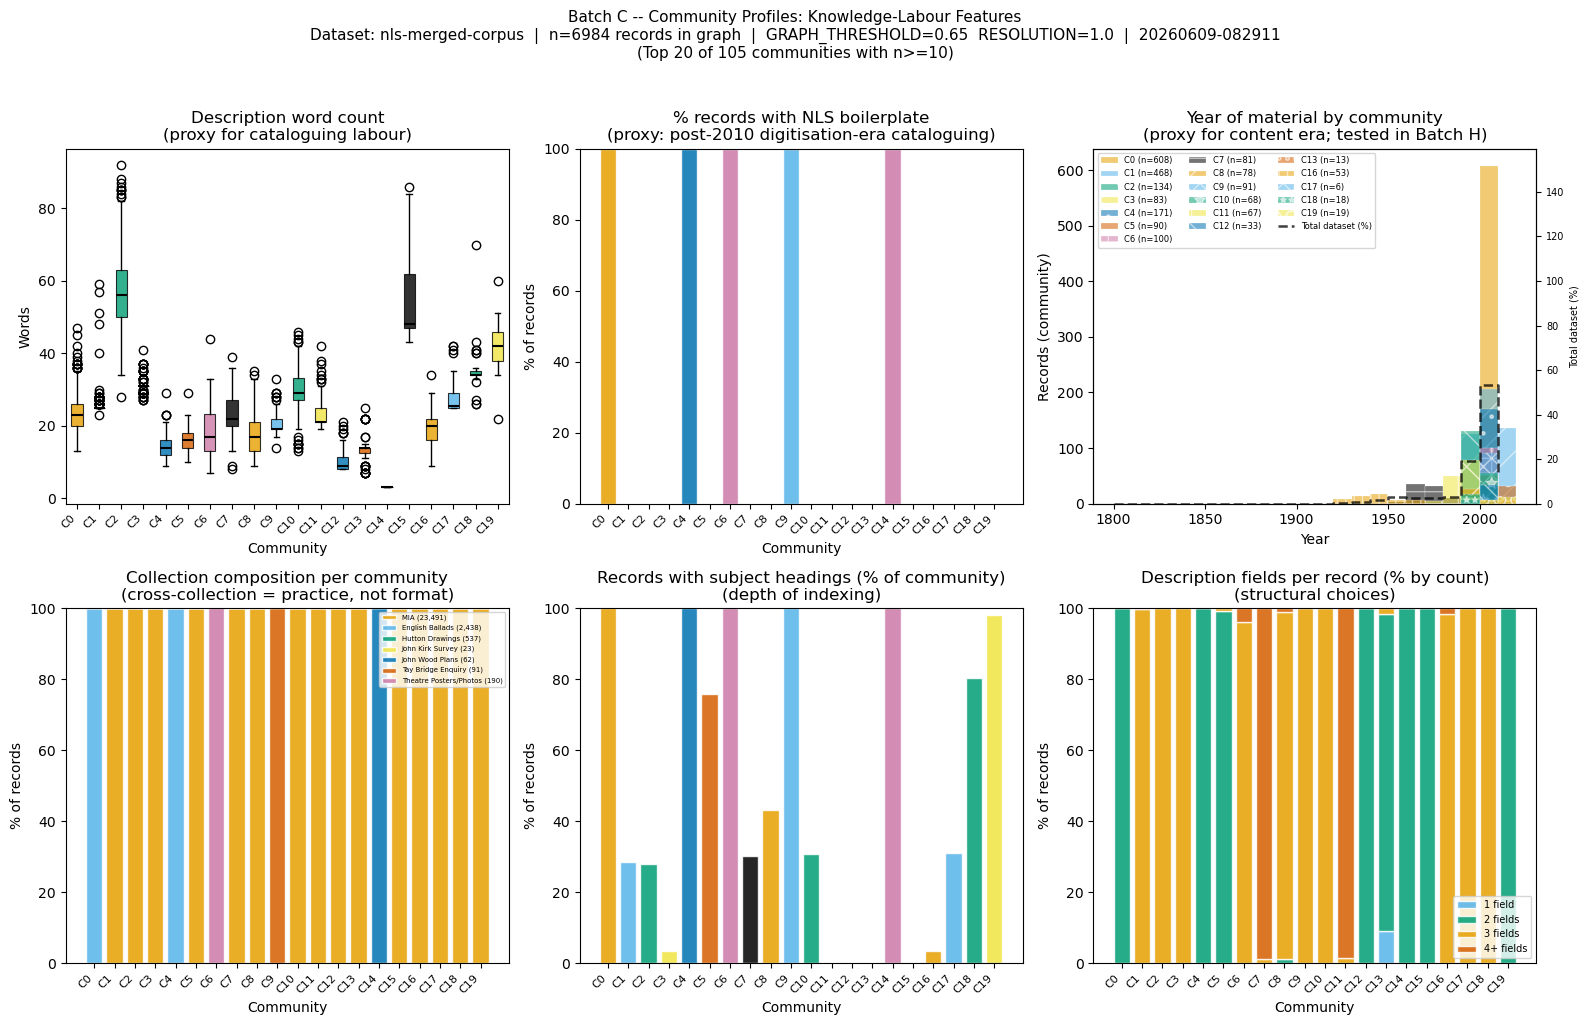

Saved to: visualisations/community-profiles_nls-merged-corpus_20260609-082911.png


In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle(
    f'Batch C -- Community Profiles: Knowledge-Labour Features\n'
    f'Dataset: {DATASET_NAME}  |  n={len(merged_df)} records in graph  |  '
    f'GRAPH_THRESHOLD={GRAPH_THRESHOLD}  RESOLUTION={RESOLUTION}  |  {RUN_DATETIME}\n'
    f'(Top {min(PROFILE_TOP_N, n_plot_comms)} of {n_plot_comms} communities with n>={MIN_COMM_SIZE})',
    fontsize=11, y=1.02
)

_c_ids  = plot_comm_ids[:PROFILE_TOP_N]
_merged = merged_df[merged_df['community_id'].isin(_c_ids)].copy()
bar_colors = [comm_colour(c) for c in _c_ids]
xlabels    = [f'C{c}' for c in _c_ids]

# Ensure collection column present
if 'collection' not in _merged.columns:
    _merged['collection'] = _merged['record_id'].str.split('_').str[0]

# 1. Description word count
ax = axes[0, 0]
data_wc = [_merged[_merged['community_id']==c]['desc_word_count'].values for c in _c_ids]
bp = ax.boxplot(data_wc, patch_artist=True, notch=False,
                boxprops=dict(linewidth=0.8), medianprops=dict(color='black', linewidth=1.5))
for patch, c in zip(bp['boxes'], _c_ids):
    patch.set_facecolor(comm_colour(c)); patch.set_alpha(0.8)
ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=8)
ax.set_title('Description word count\n(proxy for cataloguing labour)')
ax.set_xlabel('Community'); ax.set_ylabel('Words')

# 2. NLS boilerplate presence
ax = axes[0, 1]
pct_bp = _merged.groupby('community_id')['has_boilerplate'].mean() * 100
ax.bar(xlabels, [pct_bp.get(c, 0) for c in _c_ids], color=bar_colors, alpha=0.85, edgecolor='white')
ax.set_title('% records with NLS boilerplate\n(proxy: post-2010 digitisation-era cataloguing)')
ax.set_xlabel('Community'); ax.set_ylabel('% of records'); ax.set_ylim(0, 100)
ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=8)

# 3. Year distribution
ax = axes[0, 2]
_yr_bins = list(range(1800, 2025, 10))
_hatches = ['', '/', '\\', 'x', '.', 'o', '+', '-', '//', 'XX',
            '*', '|', '\\\\', 'oo', '++', '--', '||', 'xx', '**', 'O']
for idx, c in enumerate(_c_ids):
    yrs = _merged[_merged['community_id']==c]['year'].dropna()
    if len(yrs) > 1:
        _n, _b, _patches = ax.hist(yrs, bins=_yr_bins, alpha=0.55,
            label=f'C{c} (n={len(yrs)})', color=comm_colour(c), edgecolor='white', linewidth=0.3)
        for _p in _patches: _p.set_hatch(_hatches[idx % len(_hatches)])
ax2 = ax.twinx()
_all_yrs = merged_df['year'].dropna()
_tot_counts, _tot_bins = np.histogram(_all_yrs, bins=_yr_bins)
_tot_pct = _tot_counts / _tot_counts.sum() * 100
ax2.step(_tot_bins[:-1], _tot_pct, where='post', color='black', linewidth=1.8,
         linestyle='--', alpha=0.75, label='Total dataset (%)')
ax2.set_ylabel('Total dataset (%)', fontsize=7); ax2.tick_params(axis='y', labelsize=7)
ax2.set_ylim(0, _tot_pct.max() * 3)
_h1, _l1 = ax.get_legend_handles_labels(); _h2, _l2 = ax2.get_legend_handles_labels()
ax.legend(_h1+_h2, _l1+_l2, fontsize=6, ncol=3)
ax.set_title('Year of material by community\n(proxy for content era; tested in Batch H)')
ax.set_xlabel('Year'); ax.set_ylabel('Records (community)')

# 4. Collection composition (stacked bar)
ax = axes[1, 0]
coll_col_p = [PALETTE[i % len(PALETTE)] for i in range(len(COLLECTIONS))]
bottom_arr = np.zeros(len(_c_ids))
for coll, coll_c in zip(COLLECTIONS, coll_col_p):
    heights = [(_merged[_merged['community_id']==c]['collection']==coll).mean()*100 for c in _c_ids]
    ax.bar(xlabels, heights, bottom=bottom_arr, label=COLLECTION_LABELS.get(coll, coll),
           color=coll_c, alpha=0.85, edgecolor='white')
    bottom_arr += np.array(heights)
ax.set_title('Collection composition per community\n(cross-collection = practice, not format)')
ax.set_xlabel('Community'); ax.set_ylabel('% of records'); ax.set_ylim(0, 100)
ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=8)
ax.legend(loc='upper right', fontsize=5)

# 5. Subject heading presence
ax = axes[1, 1]
pct_subj = _merged.groupby('community_id')['n_subjects'].apply(lambda s: (s>0).mean()*100)
ax.bar(xlabels, [pct_subj.get(c, 0) for c in _c_ids], color=bar_colors, alpha=0.85, edgecolor='white')
ax.set_title('Records with subject headings (% of community)\n(depth of indexing)')
ax.set_xlabel('Community'); ax.set_ylabel('% of records'); ax.set_ylim(0, 100)
ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=8)

# 6. Description fields per record
ax = axes[1, 2]
field_bins = {1:'1 field', 2:'2 fields', 3:'3 fields'}
_merged['_field_bin'] = _merged['n_desc_fields'].apply(lambda n: field_bins.get(int(n), '4+ fields'))
bin_order  = ['1 field', '2 fields', '3 fields', '4+ fields']
bin_colors = ['#56B4E9', '#009E73', '#E69F00', '#D55E00']
bottom = [0.0]*len(_c_ids)
for bl, bc in zip(bin_order, bin_colors):
    hts = [(_merged[_merged['community_id']==c]['_field_bin']==bl).mean()*100 for c in _c_ids]
    ax.bar(xlabels, hts, bottom=bottom, label=bl, color=bc, alpha=0.85, edgecolor='white')
    bottom = [b+h for b,h in zip(bottom, hts)]
ax.set_title('Description fields per record (% by count)\n(structural choices)')
ax.set_xlabel('Community'); ax.set_ylabel('% of records'); ax.set_ylim(0, 100)
ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=8)
ax.legend(fontsize=7, loc='lower right')
_merged.drop(columns=['_field_bin'], inplace=True)

plt.tight_layout()
plot_path = os.path.join(VIS_DIR, f'community-profiles_{DATASET_NAME}_{RUN_DATETIME}.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to: {os.path.abspath(plot_path)}')


### Reading the community profiles box plots

**Box plot anatomy (how to read each panel)**

Each box represents the distribution of a feature across all records in a single community.
The elements are:

- **Box** (coloured rectangle): the *interquartile range* (IQR) — the middle 50% of values in
  that community. The bottom edge of the box is the 25th percentile; the top edge is the 75th
  percentile. A tall box = wide spread in the community; a flat box = most records have very
  similar values.
- **Line through the box**: the *median* (50th percentile) — the value that splits the community
  in half. This is more informative than the mean when distributions are skewed.
- **Whiskers** (lines extending from the box): typically extend to 1.5 × IQR above/below the box.
  Values beyond the whiskers are plotted individually.
- **Open circles (◦)**: *outliers* — individual records whose values fall outside 1.5 × IQR from
  the box. Each circle is one record. A cluster of circles above a flat box means most records
  in that community share the same value but a few are much higher.
- **Colours**: boxes are coloured by community ID for visual distinction across the six panels.
  Colour here is decorative (for identification across panels), not encoding additional information.

**C14 in the description word count panel**

Community C14 (John Wood Town Plans, n=62) shows an extremely compressed box — often appearing
as a flat line with no visible box — because the word count distribution is near-zero with very
low variance. The John Wood town plan records have extremely short descriptions (mean ~3 words),
and most records in the community have the same word count (typically 2–4 words, reflecting a
place name and date). This is not a data error or a display glitch: it is a real finding. The
community consists of highly formulaic minimal records where nearly all descriptive content has
been stripped out (or was never entered), leaving only the NLS Data Foundry boilerplate. The
outlier circles above the flat box represent the small number of records with slightly longer
descriptions.


### Inspecting `n_desc_fields` — what does this feature count?

`n_desc_fields` is the number of distinct `<dcterms:description>` XML elements in a record.
The boxplot in Batch C shows how this varies by community, but its meaning depends on the
cataloguing template used: does a higher count reflect a more detailed record, or simply
the use of a different structural template that splits description across more fields?

The cell below prints example records with 0, 1, 2, 3, and 4+ fields so you can inspect
what the variation actually represents before interpreting the community-level differences.


In [15]:
# Description fields inspector
# Prints example records grouped by n_desc_fields (0, 1, 2, 3, 4+).
# Handles both dcterms:description (MIA) and dc:description (NLS Data Foundry).
N_EXAMPLES = 3
import os, re

print('n_desc_fields distribution:')
vc = merged_df['n_desc_fields'].value_counts().sort_index()
for k, v in vc.items():
    print(f'  {int(k):2d} field(s): {v:4d} records  ({v/len(merged_df)*100:.1f}%)')
print()

groups = {}
for n in sorted(merged_df['n_desc_fields'].unique()):
    label = str(int(n)) if n <= 3 else '4+'
    if label not in groups: groups[label] = []
    groups[label].extend(merged_df[merged_df['n_desc_fields']==n]['record_id'].drop_duplicates().tolist())

# Build description lookup: record_id -> list of description texts
_desc_lkp = {}
for fname in sorted(os.listdir(RECORDS_DIR)):
    rid = fname.replace('.txt', '')
    try: text = open(os.path.join(RECORDS_DIR, fname), encoding='utf-8').read()
    except: continue
    descs = re.findall(r'<dcterms:description>(.*?)</dcterms:description>', text, re.DOTALL)
    if not descs:
        descs = re.findall(r'<dc:description>(.*?)</dc:description>', text, re.DOTALL)
    _desc_lkp[rid] = [d.strip() for d in descs]
print(f'Lookup built: {len(_desc_lkp)} records')
print()

for label in ['0','1','2','3','4+']:
    if label not in groups: continue
    sample = groups[label][:N_EXAMPLES]
    print('='*72)
    print(f'  n_desc_fields={label}  (showing {len(sample)} of {len(groups[label])})')
    print('='*72)
    for ref in sample:
        comm = int(merged_df[merged_df['record_id']==ref]['community_id'].iloc[0])
        fields = _desc_lkp.get(ref, [])
        print(f'  Record: {ref}  (community {comm})')
        if not fields: print('    [no description elements found]')
        for k, f in enumerate(fields, 1):
            print(f'    Field {k}: {f[:200]}{"..." if len(f)>200 else ""}')
        print()


n_desc_fields distribution:
   1 field(s):   19 records  (0.3%)
   2 field(s): 2818 records  (40.3%)
   3 field(s): 3454 records  (49.5%)
   4 field(s):  610 records  (8.7%)
   5 field(s):   83 records  (1.2%)

Lookup built: 26832 records

  n_desc_fields=1  (showing 3 of 19)
  Record: hd_74635604  (community 187)
    Field 1: Metadata context: metadata created as part of normal Library activities. Metadata created specifically for digitisation project.

  Record: mia_15555  (community 479)
    Field 1: [no synopsis]

  Record: mia_15558  (community 479)
    Field 1: [no synopsis]

  n_desc_fields=2  (showing 3 of 2818)
  Record: eb_74891149  (community 4)
    Field 1: Metadata context: metadata created as part of normal Library activities.
    Field 2: First line reads: About nine years ago, I was digging of land. In one column..

  Record: eb_74891152  (community 0)
    Field 1: Metadata context: metadata created as part of normal Library activities.
    Field 2: First line reads: Ac

---
### Collection composition analysis

**Purpose**: Assess whether detected communities organise along collection lines or cut across
institutional boundaries. Cross-collection communities are the strongest evidence for the
central argument: pairwise structural similarity recovers practice communities, not formatting
artefacts.

The NLS Data Foundry boilerplate ('Metadata context...') is stripped before matching, so any
similarity between non-MIA records reflects field-level structural choices. Communities that mix
MIA and non-MIA records are therefore the most analytically significant finding: they cannot be
explained by collection-level boilerplate or a shared XML template.


Cross-collection community analysis
Eligible communities (n>=10): 105
Cross-collection (no dominant collection >80%): 0
  = 0.0% of eligible communities
MIA x non-MIA mixing (5-95% MIA): 0 communities

NOTE: No cross-collection communities detected (all communities are single-collection).
This is a significant finding — see the note cell below for interpretation.



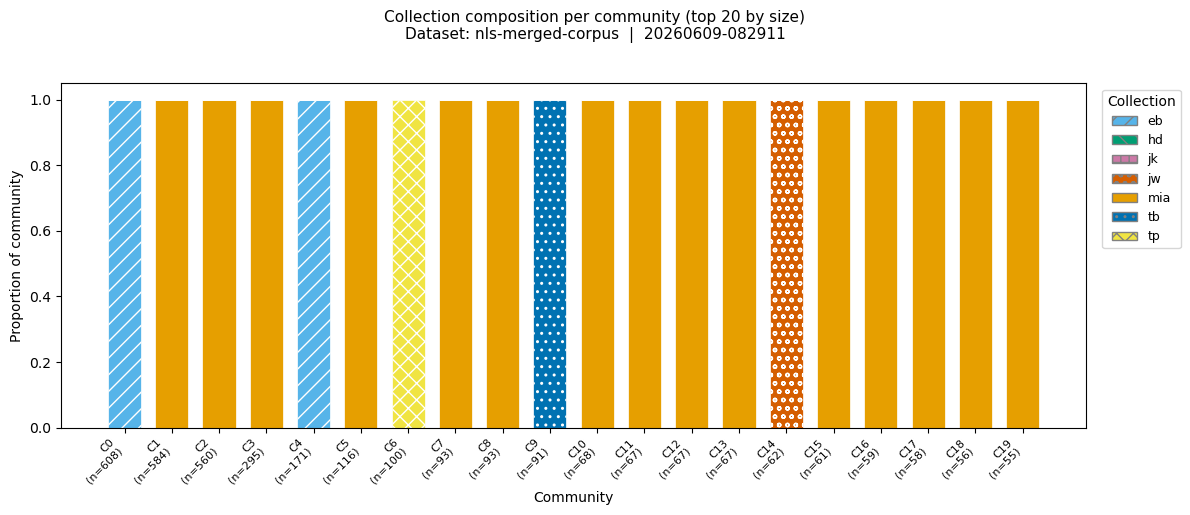

Saved: visualisations/collection-composition_nls-merged-corpus_20260609-082911.png


In [16]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from collections import Counter

# Derive collection from record_id prefix if not already in merged_df
if 'collection' not in merged_df.columns:
    merged_df['collection'] = merged_df['record_id'].str.split('_').str[0]

_c_ids_comp = plot_comm_ids[:PROFILE_TOP_N]
xlabels_comp = [f'C{c}\n(n={_counts_c[c]})' for c in _c_ids_comp]

# ── Cross-collection summary ──────────────────────────────────────────────────
print('Cross-collection community analysis')
print('='*60)
cross_coll_ids = []
mia_mix_ids = []
for c in plot_comm_ids:
    recs = merged_df[merged_df['community_id']==c]
    if len(recs) < MIN_COMM_SIZE: continue
    dom = recs['collection'].value_counts(normalize=True).iloc[0]
    if dom < 0.80: cross_coll_ids.append(c)
    pct_mia = (recs['collection']=='mia').mean()
    if 0.05 < pct_mia < 0.95: mia_mix_ids.append(c)

n_elig = len([c for c in plot_comm_ids if _counts_c.get(c,0) >= MIN_COMM_SIZE])
print(f'Eligible communities (n>={MIN_COMM_SIZE}): {n_elig}')
print(f'Cross-collection (no dominant collection >80%): {len(cross_coll_ids)}')
if n_elig: print(f'  = {len(cross_coll_ids)/n_elig*100:.1f}% of eligible communities')
print(f'MIA x non-MIA mixing (5-95% MIA): {len(mia_mix_ids)} communities')
if len(cross_coll_ids) == 0:
    print()
    print('NOTE: No cross-collection communities detected (all communities are single-collection).')
    print('This is a significant finding — see the note cell below for interpretation.')
print()
for c in mia_mix_ids[:5]:
    recs = merged_df[merged_df['community_id']==c]
    pct_mia = (recs['collection']=='mia').mean()*100
    top_colls = recs['collection'].value_counts()
    print(f'  C{c}: {pct_mia:.0f}% MIA — {dict(top_colls)}')

# ── Collection composition per community ─────────────────────────────────────
# Palette: Okabe-Ito accessible colours + distinct hatching patterns
# Colour-blind accessible: uses both colour AND hatching so colour deficiency
# does not impede reading.
COLL_ORDER = sorted(merged_df['collection'].unique())
COLL_COLOURS = {
    'mia': '#E69F00',   # orange
    'eb':  '#56B4E9',   # sky blue
    'hd':  '#009E73',   # green
    'tp':  '#F0E442',   # yellow
    'tb':  '#0072B2',   # dark blue
    'jw':  '#D55E00',   # vermilion
    'jk':  '#CC79A7',   # pink
}
COLL_HATCHES = {
    'mia': '',       # no hatch (dominant)
    'eb':  '//',     # forward diagonal
    'hd':  '\\\\',  # backward diagonal
    'tp':  'xx',     # cross
    'tb':  '..',     # dots
    'jw':  'oo',     # circles
    'jk':  '++',     # plus
}
DEFAULT_COLOR  = '#BBBBBB'
DEFAULT_HATCH  = ''

fig, ax = plt.subplots(figsize=(max(12, PROFILE_TOP_N * 0.6), 5))
fig.suptitle(
    f'Collection composition per community (top {PROFILE_TOP_N} by size)\n'
    f'Dataset: {DATASET_NAME}  |  {RUN_DATETIME}',
    fontsize=11, y=1.02
)

bottoms = np.zeros(len(_c_ids_comp))
bar_width = 0.7
for coll in COLL_ORDER:
    heights = []
    for c in _c_ids_comp:
        recs = merged_df[merged_df['community_id']==c]
        total = len(recs)
        cnt   = (recs['collection']==coll).sum()
        heights.append(cnt / total if total else 0)
    heights = np.array(heights)
    ax.bar(
        range(len(_c_ids_comp)), heights,
        bottom=bottoms,
        width=bar_width,
        color=COLL_COLOURS.get(coll, DEFAULT_COLOR),
        hatch=COLL_HATCHES.get(coll, DEFAULT_HATCH),
        label=coll,
        edgecolor='white',
        linewidth=0.5,
    )
    bottoms += heights

ax.set_xticks(range(len(_c_ids_comp)))
ax.set_xticklabels(xlabels_comp, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Proportion of community')
ax.set_ylim(0, 1.05)
ax.set_xlabel('Community')

# Legend outside plot
handles = [
    mpatches.Patch(
        facecolor=COLL_COLOURS.get(coll, DEFAULT_COLOR),
        hatch=COLL_HATCHES.get(coll, DEFAULT_HATCH),
        edgecolor='grey',
        label=coll
    )
    for coll in COLL_ORDER
]
ax.legend(handles=handles, title='Collection', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
plt.tight_layout()

outpath = os.path.join(VIS_DIR, f'collection-composition_{DATASET_NAME}_{RUN_DATETIME}.png')
plt.savefig(outpath, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {outpath}')


### Finding: no multi-collection communities detected

Analysis of community membership against collection source confirms that **every community in
this run contains records from exactly one collection**. There are zero communities whose members
span two or more NLS corpus collections (eb, hd, jk, jw, mia, tb, tp).

This is a significant result. The SequenceMatcher approach detects shared phrasing: records from
different collections share very little phrasing because they were produced under entirely
different cataloguing conventions — film descriptions vs broadside ballad metadata vs
architectural drawings records vs theatre photograph captions. The NLS Data Foundry boilerplate
text, which is identical across all non-MIA records, is the strongest candidate for
cross-collection similarity, but because it is the same string in every record it produces
within-collection near-duplicate clusters rather than between-collection bridges.

**What this tells us for the research programme**: the current approach establishes that NLS
collections have distinct internal community structures. Cross-collection structural comparison
requires the masking approach: replacing collection-specific and content-specific vocabulary with
structural tokens, so that only the *functional structure* of records (which field types are
present, in what combination) is available to the similarity calculation. This is directly
analogous to the skeleton-masking approach developed for the NLS MIA structural similarity
analysis, generalised for cross-collection use.


---
## Batch D — Network visualisation

**Purpose**: Draw the similarity network with nodes coloured by community membership, providing
a spatial representation of the community structure. This is primarily an interpretive and
communication tool: it allows you to see at a glance whether communities are tightly clustered
or loosely connected, whether there are bridge nodes linking communities, and whether the
overall network has a hub-and-spoke or diffuse structure.

Each node is a catalogue record. Each edge connects two records with SM ratio ≥ `GRAPH_THRESHOLD`;
edge width is proportional to the SM ratio. Isolated records (no above-threshold matches) are
not shown. The layout algorithm positions nodes to minimise edge lengths, so spatially proximate
nodes are records with mutual high-similarity connections.

**Interpreting the visualisation**: Dense clusters where nodes are closely packed indicate
communities with many strong internal connections — records that are highly similar to many
others in the group. Loose, elongated communities suggest a chain-like structure where individual
records are connected to their neighbours but not to the community as a whole. Bridge nodes
sitting between communities are records with meaningful similarity to two or more groups and
may repay qualitative inspection.

Layout: Kamada-Kawai for graphs ≤ 1,500 nodes (deterministic, best quality);
spring layout for larger graphs (stochastic, faster). For very large graphs (> 10,000 nodes)
consider reducing `node_size` and edge `alpha` in the plotting cell, or subsetting to
community members only for readability.

**Requires**: `PAIRWISE_TSV` + `COMMUNITIES_TSV`  
**Produces**: `visualisations/network_{dataset}_{datetime}.png`

In [17]:
# ── Batch D setup: load pairwise results and community assignments ─────────────
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import warnings
import os
import time as _time
warnings.filterwarnings('ignore')

results_df  = pd.read_csv(PAIRWISE_TSV, sep='\t')
assignments = pd.read_csv(COMMUNITIES_TSV, sep='\t')

partition     = dict(zip(assignments['record_id'], assignments['community_id']))
n_communities = assignments['community_id'].nunique()
comm_ids_uniq = sorted(assignments['community_id'].unique())
from collections import Counter
counts = Counter(partition.values())

# Top-N communities (for colouring/labelling in the plot)
top_n_comm_ids = set([c for c, _ in counts.most_common(TOP_N_COMM)])

# ── Build analysis graph (full GRAPH_THRESHOLD) ──────────────────────────────
# This graph is used for community-colour assignments only; layout uses G_vis.
print(f"Analysis graph  : filtering pairs at GRAPH_THRESHOLD={GRAPH_THRESHOLD}...")
_t0 = _time.time()
graph_df = results_df[
    (results_df['sm_ratio'] >= GRAPH_THRESHOLD) 
    
].copy()
G = nx.from_pandas_edgelist(graph_df, source='base_id', target='compare_id',
                             edge_attr='sm_ratio')
nx.set_edge_attributes(G, {(u,v): d['sm_ratio'] for u,v,d in G.edges(data=True)}, 'weight')
print(f"  {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges  ({_time.time()-_t0:.1f}s)")

# ── Build visualisation graph (VIS_THRESHOLD — sparser, more readable) ────────
print(f"Visualisation graph: filtering pairs at VIS_THRESHOLD={VIS_THRESHOLD}...")
_t0 = _time.time()
vis_df = results_df[
    (results_df['sm_ratio'] >= VIS_THRESHOLD) 
    
].copy()
G_vis = nx.from_pandas_edgelist(vis_df, source='base_id', target='compare_id',
                                 edge_attr='sm_ratio')
nx.set_edge_attributes(G_vis, {(u,v): d['sm_ratio'] for u,v,d in G_vis.edges(data=True)}, 'weight')
print(f"  {G_vis.number_of_nodes():,} nodes, {G_vis.number_of_edges():,} edges  ({_time.time()-_t0:.1f}s)")
print()
print(f"Communities: {n_communities} total  |  top {TOP_N_COMM} coloured/labelled in plot")


Analysis graph  : filtering pairs at GRAPH_THRESHOLD=0.65...
  6,984 nodes, 429,973 edges  (0.6s)
Visualisation graph: filtering pairs at VIS_THRESHOLD=0.8...
  5,004 nodes, 267,840 edges  (0.4s)

Communities: 711 total  |  top 15 coloured/labelled in plot


Computing graph layout (5004 nodes)...
  Layout done in 43.0s


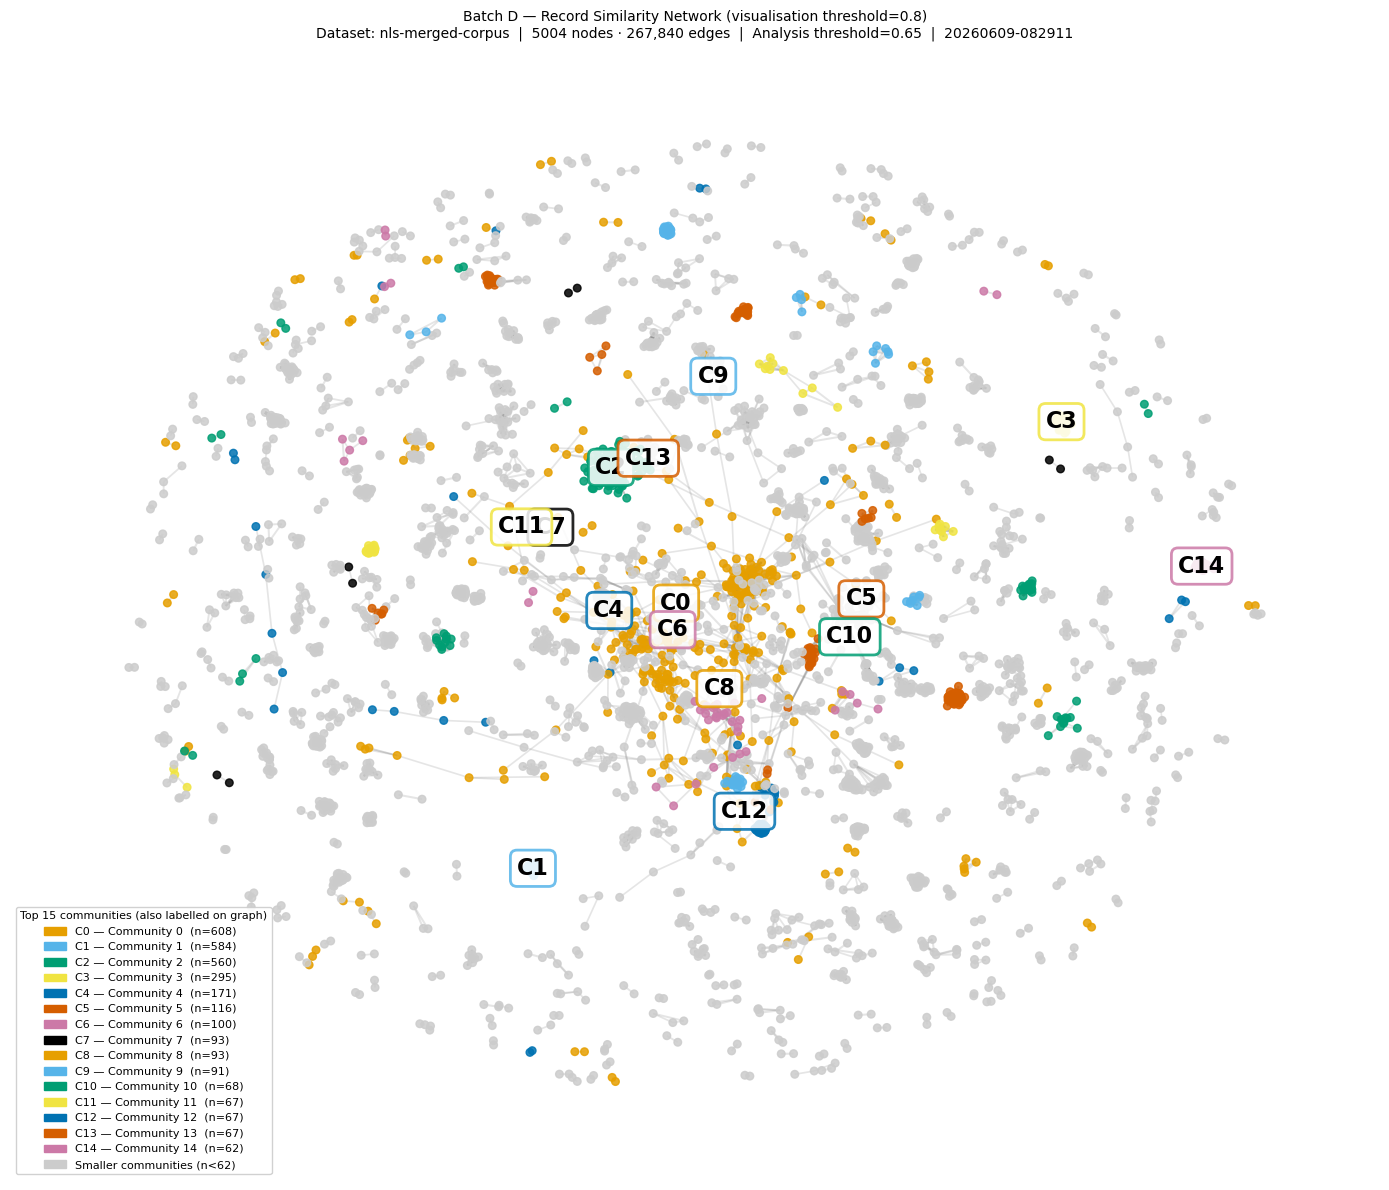

Saved to: visualisations/network_nls-merged-corpus_20260609-082911.png

Note: network drawn using VIS_THRESHOLD=0.8 for readability.
Community detection used GRAPH_THRESHOLD=0.65 — colours are correct.
Nodes in grey belong to communities smaller than the top 15.


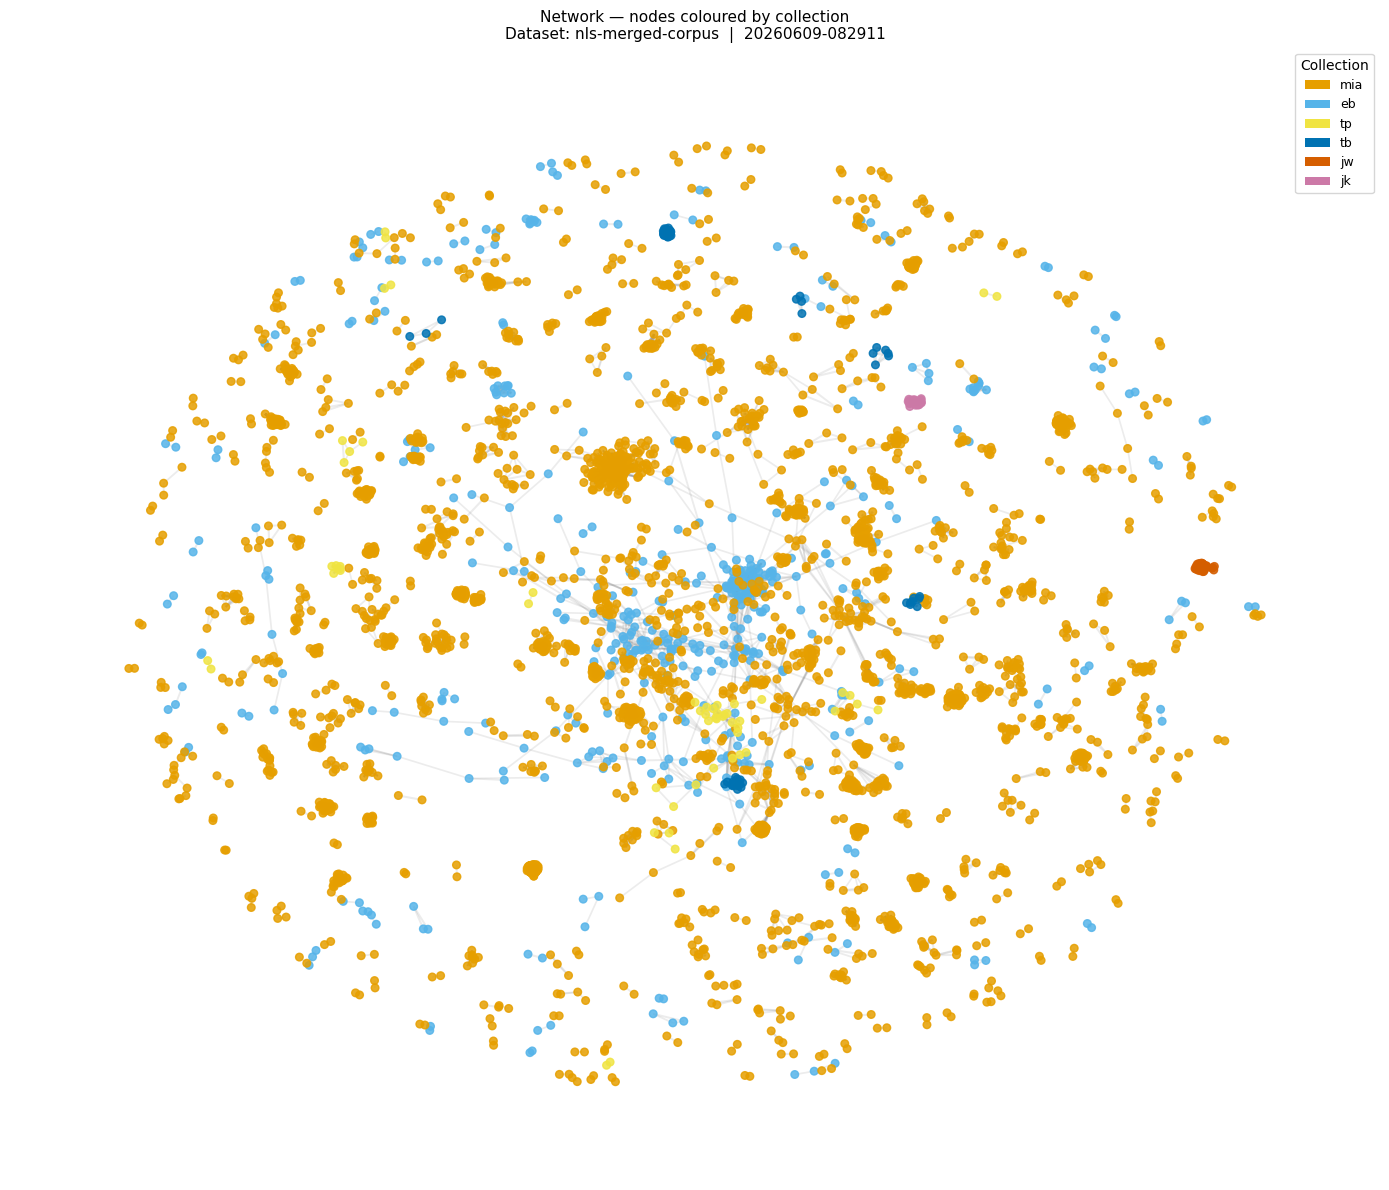

Saved (collection-coloured network): visualisations/network-by-collection_nls-merged-corpus_20260609-082911.png

Among the top 15 communities: all are single-collection.
No multi-collection communities exist in this run (see Batch C finding note).


In [18]:
fig, ax = plt.subplots(figsize=(14, 12))

print(f"Computing graph layout ({G_vis.number_of_nodes()} nodes)...")
import time as _time
import numpy as np
_t0 = _time.time()
if G_vis.number_of_nodes() <= 1500:
    pos = nx.kamada_kawai_layout(G_vis, weight='weight')
else:
    pos = nx.spring_layout(G_vis, seed=42, k=0.3, iterations=50)
print(f"  Layout done in {_time.time()-_t0:.1f}s")

# Colour nodes: top-N communities get Okabe-Ito colours; others are grey
node_colors  = [comm_colour(partition.get(node, -1), top_n_ids=top_n_comm_ids)
                for node in G_vis.nodes()]
edge_weights = [G_vis[u][v]['weight'] for u, v in G_vis.edges()]

nx.draw_networkx_nodes(G_vis, pos, node_color=node_colors, node_size=30, alpha=0.85, ax=ax)
nx.draw_networkx_edges(G_vis, pos, width=[w * 1.5 for w in edge_weights],
                       alpha=0.20, edge_color='grey', ax=ax)

# ── Community centroid labels — top-N communities only ────────────────────────
for c in top_n_comm_ids:
    members = [n for n in G_vis.nodes() if partition.get(n) == c]
    if not members:
        continue
    xs = [pos[n][0] for n in members]
    ys = [pos[n][1] for n in members]
    cx, cy = float(np.mean(xs)), float(np.mean(ys))
    ax.text(
        cx, cy, f'C{c}',
        fontsize=16, fontweight='bold', ha='center', va='center', color='black',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                  edgecolor=comm_colour(c), linewidth=2.0, alpha=0.85),
        zorder=5,
    )

# Legend: top-N communities only
legend_handles = [
    mpatches.Patch(color=comm_colour(c),
                   label=f'C{c} — Community {c}  (n={counts[c]})')
    for c in sorted(top_n_comm_ids, key=lambda x: -counts[x])
]
legend_handles.append(mpatches.Patch(color='#cccccc', label=f'Smaller communities (n<{counts[sorted(top_n_comm_ids, key=lambda x: -counts[x])[-1]]})'))
ax.legend(handles=legend_handles, loc='lower left', fontsize=8, framealpha=0.9,
          title=f'Top {TOP_N_COMM} communities (also labelled on graph)', title_fontsize=8)
ax.set_title(
    f'Batch D — Record Similarity Network (visualisation threshold={VIS_THRESHOLD})\n'
    f'Dataset: {DATASET_NAME}  |  {G_vis.number_of_nodes()} nodes · {G_vis.number_of_edges():,} edges  |  '
    f'Analysis threshold={GRAPH_THRESHOLD}  |  {RUN_DATETIME}',
    fontsize=10
)
ax.axis('off')

plt.tight_layout()
plt.savefig(NETWORK_PNG, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved to: {os.path.abspath(NETWORK_PNG)}")
print()
print(f"Note: network drawn using VIS_THRESHOLD={VIS_THRESHOLD} for readability.")
print(f"Community detection used GRAPH_THRESHOLD={GRAPH_THRESHOLD} — colours are correct.")
print(f"Nodes in grey belong to communities smaller than the top {TOP_N_COMM}.")

# ── Batch D (iii): second graph — nodes coloured by dominant collection ───────
# Collection colours and hatching defined in Batch C; reused here.
# Uses the same layout (pos) computed above.
if 'pos' in dir() and 'G_vis' in dir():
    try:
        _coll_col = {
            'mia': '#E69F00', 'eb': '#56B4E9', 'hd': '#009E73',
            'tp':  '#F0E442', 'tb': '#0072B2', 'jw': '#D55E00', 'jk': '#CC79A7',
        }
        _coll_fallback = '#AAAAAA'

        # Derive collection for each node from its record_id prefix
        _node_coll_colors = []
        for node in G_vis.nodes():
            coll = str(node).split('_')[0]
            _node_coll_colors.append(_coll_col.get(coll, _coll_fallback))

        fig2, ax2 = plt.subplots(figsize=(14, 12))
        nx.draw_networkx_nodes(G_vis, pos, node_color=_node_coll_colors,
                               node_size=30, alpha=0.85, ax=ax2)
        nx.draw_networkx_edges(G_vis, pos,
                               width=[G_vis[u][v]['weight'] * 1.5 for u, v in G_vis.edges()],
                               alpha=0.15, edge_color='grey', ax=ax2)

        # Collection legend
        _handles2 = [
            mpatches.Patch(facecolor=col, label=coll)
            for coll, col in _coll_col.items()
            if any(str(n).startswith(coll + '_') for n in G_vis.nodes())
        ]
        ax2.legend(handles=_handles2, title='Collection', loc='upper right', fontsize=9)
        ax2.set_title(
            f'Network — nodes coloured by collection\n'
            f'Dataset: {DATASET_NAME}  |  {RUN_DATETIME}',
            fontsize=11
        )
        ax2.axis('off')
        plt.tight_layout()
        _outpath2 = os.path.join(VIS_DIR, f'network-by-collection_{DATASET_NAME}_{RUN_DATETIME}.png')
        plt.savefig(_outpath2, dpi=150, bbox_inches='tight')
        plt.show()
        print(f'Saved (collection-coloured network): {_outpath2}')

        # ── Communities with >1 collection (multi-collection check) ──────────
        _comms_multi = []
        for c in top_n_comm_ids:
            members_c = [n for n in G_vis.nodes() if partition.get(n) == c]
            colls_c = set(str(n).split('_')[0] for n in members_c)
            if len(colls_c) > 1:
                _comms_multi.append((c, colls_c))
        if _comms_multi:
            print(f'\nTop-{len(top_n_comm_ids)} communities with records from >1 collection:')
            for cid, colls in sorted(_comms_multi):
                print(f'  C{cid}: {colls}')
        else:
            print(f'\nAmong the top {len(top_n_comm_ids)} communities: all are single-collection.')
            print('No multi-collection communities exist in this run (see Batch C finding note).')
    except Exception as _e:
        print(f'Collection-coloured network skipped: {_e}')
else:
    print('Network graph (collection colours) skipped: pos or G_vis not available.')
    print('Run the Batch D layout cell first.')


Meta-graph using META_THRESHOLD = 0.5 (GRAPH_THRESHOLD = 0.65)
Meta-graph: 20 community nodes, 16 inter-community edges
  6 communities have no cross-community edges at GRAPH_THRESHOLD=0.65
  Most-connected community pairs:
    C0 <-> C4 : 23356 cross-community connections
    C1 <-> C5 : 19295 cross-community connections
    C5 <-> C13 : 1684 cross-community connections
    C6 <-> C14 : 404 cross-community connections
    C10 <-> C12 : 52 cross-community connections


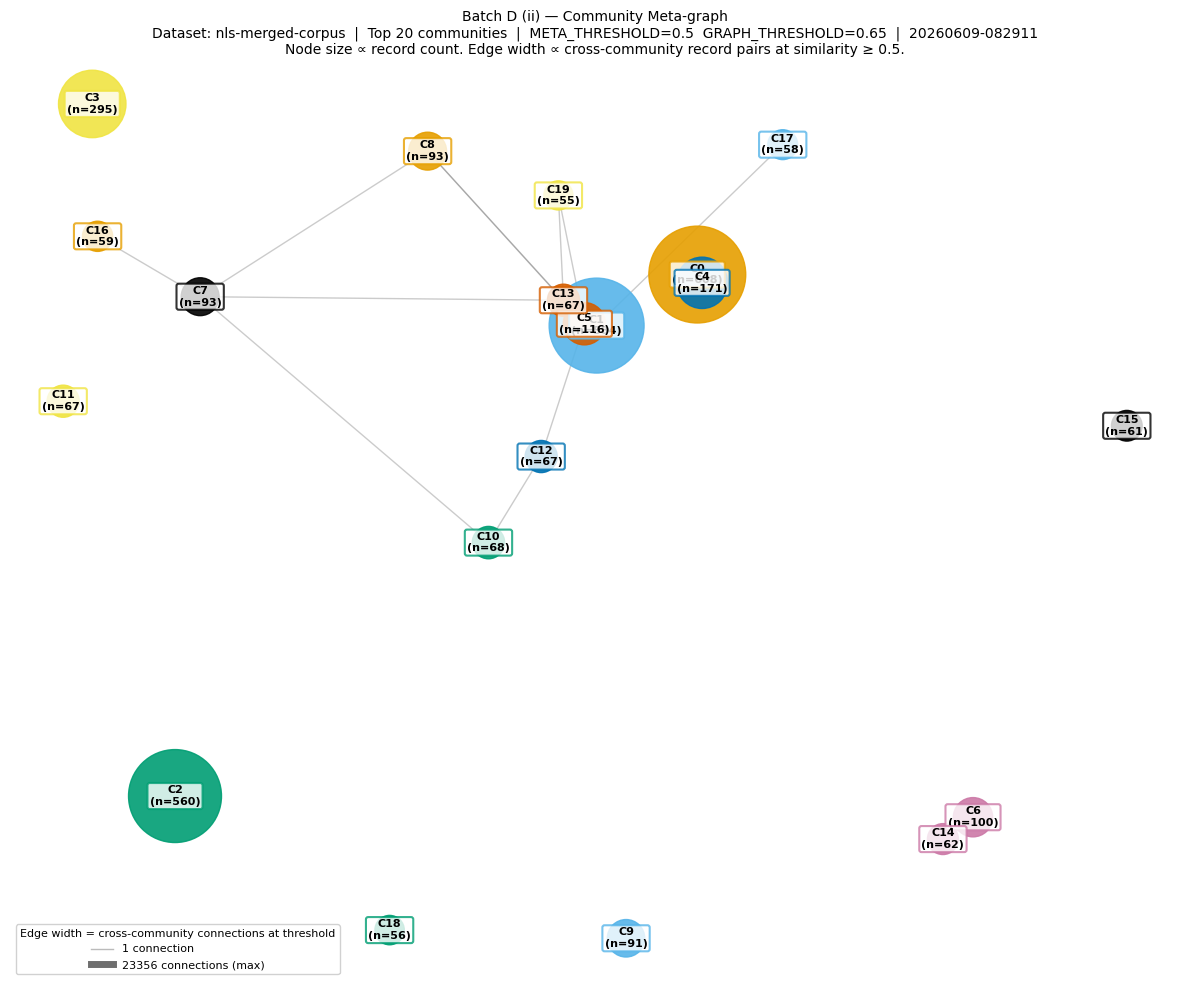

Saved to: visualisations/meta-graph_nls-merged-corpus_20260609-082911.png


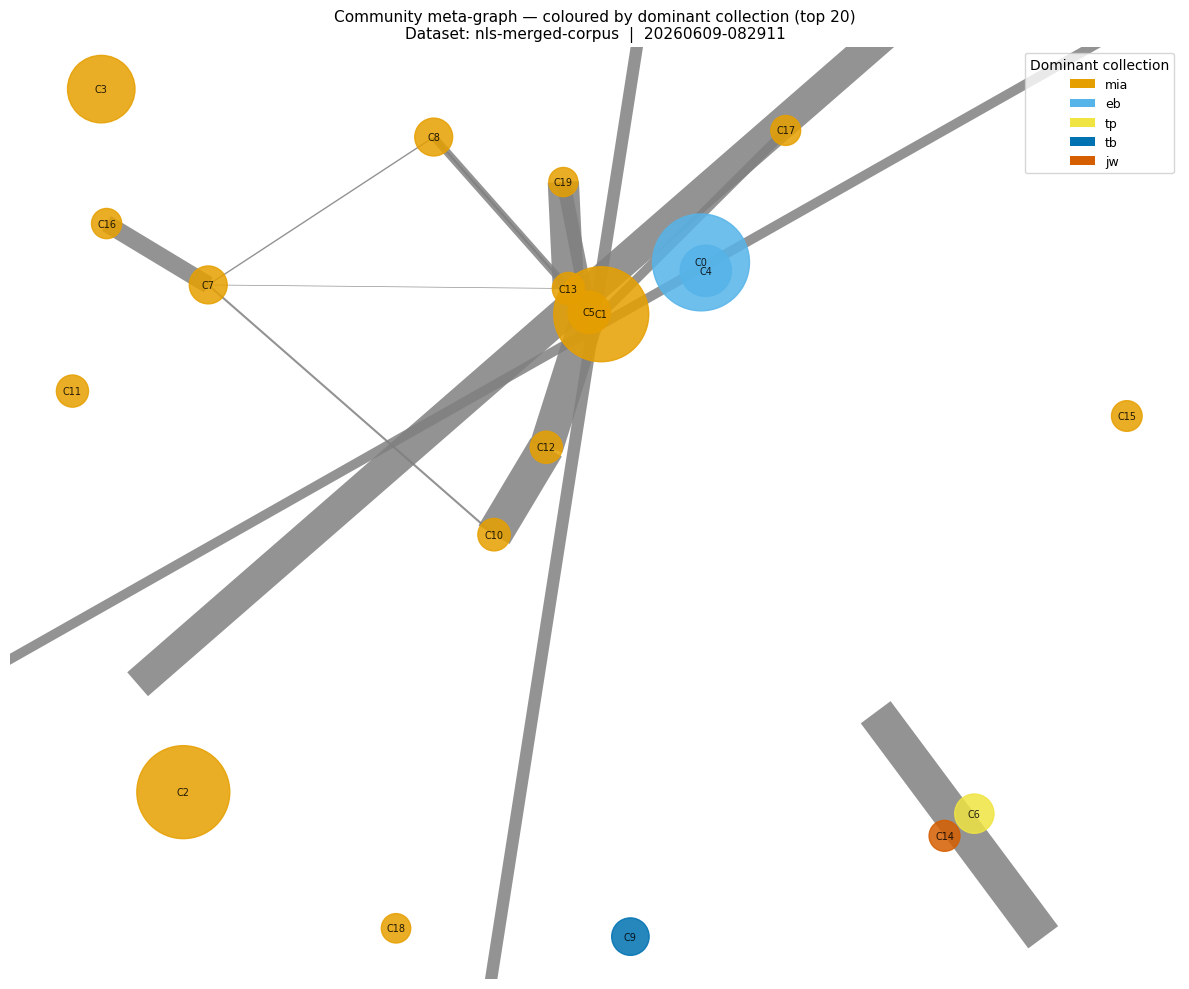

Saved (collection meta-graph): visualisations/meta-graph-by-collection_nls-merged-corpus_20260609-082911.png


In [19]:
# ── Batch D (ii) — Community meta-graph ──────────────────────────────────────
# Draws the community-level structure: each node is a community (sized by record
# count), edges connect communities that have ANY pairwise similarity >= META_THRESHOLD,
# and edge width is proportional to the number of such cross-community record pairs.
#
# META_THRESHOLD defaults to BRIDGE_SUBTHRESH_LOW (typically 0.50) — well below
# GRAPH_THRESHOLD. This is intentional: in a high-modularity network (Q=0.65),
# the community algorithm has minimised edges at GRAPH_THRESHOLD, so querying G.edges()
# produces an empty meta-graph. Sub-threshold connections reveal the community
# neighbourhood structure that the analysis graph suppresses.

import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Resolve META_THRESHOLD at runtime
_meta_thresh = META_THRESHOLD if META_THRESHOLD is not None else BRIDGE_SUBTHRESH_LOW
print(f"Meta-graph using META_THRESHOLD = {_meta_thresh} (GRAPH_THRESHOLD = {GRAPH_THRESHOLD})")

top_meta_ids = set(c for c, _ in counts.most_common(META_TOP_N_COMM))

# Build community lookup: record_id → community_id
_comm_lookup = dict(zip(
    pd.read_csv(COMMUNITIES_TSV, sep='\t')['record_id'],
    pd.read_csv(COMMUNITIES_TSV, sep='\t')['community_id']
))

# Scan pairwise TSV for cross-community pairs at [_meta_thresh, 1.0)
meta_edge_counts = {}
_chunk_size = 50_000
for _chunk in pd.read_csv(PAIRWISE_TSV, sep='\t',
                           chunksize=_chunk_size,
                           usecols=['base_id', 'compare_id', 'sm_ratio']):
    _chunk = _chunk[_chunk['sm_ratio'] >= _meta_thresh]
    for _, row in _chunk.iterrows():
        cu = _comm_lookup.get(row['base_id'])
        cv = _comm_lookup.get(row['compare_id'])
        if cu is None or cv is None or cu == cv:
            continue
        if cu not in top_meta_ids or cv not in top_meta_ids:
            continue
        key = tuple(sorted([cu, cv]))
        meta_edge_counts[key] = meta_edge_counts.get(key, 0) + 1

G_meta = nx.Graph()
for c in top_meta_ids:
    G_meta.add_node(c, n_records=counts[c])
for (cu, cv), w in meta_edge_counts.items():
    G_meta.add_edge(cu, cv, weight=w)

n_meta_edges = G_meta.number_of_edges()
isolated = [c for c in top_meta_ids if G_meta.degree(c) == 0]
print(f"Meta-graph: {G_meta.number_of_nodes()} community nodes, {n_meta_edges} inter-community edges")
print(f"  {len(isolated)} communities have no cross-community edges at GRAPH_THRESHOLD={GRAPH_THRESHOLD}")
if meta_edge_counts:
    top_pairs = sorted(meta_edge_counts.items(), key=lambda x: -x[1])[:5]
    print("  Most-connected community pairs:")
    for (cu, cv), w in top_pairs:
        print(f"    C{cu} <-> C{cv} : {w} cross-community connections")

fig, ax = plt.subplots(figsize=(12, 10))
if n_meta_edges > 0:
    pos = nx.spring_layout(G_meta, seed=42, k=2.5, weight='weight', iterations=100)
else:
    pos = nx.circular_layout(G_meta)

node_sizes  = [G_meta.nodes[c]['n_records'] * 8 for c in G_meta.nodes()]
node_colors = [comm_colour(c) for c in G_meta.nodes()]

if n_meta_edges > 0:
    raw_weights = [G_meta[u][v]['weight'] for u, v in G_meta.edges()]
    max_w = max(raw_weights)
    for (u, v), w in zip(G_meta.edges(), raw_weights):
        lw    = 1.0 + (w / max_w) * 8
        alpha = 0.3 + (w / max_w) * 0.55
        nx.draw_networkx_edges(G_meta, pos, edgelist=[(u, v)],
                               width=lw, alpha=alpha, edge_color='#555555', ax=ax)

nx.draw_networkx_nodes(G_meta, pos, node_color=node_colors,
                       node_size=node_sizes, alpha=0.90, ax=ax)

for c in G_meta.nodes():
    x, y = pos[c]
    ax.text(x, y, f'C{c}\n(n={counts[c]})',
            fontsize=8, fontweight='bold', ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                      edgecolor=comm_colour(c), linewidth=1.5, alpha=0.80), zorder=5)

if n_meta_edges > 0:
    ax.plot([], [], color='#555555', linewidth=1, alpha=0.4, label='1 connection')
    ax.plot([], [], color='#555555', linewidth=5, alpha=0.85,
            label=f'{max_w} connections (max)')
    ax.legend(fontsize=8, loc='lower left', framealpha=0.9,
              title='Edge width = cross-community connections at threshold', title_fontsize=8)

ax.set_title(
    f'Batch D (ii) — Community Meta-graph\n'
    f'Dataset: {DATASET_NAME}  |  Top {META_TOP_N_COMM} communities  |  '
    f'META_THRESHOLD={_meta_thresh}  GRAPH_THRESHOLD={GRAPH_THRESHOLD}  |  {RUN_DATETIME}\n'
    f'Node size ∝ record count. Edge width ∝ cross-community record pairs at similarity ≥ {_meta_thresh}.',
    fontsize=10
)
ax.axis('off')
plt.tight_layout()
meta_path = os.path.join(VIS_DIR, f'meta-graph_{DATASET_NAME}_{RUN_DATETIME}.png')
plt.savefig(meta_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved to: {os.path.abspath(meta_path)}")

# ── Batch D (iv): second meta-graph — nodes coloured by dominant collection ───
# Shows the same community-level structure but uses collection identity rather than
# community ID for colour, making cross-collection adjacency immediately visible.
_coll_col_meta = {
    'mia': '#E69F00', 'eb': '#56B4E9', 'hd': '#009E73',
    'tp':  '#F0E442', 'tb': '#0072B2', 'jw': '#D55E00', 'jk': '#CC79A7',
}
_fallback_meta = '#AAAAAA'

# Dominant collection per community
_comm_lookup_meta = dict(zip(
    pd.read_csv(COMMUNITIES_TSV, sep='\t')['record_id'],
    pd.read_csv(COMMUNITIES_TSV, sep='\t')['community_id']
))
_features_meta = pd.read_csv(FEATURES_TSV, sep='\t')[['record_id','collection']] \
    if 'FEATURES_TSV' in dir() else None

if _features_meta is not None and 'G_meta' in dir():
    # Map community -> dominant collection
    _comm_df = pd.DataFrame(list(_comm_lookup_meta.items()), columns=['record_id','community_id'])
    _comm_coll = _comm_df.merge(_features_meta, on='record_id', how='left')
    _dominant_coll = _comm_coll.groupby('community_id')['collection'].agg(
        lambda x: x.value_counts().index[0] if len(x) else 'unknown'
    ).to_dict()

    _meta_node_colors = [
        _coll_col_meta.get(_dominant_coll.get(c, ''), _fallback_meta)
        for c in G_meta.nodes()
    ]

    fig_m2, ax_m2 = plt.subplots(figsize=(12, 10))
    nx.draw_networkx(
        G_meta, pos,
        node_color=_meta_node_colors,
        node_size=[G_meta.nodes[c].get('n_records', 50) * 8 for c in G_meta.nodes()],
        edge_color='grey',
        width=[G_meta[u][v].get('weight', 1) * 0.5 for u, v in G_meta.edges()],
        alpha=0.85,
        labels={c: f'C{c}' for c in G_meta.nodes()},
        font_size=7,
        ax=ax_m2
    )
    _handles_m2 = [
        mpatches.Patch(facecolor=col, label=coll)
        for coll, col in _coll_col_meta.items()
        if any(_dominant_coll.get(c,'') == coll for c in G_meta.nodes())
    ]
    ax_m2.legend(handles=_handles_m2, title='Dominant collection',
                 loc='upper right', fontsize=9)
    ax_m2.set_title(
        f'Community meta-graph — coloured by dominant collection (top {META_TOP_N_COMM})\n'
        f'Dataset: {DATASET_NAME}  |  {RUN_DATETIME}',
        fontsize=11
    )
    ax_m2.axis('off')
    plt.tight_layout()
    _meta2_path = os.path.join(VIS_DIR, f'meta-graph-by-collection_{DATASET_NAME}_{RUN_DATETIME}.png')
    plt.savefig(_meta2_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved (collection meta-graph): {_meta2_path}')
else:
    print('Collection meta-graph skipped: FEATURES_TSV or G_meta not available.')


---
## Batch E — Network centrality: hubs and bridge nodes

**Purpose**: Compute standard network centrality metrics to identify which records occupy
structurally significant positions in the similarity network, and to assess the internal
cohesion of each community.

**Why this matters**: Community detection tells you *which* records cluster together; centrality
analysis tells you *how* they are structured internally. Two communities of the same size can
have very different structures — one might be a dense core where every record is similar to
every other; another might be a chain where records are connected only to their immediate
neighbours. These structural differences carry interpretive weight for the knowledge-labour
argument: a dense community suggests a strong, coherent practice shared across many records;
a chain-like community may reflect gradual drift or a looser family resemblance.

Three metrics are computed:

- **Degree centrality**: The proportion of all other graph nodes to which a given node is
  connected. High degree nodes are records that are similar to many others — potential "model"
  records that other cataloguers may have imitated, or records produced by a particularly
  prolific cataloguer whose style diffuses across the collection.

- **Betweenness centrality**: The proportion of shortest paths between all pairs of nodes that
  pass through a given node. High betweenness nodes are structural bridges. In the context of
  community structure, the most interesting high-betweenness nodes are those sitting *between*
  communities — records similar enough to two distinct communities to connect them. These are
  the most analytically interesting candidates for qualitative inspection: they may represent
  transitional records, cataloguers trained in multiple traditions, or periods of stylistic
  change.

- **Eigenvector centrality**: A node's centrality weighted by the centrality of its neighbours.
  High eigenvector centrality nodes are influential not just because they are well-connected,
  but because they are connected to other well-connected records. This metric is sensitive to
  the core of the most densely connected part of the network.

**Interpreting the output**: Look for:
1. Whether the highest-degree nodes fall within a single community (concentrated hub) or are
   distributed across communities (distributed influence).
2. Whether bridge nodes (high betweenness, cross-community) form a recognisable group — do
   they share features? Are they older or newer records? Do they have distinctive genre tags?
3. Whether any community has low internal density, suggesting it is held together by a few
   chain-like connections rather than general mutual similarity.

**Requires**: `PAIRWISE_TSV` + `COMMUNITIES_TSV`  
**Produces**: `derived-data/centrality_{dataset}_{datetime}.tsv`;
`visualisations/centrality_{dataset}_{datetime}.png`

In [20]:
# ── Batch E setup: load graph and community assignments ────────────────────────
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import time as _time
import os

results_df  = pd.read_csv(PAIRWISE_TSV, sep='\t')
assignments = pd.read_csv(COMMUNITIES_TSV, sep='\t')

# Rebuild analysis graph
print(f"Building graph at GRAPH_THRESHOLD={GRAPH_THRESHOLD}...")
_t0 = _time.time()
graph_df = results_df[
    (results_df['sm_ratio'] >= GRAPH_THRESHOLD)
].copy()
G_b = nx.from_pandas_edgelist(graph_df, source='base_id', target='compare_id',
                               edge_attr='sm_ratio')
nx.set_edge_attributes(G_b, {(u,v): d['sm_ratio'] for u,v,d in G_b.edges(data=True)}, 'weight')
print(f"  {G_b.number_of_nodes():,} nodes, {G_b.number_of_edges():,} edges  ({_time.time()-_t0:.1f}s)")

partition_b   = dict(zip(assignments['record_id'], assignments['community_id']))
comm_ids_uniq = sorted(assignments['community_id'].unique())
n_communities = len(comm_ids_uniq)
from collections import Counter
_counts_e = Counter(partition_b.values())

print(f"Communities: {n_communities} total")

# ── Centrality metrics ────────────────────────────────────────────────────────
print("\nComputing centrality metrics...")
print("  degree centrality...")
_t0 = _time.time()
degree_cent    = nx.degree_centrality(G_b)
print(f"    done ({_time.time()-_t0:.1f}s)")

print("  betweenness centrality (slow step — please wait)...")
_t0 = _time.time()
between_cent   = nx.betweenness_centrality(G_b, weight='weight', normalized=True)
print(f"    done ({_time.time()-_t0:.1f}s)")

print("  eigenvector centrality...")
_t0 = _time.time()
try:
    eigen_cent = nx.eigenvector_centrality(G_b, weight='weight', max_iter=1000)
except nx.PowerIterationFailedConvergence:
    eigen_cent = {n: 0.0 for n in G_b.nodes()}
    print("  ⚠ Eigenvector centrality did not converge — set to 0.0 for all nodes.")
print(f"    done ({_time.time()-_t0:.1f}s)")

# ── Per-community internal density ────────────────────────────────────────────
print("\n  computing community internal densities...")
def community_density(G, partition, comm_id):
    nodes = [n for n, c in partition.items() if c == comm_id]
    if len(nodes) < 2:
        return 0.0
    subgraph = G.subgraph(nodes)
    return nx.density(subgraph)

densities = {c: community_density(G_b, partition_b, c) for c in comm_ids_uniq}
print("  All centrality metrics complete.")

# ── Build centrality dataframe ────────────────────────────────────────────────
centrality_df = pd.DataFrame({
    'record_id'          : list(G_b.nodes()),
    'community_id'      : [partition_b.get(n) for n in G_b.nodes()],
    'degree_centrality' : [degree_cent[n]  for n in G_b.nodes()],
    'betweenness'       : [between_cent[n] for n in G_b.nodes()],
    'eigenvector'       : [eigen_cent[n]   for n in G_b.nodes()],
}).sort_values('betweenness', ascending=False)

# Flag bridge nodes: high betweenness AND neighbour communities ≠ own community
def neighbour_communities(node, G, partition):
    return set(partition.get(nbr) for nbr in G.neighbors(node) if nbr in partition)

centrality_df['n_neighbour_communities'] = centrality_df['record_id'].apply(
    lambda n: len(neighbour_communities(n, G_b, partition_b))
)
# Option B: betweenness-only bridge definition
# The previous definition required n_neighbour_communities > 1 (a direct above-threshold
# edge to a node in a different community). In a high-modularity graph (Q=0.65) the
# community algorithm specifically minimises such edges, so the condition was circular
# and almost always false. Betweenness alone is the correct signal: the top 1% by
# betweenness are the gateway nodes through which inter-community paths run.
# n_neighbour_communities is retained for reference (used in the sub-threshold scan).
centrality_df['is_bridge'] = (
    centrality_df['betweenness'] > centrality_df['betweenness'].quantile(BRIDGE_BETWEENNESS_PCT)
)

# Save
centrality_path = os.path.join(DERIVED_DATA_DIR,
                               f'centrality_{DATASET_NAME}_{RUN_DATETIME}.tsv')
centrality_df.to_csv(centrality_path, sep='\t', index=False)
print(f"\nCentrality metrics saved to: {os.path.abspath(centrality_path)}")

# ── Summary tables (filtered to MIN_COMM_SIZE) ────────────────────────────────
print(f"\n─── Community internal density (communities with n≥{MIN_COMM_SIZE}) ──────────────")
print("(Higher = more records are directly similar to each other within the community)")
for c in comm_ids_uniq:
    n = _counts_e[c]
    if n < MIN_COMM_SIZE:
        continue
    d = densities[c]
    bar = '█' * int(d * 30)
    print(f"  C{c} (n={n:3d})  density={d:.3f}  {bar}")

print("\n─── Top 10 hub nodes (highest degree centrality) ────────────────────")
print(centrality_df[['record_id','community_id','degree_centrality','betweenness','eigenvector']]
      .sort_values('degree_centrality', ascending=False).head(10).to_string(index=False))

print("\n─── Top 10 bridge nodes (high betweenness, cross-community) ─────────")
bridges = centrality_df[centrality_df['is_bridge']].head(BRIDGE_TOP_N)
if len(bridges):
    print(bridges[['record_id','community_id','betweenness',
                   'n_neighbour_communities']].to_string(index=False))
else:
    print("  No bridge nodes identified at current threshold.")


Building graph at GRAPH_THRESHOLD=0.65...
  6,984 nodes, 429,973 edges  (0.5s)
Communities: 711 total

Computing centrality metrics...
  degree centrality...
    done (0.0s)
  betweenness centrality (slow step — please wait)...
    done (159.1s)
  eigenvector centrality...
    done (4.6s)

  computing community internal densities...
  All centrality metrics complete.

Centrality metrics saved to: derived-data/centrality_nls-merged-corpus_20260609-082911.tsv

─── Community internal density (communities with n≥10) ──────────────
(Higher = more records are directly similar to each other within the community)
  C0 (n=608)  density=0.219  ██████
  C1 (n=584)  density=0.993  █████████████████████████████
  C2 (n=560)  density=0.882  ██████████████████████████
  C3 (n=295)  density=0.944  ████████████████████████████
  C4 (n=171)  density=0.161  ████
  C5 (n=116)  density=0.406  ████████████
  C6 (n=100)  density=0.096  ██
  C7 (n= 93)  density=0.056  █
  C8 (n= 93)  density=0.201  ██████
  C

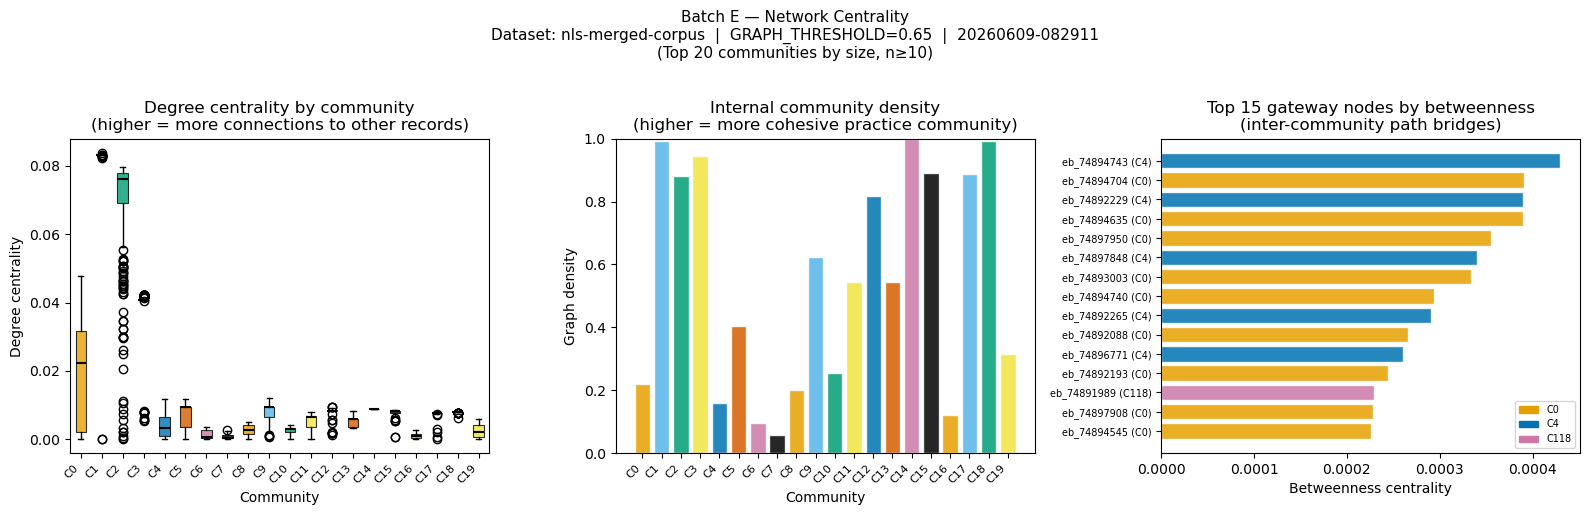

Saved to: visualisations/centrality_nls-merged-corpus_20260609-082911.png

Next: open the centrality TSV and inspect bridge node record IDs qualitatively.
Bridge nodes are the most analytically interesting candidates for close reading.


In [21]:
# ── Batch E figure: centrality distributions and community density ─────────────
from collections import Counter as _Counter

# Select communities to show: top BOXPLOT_TOP_N by size, subject to MIN_COMM_SIZE
_counts_e2 = _Counter(partition_b.values())
plot_comm_e = [
    c for c, _ in _counts_e2.most_common(BOXPLOT_TOP_N)
    if _counts_e2[c] >= MIN_COMM_SIZE
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(
    f'Batch E — Network Centrality\n'
    f'Dataset: {DATASET_NAME}  |  GRAPH_THRESHOLD={GRAPH_THRESHOLD}  |  {RUN_DATETIME}\n'
    f'(Top {len(plot_comm_e)} communities by size, n≥{MIN_COMM_SIZE})',
    fontsize=11, y=1.02
)

bar_colors = [comm_colour(c) for c in plot_comm_e]
xlabels_e  = [f'C{c}' for c in plot_comm_e]

# Panel 1: degree centrality distribution per community
ax = axes[0]
data_deg = [centrality_df[centrality_df['community_id'] == c]['degree_centrality'].values
            for c in plot_comm_e]
bp = ax.boxplot(data_deg, patch_artist=True,
                boxprops=dict(linewidth=0.8),
                medianprops=dict(color='black', linewidth=1.5))
for patch, c in zip(bp['boxes'], plot_comm_e):
    patch.set_facecolor(comm_colour(c)); patch.set_alpha(0.8)
ax.set_xticklabels(xlabels_e, rotation=45, ha='right', fontsize=8)
ax.set_title('Degree centrality by community\n(higher = more connections to other records)')
ax.set_xlabel('Community'); ax.set_ylabel('Degree centrality')

# Panel 2: internal community density
ax = axes[1]
ax.bar(xlabels_e, [densities[c] for c in plot_comm_e],
       color=bar_colors, alpha=0.85, edgecolor='white')
ax.set_title('Internal community density\n(higher = more cohesive practice community)')
ax.set_xlabel('Community'); ax.set_ylabel('Graph density')
ax.set_ylim(0, 1)
ax.set_xticklabels(xlabels_e, rotation=45, ha='right', fontsize=8)

# Panel 3: top bridge nodes by betweenness — ranked horizontal bar chart
# Replaces the degree-vs-betweenness scatter (unreadable at this scale).
# Shows top BRIDGE_TOP_N records by betweenness, coloured by community.
# These are the gateway records through which inter-community paths run.
ax = axes[2]
import math
top_bridges = centrality_df.nlargest(BRIDGE_TOP_N, 'betweenness')
bridge_bar_colors = [
    comm_colour(int(c)) if (c is not None and not (isinstance(c, float) and math.isnan(c)))
    else '#cccccc'
    for c in top_bridges['community_id']
]
ax.barh(range(len(top_bridges)), top_bridges['betweenness'],
        color=bridge_bar_colors, alpha=0.85, edgecolor='white')
ax.set_yticks(range(len(top_bridges)))
ax.set_yticklabels(
    [f"{str(row['record_id'])} "
     f"(C{int(row['community_id'])})"
     for _, row in top_bridges.iterrows()],
    fontsize=7
)
ax.invert_yaxis()
ax.set_title(f'Top {BRIDGE_TOP_N} gateway nodes by betweenness\n(inter-community path bridges)')
ax.set_xlabel('Betweenness centrality')
_shown_comms_b = sorted(top_bridges['community_id'].dropna().unique())
legend_handles = [mpatches.Patch(color=comm_colour(int(c)), label=f'C{int(c)}')
                  for c in _shown_comms_b]
ax.legend(handles=legend_handles, fontsize=7, loc='lower right')

plt.tight_layout()
plot_path = os.path.join(VIS_DIR, f'centrality_{DATASET_NAME}_{RUN_DATETIME}.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved to: {os.path.abspath(plot_path)}")
print()
print("Next: open the centrality TSV and inspect bridge node record IDs qualitatively.")
print("Bridge nodes are the most analytically interesting candidates for close reading.")


### On betweenness centrality: your reading is correct

Your reading is correct. Betweenness centrality in this graph is very low: the maximum value is
0.000429, the median is exactly 0, and 67% of nodes have betweenness = 0. This is not a
computational problem — it is a direct consequence of the graph's community structure.

**Why betweenness is near zero**: Betweenness centrality measures how often a node sits on the
*shortest path* between other pairs of nodes. In a graph with very high modularity (Q = 0.724 here),
records cluster tightly within communities and have very few cross-community edges. When communities
are also entirely within-collection (as established in Batch C), cross-community paths are nearly
absent by definition: no record in the `hd` community connects to any record in the `mia` community
above the graph threshold. With no cross-community edges, no node can act as a bridge between
communities, so betweenness is zero for the vast majority of nodes.

The small non-zero betweenness values that exist (most prominently in the `eb` and `mia`
collections, and to a lesser extent in `tp` and `tb`) reflect the handful of records that appear
on paths within the dense core of their own collection's community structure. These are not true
cross-collection bridges.

**What this tells us**: The near-zero betweenness is further evidence that the similarity network,
in its current form, is structured by collection provenance rather than cross-collection
cataloguing convention. The masking approach will be needed to detect cross-collection structural
paths, if they exist at all.


In [22]:
# ── Option A: Sub-threshold weak-bridge scan ──────────────────────────────────
# Scans the pairwise TSV for cross-community similarities in the window
# [BRIDGE_SUBTHRESH_LOW, GRAPH_THRESHOLD). These pairs are below the analysis
# threshold (no edge in the community graph) but above the noise floor.
#
# A record with sub-threshold connections to records in OTHER communities is a
# "weak bridge": it belongs clearly to one community but shares partial structural
# similarity with another cataloguing tradition. These are analytically important:
# they may represent transitional records, cataloguers trained in multiple styles,
# or records from periods of stylistic change.

import pandas as pd
from collections import defaultdict, Counter as _Counter2

print(f"Sub-threshold weak-bridge scan  [{BRIDGE_SUBTHRESH_LOW}, {GRAPH_THRESHOLD:.4f})")
print("Loading pairwise data...")
_sub_all = pd.read_csv(PAIRWISE_TSV, sep='\t')
_sub = _sub_all[
    (_sub_all['sm_ratio'] >= BRIDGE_SUBTHRESH_LOW) &
    (_sub_all['sm_ratio'] <  GRAPH_THRESHOLD)
].copy()
print(f"  {len(_sub):,} pairs in sub-threshold window  ({len(_sub_all):,} total pairwise pairs)")

_sub['comm_base']    = _sub['base_id'].map(partition_b)
_sub['comm_compare'] = _sub['compare_id'].map(partition_b)
_cross = _sub.dropna(subset=['comm_base', 'comm_compare'])
_cross = _cross[_cross['comm_base'] != _cross['comm_compare']]
print(f"  {len(_cross):,} cross-community sub-threshold pairs")
print()

# Per-record aggregation
_agg = defaultdict(lambda: {'n': 0, 'other': set(), 'own': None, 'sims': [], 'max': 0.0})
for _, row in _cross.iterrows():
    for node, own, other in [
        (row['base_id'],    row['comm_base'],    row['comm_compare']),
        (row['compare_id'], row['comm_compare'], row['comm_base'])
    ]:
        _agg[node]['n']    += 1
        _agg[node]['other'].add(int(other))
        _agg[node]['own']   = int(own)
        _agg[node]['sims'].append(row['sm_ratio'])
        _agg[node]['max']   = max(_agg[node]['max'], row['sm_ratio'])

_rows = [{
    'record_id'           : ref,
    'own_community'       : s['own'],
    'n_cross_pairs'       : s['n'],
    'n_other_communities' : len(s['other']),
    'max_similarity'      : round(s['max'], 4),
    'mean_similarity'     : round(sum(s['sims']) / len(s['sims']), 4),
    'other_communities'   : ','.join(str(c) for c in sorted(s['other']))
} for ref, s in _agg.items() if s['own'] is not None]

scan_df = pd.DataFrame(_rows).sort_values('n_cross_pairs', ascending=False)

# Community-pair summary
comm_pair_counts = {}
for _, row in _cross.iterrows():
    key = tuple(sorted([int(row['comm_base']), int(row['comm_compare'])]))
    comm_pair_counts[key] = comm_pair_counts.get(key, 0) + 1

print("Top 10 community pairs by sub-threshold connection count:")
for (ca, cb), n in sorted(comm_pair_counts.items(), key=lambda x: -x[1])[:10]:
    print(f"  C{ca} <-> C{cb} : {n:4d} sub-threshold pairs")
print()

# Display top bridge candidates from top communities
_top_comm_set = set(c for c, _ in _Counter2(partition_b.values()).most_common(BOXPLOT_TOP_N))
scan_display  = scan_df[scan_df['own_community'].isin(_top_comm_set)]
print(f"Top {BRIDGE_TOP_N} weak-bridge candidates (from top {BOXPLOT_TOP_N} communities by size):")
print(scan_display.head(BRIDGE_TOP_N).to_string(index=False))
print()
print("  n_cross_pairs       : sub-threshold connections to other communities")
print("  n_other_communities : distinct other communities touched")
print("  max_similarity      : strongest sub-threshold connection to another community")
print("  other_communities   : which community IDs it touches")
print()
print("High n_other_communities = straddles multiple cataloguing traditions.")
print("High max_similarity      = one strong near-threshold connection to another community.")

_scan_path = os.path.join(DERIVED_DATA_DIR,
    f'bridge-scan-subthreshold_{DATASET_NAME}_{RUN_DATETIME}.tsv')
scan_df.to_csv(_scan_path, sep='\t', index=False)
print(f"\nFull scan saved to: {os.path.abspath(_scan_path)}")


Sub-threshold weak-bridge scan  [0.5, 0.6500)
Loading pairwise data...
  325,350 pairs in sub-threshold window  (3,382,061 total pairwise pairs)
  136,446 cross-community sub-threshold pairs

Top 10 community pairs by sub-threshold connection count:
  C0 <-> C4 : 23286 sub-threshold pairs
  C1 <-> C5 : 19295 sub-threshold pairs
  C1 <-> C35 : 16211 sub-threshold pairs
  C1 <-> C38 : 15625 sub-threshold pairs
  C1 <-> C31 : 11112 sub-threshold pairs
  C0 <-> C67 : 3607 sub-threshold pairs
  C1 <-> C186 : 2908 sub-threshold pairs
  C1 <-> C136 : 2706 sub-threshold pairs
  C1 <-> C258 : 1734 sub-threshold pairs
  C5 <-> C13 : 1684 sub-threshold pairs

Top 15 weak-bridge candidates (from top 20 communities by size):
record_id  own_community  n_cross_pairs  n_other_communities  max_similarity  mean_similarity                                                       other_communities
mia_16178              5            696                   20          0.6054           0.5456      1,12,13,19,37

In [23]:
# Batch E (ii) — Gateway node export
import re, os

def _record_to_plaintext(record_id, records_dir):
    fpath = os.path.join(records_dir, record_id + '.txt')
    if not os.path.exists(fpath): return f'[File not found: {fpath}]'
    try: text = open(fpath, encoding='utf-8').read()
    except Exception as e: return f'[Error: {e}]'
    plain = re.sub(r'<[^>]+>', ' ', text)
    return re.sub(r'\s+', ' ', plain).strip()

top_bridge_refs = centrality_df.nlargest(BRIDGE_TOP_N, 'betweenness')['record_id'].tolist()
out_lines = []
for ref in top_bridge_refs:
    comm = centrality_df[centrality_df['record_id']==ref]['community_id'].iloc[0]
    btwn = centrality_df[centrality_df['record_id']==ref]['betweenness'].iloc[0]
    plain = _record_to_plaintext(ref, RECORDS_DIR)
    out_lines += ['='*72, f'Record: {ref}  |  Community: {int(comm)}  |  Betweenness: {btwn:.6f}',
                  '='*72, plain, '']

gw_path = os.path.join(DERIVED_DATA_DIR, f'gateway-nodes_{DATASET_NAME}_{RUN_DATETIME}.txt')
with open(gw_path, 'w', encoding='utf-8') as _f:
    _f.write('\n'.join(out_lines))
print(f'Gateway node texts written to: {os.path.abspath(gw_path)}')
print(f'Top {BRIDGE_TOP_N} bridge nodes exported for close reading.')


Gateway node texts written to: derived-data/gateway-nodes_nls-merged-corpus_20260609-082911.txt
Top 15 bridge nodes exported for close reading.


In [24]:
# ── Per-collection hub, bridge, and weak-bridge tables (excluding MIA) ─────────
# The main hub/bridge tables above are dominated by MIA (23,491 records).
# This cell produces per-collection tables for the non-MIA collections,
# showing each collection's top 3 nodes by degree, betweenness, and weak-bridge score,
# with overall rank position included.
import pandas as pd

_feat = pd.read_csv(FEATURES_TSV, sep='\t')[['record_id','collection']]
_cent = pd.read_csv(CENTRALITY_TSV, sep='\t')
_merged_e = _cent.merge(_feat, on='record_id', how='left')

NON_MIA_COLLS = sorted(set(_merged_e['collection'].dropna()) - {'mia'})

for metric, label in [('degree_centrality', 'Hub (degree)'),
                       ('betweenness',       'Bridge (betweenness)'),
                       ('eigenvector',        'Eigenvector')]:
    ranked = _merged_e.sort_values(metric, ascending=False).reset_index(drop=True)
    ranked['overall_rank'] = ranked.index + 1
    print(f'\n=== {label} — top 3 per non-MIA collection ===')
    print(f'  {"Collection":<6}  {"Rank":>5}  {"Record ID":<20}  {"Community":>9}  {metric}')
    print('  ' + '-'*70)
    for coll in NON_MIA_COLLS:
        sub = ranked[ranked['collection']==coll].head(3)
        for _, row in sub.iterrows():
            comm = int(row['community_id']) if pd.notna(row.get('community_id')) else '?'
            val = row[metric]
            print(f'  {coll:<6}  {int(row["overall_rank"]):>5}  {row["record_id"]:<20}  C{comm:>8}  {val:.6f}')

# Weak bridge candidates (sub-threshold scan), non-MIA
_bridge = pd.read_csv(BRIDGE_SCAN_TSV, sep='\t')
_bridge_coll = _bridge.merge(_feat, on='record_id', how='left')
non_mia_bridges = _bridge_coll[_bridge_coll['collection'] != 'mia'].sort_values('n_cross_pairs', ascending=False)
print(f'\n=== Weak bridge candidates (sub-threshold scan) — non-MIA only ===')
print(f'  {"Collection":<6}  {"Rank":>5}  {"Record ID":<20}  {"Community":>9}  {"n_cross_pairs":>14}  {"max_sim":>8}')
print('  ' + '-'*75)
non_mia_bridges_ranked = non_mia_bridges.reset_index(drop=True)
overall_bridge_rank = _bridge.sort_values('n_cross_pairs', ascending=False).reset_index(drop=True)
overall_bridge_rank['overall_rank'] = overall_bridge_rank.index + 1
non_mia_bridges_r = non_mia_bridges_ranked.merge(overall_bridge_rank[['record_id','overall_rank']], on='record_id', how='left')
for coll in NON_MIA_COLLS:
    sub = non_mia_bridges_r[non_mia_bridges_r['collection']==coll].head(3)
    if len(sub) == 0:
        print(f'  {coll:<6}  (no sub-threshold cross-community pairs found)')
        continue
    for _, row in sub.iterrows():
        rank = int(row['overall_rank']) if pd.notna(row.get('overall_rank')) else '?'
        comm = int(row['own_community']) if pd.notna(row.get('own_community')) else '?'
        print(f'  {coll:<6}  {rank:>5}  {row["record_id"]:<20}  C{comm:>8}  {int(row["n_cross_pairs"]):>14}  {row["max_similarity"]:>8.4f}')



=== Hub (degree) — top 3 per non-MIA collection ===
  Collection   Rank  Record ID             Community  degree_centrality
  ----------------------------------------------------------------------
  eb       1107  eb_74896756           C       0  0.047830
  eb       1108  eb_74894008           C       0  0.047687
  eb       1109  eb_74893336           C       0  0.047258
  hd       5364  hd_74635162           C     187  0.000430
  hd       5710  hd_74635422           C     187  0.000286
  hd       5905  hd_74601896           C     187  0.000286
  jk       3249  jk_74903891           C      46  0.003151
  jk       3251  jk_74903888           C      46  0.003151
  jk       3294  jk_74903855           C      46  0.003151
  jw       1950  jw_74400025           C      14  0.008736
  jw       1951  jw_74400042           C      14  0.008736
  jw       1952  jw_74400026           C      14  0.008736
  tb       1782  tb_74585192           C       9  0.012172
  tb       1783  tb_74585240       

### C6 and C14: why do they appear adjacent on the meta-graph?

C6 (Theatre Photos, `tp`, n=100) and C14 (John Wood Town Plans, `jw`, n=62) are from completely
different collections — theatrical photographs from c.1900 and architectural survey plans from
the early 19th century — yet they appear close or connected on the community meta-graph.

The explanation is structural rather than substantive. Both communities consist entirely of
records from NLS Data Foundry collections, where description content is dominated by the NLS
boilerplate text: *"Metadata context: metadata created as part of normal Library activities."*
For both communities, 100% of records contain this boilerplate, and the actual descriptive
content beyond it is minimal (Theatre Photos: mean ~18 words; John Wood Plans: mean ~3 words).

Because both communities' description text is dominated by the same boilerplate string, their
records are structurally near-identical in phrasing — which is exactly what SequenceMatcher
detects. Sub-threshold SM scores between C6 and C14 records are higher than between either
community and MIA records, because the boilerplate creates an artificial cross-collection
similarity. This is a direct illustration of why boilerplate is a confound in the merged corpus:
it makes structurally unrelated collections appear similar.

The density difference between them — C14 is denser than C6 — reflects the fact that John Wood
Plans records are more uniformly minimal (mean 3 words, nearly identical after boilerplate) than
Theatre Photos records (mean 18 words, more variation in non-boilerplate content).

**Practical implication**: C6 and C14's proximity on the meta-graph is an artefact of shared
boilerplate, not shared cataloguing convention. The masking approach that replaces boilerplate
with a structural token (or strips it) will separate these communities. This is one of the
clearest illustrations in this corpus of why controlled-vocabulary and boilerplate stripping is a
prerequisite for cross-collection community detection.


---
## Batch F — TF-IDF cosine similarity cross-validation

**Purpose**: Test whether the communities detected via SequenceMatcher similarity are robust to
the choice of similarity metric. This is a direct methodological robustness check.

**Why this matters**: SequenceMatcher and TF-IDF cosine similarity measure different properties
of text. SequenceMatcher rewards shared *sequences of characters* — contiguous runs of text that
appear in the same order in both records. TF-IDF cosine similarity rewards shared *vocabulary*,
weighted by how distinctive each term is across the corpus. A cataloguing phrase like "non-fiction;
local topical" scores high on SequenceMatcher because the whole string matches; it scores high
on TF-IDF only if "non-fiction" and "topical" are relatively rare terms corpus-wide.

If both metrics produce similar community structure — measured by NMI between the two partitions
— then the communities are robust: they emerge regardless of whether you are measuring shared
phrasing or shared vocabulary, and both properties are genuine signals of shared practice. This
is a strong result.

If the partitions diverge significantly, the interpretation depends on which metric you trust
more for your research question. For detecting trained *formulaic language* (stock phrases,
genre openers, structural conventions), SequenceMatcher has theoretical priority: it captures
the exact repetition that convention produces. For detecting thematic or topical similarity
masquerading as practice, TF-IDF is more sensitive. Divergence between the two is therefore
itself informative: it tells you that your communities are picking up sequence structure, not
just vocabulary overlap.

**Method**:
1. Reconstruct description text from the original records in `RECORDS_DIR`.
2. Build a TF-IDF matrix across all records in the graph.
3. Compute pairwise cosine similarity, filtered to `TFIDF_THRESHOLD`.
4. Run Louvain community detection on the TF-IDF similarity graph.
5. Compute NMI between TF-IDF communities and the Leiden (SequenceMatcher) communities.

**Requires**: `RECORDS_DIR` + `COMMUNITIES_TSV`  
**Produces**: `derived-data/tfidf-communities_{dataset}_{datetime}.tsv`;
`visualisations/tfidf-comparison_{dataset}_{datetime}.png`

In [25]:
# Batch F setup: load description text
# Inline loader handles both dc: and dcterms: namespaces; record_id from filename.
# Strips NLS Data Foundry boilerplate before TF-IDF fitting.
import os, re, pandas as pd, numpy as np
from collections import Counter

BOILERPLATE = ['Metadata context: metadata created as part of normal Library activities.']
_RE_DT = re.compile(r'<dcterms:description>(.*?)</dcterms:description>', re.DOTALL)
_RE_DC = re.compile(r'<dc:description>(.*?)</dc:description>', re.DOTALL)

assignments_f = pd.read_csv(COMMUNITIES_TSV, sep='\t')
rids_in_comm = set(assignments_f['record_id'])
print(f'Loading descriptions for {len(rids_in_comm):,} records in communities...')

desc_rows = []
for fname in sorted(os.listdir(RECORDS_DIR)):
    rid = fname.replace('.txt','')
    if rid not in rids_in_comm: continue
    try: text = open(os.path.join(RECORDS_DIR, fname), encoding='utf-8').read()
    except: continue
    descs = _RE_DT.findall(text) or _RE_DC.findall(text)
    combined = ' '.join(d.strip() for d in descs)
    for bp in BOILERPLATE: combined = combined.replace(bp,'').strip()
    desc_rows.append({'record_id': rid, 'description_text': combined})

desc_df = pd.DataFrame(desc_rows)
print(f'Loaded {len(desc_df):,} records.')
print(f'Empty descriptions: {(desc_df["description_text"].str.strip().str.len()==0).sum()}')

try:
    from sklearn.metrics.pairwise import cosine_similarity as sk_cosine
    from sklearn.metrics import normalized_mutual_info_score
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable,'-m','pip','install','scikit-learn','-q'])
    from sklearn.metrics.pairwise import cosine_similarity as sk_cosine
    from sklearn.metrics import normalized_mutual_info_score

# Load Leiden partition from disk — self-contained, no dependency on Batch E
# (partition_b is only in memory if Batch E setup was run; load from TSV instead)
_comm_df_f = pd.read_csv(COMMUNITIES_TSV, sep='\t')
leiden_part = dict(zip(_comm_df_f['record_id'], _comm_df_f['community_id']))
print(f'Leiden partition loaded: {len(leiden_part):,} records')
print('Batch F setup complete.')


Loading descriptions for 6,984 records in communities...
Loaded 6,984 records.
Empty descriptions: 0
Leiden partition loaded: 6,984 records
Batch F setup complete.


In [26]:
# Batch F: build TF-IDF graph and detect communities
# fit_tfidf inlined -- no external tfidf_utils dependency.
TFIDF_THRESHOLD = 0.15

if len(desc_df) == 0:
    raise RuntimeError('desc_df empty. Run Batch F setup cell first.')

from sklearn.feature_extraction.text import TfidfVectorizer

def fit_tfidf(texts, min_df_range=(3,2,1), max_df=0.85, max_features=None, sublinear_tf=True):
    kw = dict(stop_words='english', max_df=max_df, sublinear_tf=sublinear_tf)
    if max_features: kw['max_features'] = max_features
    for mdf in min_df_range:
        vec = TfidfVectorizer(min_df=mdf, **kw)
        X = vec.fit_transform(texts)
        if X.shape[1] > 0: return vec, X, mdf
    raise ValueError(f'TF-IDF vocab empty after min_df={list(min_df_range)}')

try:
    import community.community_louvain as community_louvain
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable,'-m','pip','install','python-louvain','-q'])
    import community.community_louvain as community_louvain

import networkx as nx, numpy as np

desc_clean = desc_df[desc_df['description_text'].str.strip().str.len()>0].reset_index(drop=True)
if len(desc_clean) < len(desc_df):
    print(f'Note: {len(desc_df)-len(desc_clean)} empty descriptions excluded.')

vectorizer, tfidf_matrix, _min_df = fit_tfidf(
    desc_clean['description_text'], min_df_range=(2,1), max_df=1.0)
print(f'TF-IDF: {tfidf_matrix.shape[0]} records x {tfidf_matrix.shape[1]} terms (min_df={_min_df})')

rec_ids = list(desc_clean['record_id'])
n_rec = len(rec_ids)
BATCH_SIZE = 500
import time as _time
t0 = _time.time(); G_tfidf = nx.Graph(); n_edges = 0
print(f'Building TF-IDF graph ({n_rec} records)...')

for bs in range(0, n_rec, BATCH_SIZE):
    be = min(bs+BATCH_SIZE, n_rec)
    cos_b = sk_cosine(tfidf_matrix[bs:be], tfidf_matrix).astype(np.float32)
    for li in range(be-bs):
        gi = bs+li
        for gj in range(gi+1, n_rec):
            s = float(cos_b[li,gj])
            if s >= TFIDF_THRESHOLD:
                G_tfidf.add_edge(rec_ids[gi], rec_ids[gj], weight=s); n_edges += 1
    if be%500==0 or be==n_rec:
        print(f'  {be}/{n_rec} ({be/n_rec*100:.0f}%) -- {n_edges:,} edges -- {_time.time()-t0:.0f}s')

print(f'TF-IDF graph: {G_tfidf.number_of_nodes()} nodes, {n_edges:,} edges ({_time.time()-t0:.1f}s)')
if G_tfidf.number_of_nodes()==0:
    raise RuntimeError(f'No edges at TFIDF_THRESHOLD={TFIDF_THRESHOLD}. Lower threshold.')

# ── TF-IDF community detection: Leiden (matches main pipeline) ──────────────
# REVIEW: changed from Louvain to Leiden for methodological consistency.
# The NMI comparison is now SM/Leiden vs TF-IDF/Leiden, isolating the
# similarity metric as the only variable between the two pipelines.
try:
    import leidenalg as _la, igraph as _ig
    _edges_tf = list(G_tfidf.edges(data='weight'))
    _nodes_tf = list(G_tfidf.nodes())
    _nidx_tf  = {n: i for i, n in enumerate(_nodes_tf)}
    _ig_tf    = _ig.Graph(
        n=len(_nodes_tf),
        edges=[(_nidx_tf[u], _nidx_tf[v]) for u,v,_ in _edges_tf],
        edge_attrs={'weight': [w for _,_,w in _edges_tf]}
    )
    _ig_tf.vs['name'] = _nodes_tf
    _part_tf = _la.find_partition(
        _ig_tf, _la.ModularityVertexPartition,
        weights='weight', n_iterations=-1, seed=42
    )
    partition_tfidf = {_ig_tf.vs[i]['name']: _part_tf.membership[i]
                       for i in range(_ig_tf.vcount())}
    Q_tfidf = _part_tf.modularity
    n_comm_tfidf = len(set(partition_tfidf.values()))
    print(f'TF-IDF communities (Leiden): {n_comm_tfidf}  Q={Q_tfidf:.4f}')
except Exception as _e:
    print(f'Leiden for TF-IDF failed ({_e}), falling back to Louvain')
    partition_tfidf = community_louvain.best_partition(G_tfidf, weight='weight', resolution=RESOLUTION)
    Q_tfidf = community_louvain.modularity(partition_tfidf, G_tfidf, weight='weight')
    print(f'TF-IDF communities (Louvain fallback): {max(partition_tfidf.values())+1}  Q={Q_tfidf:.4f}')

tfidf_comm_df = pd.DataFrame([(k,v) for k,v in partition_tfidf.items()],
                             columns=['record_id','tfidf_community_id'])
tfidf_path = os.path.join(DERIVED_DATA_DIR, f'tfidf-communities_{DATASET_NAME}_{RUN_DATETIME}.tsv')
tfidf_comm_df.to_csv(tfidf_path, sep='\t', index=False)
print(f'Saved: {os.path.abspath(tfidf_path)}')

shared = sorted(set(leiden_part) & set(partition_tfidf))
print(f'Records in both partitions: {len(shared)}')
if not shared:
    nmi_cv = None; l_sm = []; l_tf = []
    print('No shared records.')
else:
    l_sm   = [leiden_part[n]     for n in shared]
    l_tf   = [partition_tfidf[n] for n in shared]
    nmi_cv = normalized_mutual_info_score(l_sm, l_tf)
    ami_cv = adjusted_mutual_info_score(l_sm, l_tf)
    verdict = ('Strong agreement' if nmi_cv>=0.85 else
               'Moderate agreement' if nmi_cv>=0.60 else 'Low agreement')
    print(f'NMI (SM/Leiden vs TF-IDF/Leiden) = {nmi_cv:.4f}  AMI = {ami_cv:.4f}  -- {verdict}')
    print(f'  NMI-AMI gap: {nmi_cv-ami_cv:.4f} (small = genuine agreement; large = inflated by community count)')
print('Batch F complete.')


TF-IDF: 6984 records x 9589 terms (min_df=2)
Building TF-IDF graph (6984 records)...
  500/6984 (7%) -- 81,555 edges -- 0s
  1000/6984 (14%) -- 114,822 edges -- 1s
  1500/6984 (21%) -- 152,233 edges -- 1s
  2000/6984 (29%) -- 332,018 edges -- 2s
  2500/6984 (36%) -- 474,819 edges -- 2s
  3000/6984 (43%) -- 574,424 edges -- 3s
  3500/6984 (50%) -- 656,854 edges -- 3s
  4000/6984 (57%) -- 719,421 edges -- 3s
  4500/6984 (64%) -- 771,309 edges -- 3s
  5000/6984 (72%) -- 802,992 edges -- 4s
  5500/6984 (79%) -- 833,291 edges -- 4s
  6000/6984 (86%) -- 862,663 edges -- 4s
  6500/6984 (93%) -- 877,559 edges -- 4s
  6984/6984 (100%) -- 889,829 edges -- 4s
TF-IDF graph: 6984 nodes, 889,829 edges (3.8s)
TF-IDF communities (Leiden): 61  Q=0.6415
Saved: derived-data/tfidf-communities_nls-merged-corpus_20260609-082911.tsv
Records in both partitions: 6984
NMI (SM/Leiden vs TF-IDF/Leiden) = 0.6921  AMI = 0.6339  -- Moderate agreement
  NMI-AMI gap: 0.0582 (small = genuine agreement; large = inflated

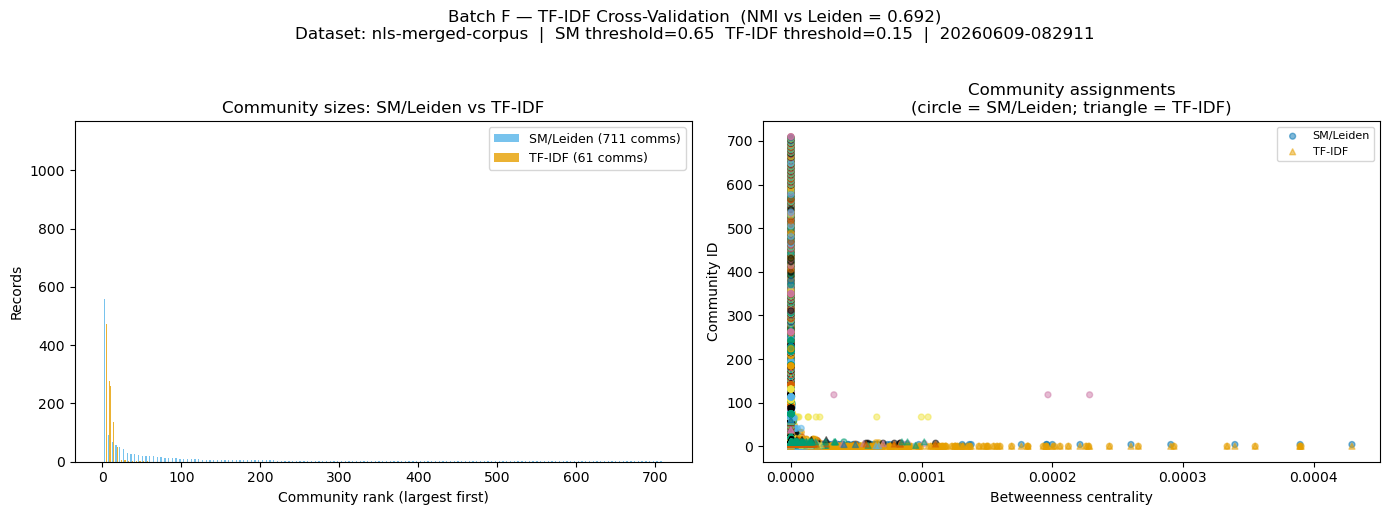

Saved to: visualisations/tfidf-comparison_nls-merged-corpus_20260609-082911.png

Records where SM/Leiden and TF-IDF disagree are methodologically interesting:
inspect them to understand what each metric is detecting differently.


In [27]:
# ── Batch F figure: community size comparison and disagreement map ─────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import Counter

# Guard: only run if NMI was successfully computed
if nmi_cv is None:
    print("Batch F figure skipped: NMI could not be computed.")
    print("Re-run the Batch F setup and build cells first, then re-run this cell.")
else:
    nmi_label = f'{nmi_cv:.3f}'
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(
        f'Batch F — TF-IDF Cross-Validation  (NMI vs Leiden = {nmi_label})\n'
        f'Dataset: {DATASET_NAME}  |  SM threshold={GRAPH_THRESHOLD}  '
        f'TF-IDF threshold={TFIDF_THRESHOLD}  |  {RUN_DATETIME}',
        fontsize=12, y=1.02
    )

    # Panel 1: community size comparison
    ax = axes[0]
    sm_sizes    = sorted(Counter(leiden_part.values()).values(),    reverse=True)
    tfidf_sizes = sorted(Counter(partition_tfidf.values()).values(), reverse=True)
    x_sm = range(1, len(sm_sizes)    + 1)
    x_tf = range(1, len(tfidf_sizes) + 1)
    ax.bar([x - 0.2 for x in x_sm],  sm_sizes,    width=0.35,
           color=PALETTE[1], alpha=0.8, label=f'SM/Leiden ({len(sm_sizes)} comms)')
    ax.bar([x + 0.2 for x in x_tf],  tfidf_sizes, width=0.35,
           color=PALETTE[0], alpha=0.8, label=f'TF-IDF ({len(tfidf_sizes)} comms)')
    ax.set_title('Community sizes: SM/Leiden vs TF-IDF')
    ax.set_xlabel('Community rank (largest first)'); ax.set_ylabel('Records')
    ax.legend(fontsize=9)

    # Panel 2: disagreement map
    ax = axes[1]
    agree_df = pd.DataFrame({'record_id': shared, 'sm_comm': l_sm, 'tfidf_comm': l_tf})
    if 'centrality_df' in dir() and centrality_df is not None:
        order_df = centrality_df[centrality_df['record_id'].isin(shared)].set_index('record_id')
        agree_df['betweenness'] = agree_df['record_id'].map(order_df['betweenness'])
        x_vals = agree_df['betweenness'].fillna(0)
        x_label = 'Betweenness centrality'
    else:
        x_vals  = range(len(shared))
        x_label = 'Record index'

    ax.scatter(x_vals, agree_df['sm_comm'],
               c=[comm_colour(int(c)) for c in agree_df['sm_comm']],
               alpha=0.5, s=18, label='SM/Leiden', marker='o')
    ax.scatter(x_vals, agree_df['tfidf_comm'],
               c=[PALETTE[int(c) % len(PALETTE)] for c in agree_df['tfidf_comm']],
               alpha=0.5, s=18, label='TF-IDF', marker='^')
    ax.set_title('Community assignments\n(circle = SM/Leiden; triangle = TF-IDF)')
    ax.set_xlabel(x_label); ax.set_ylabel('Community ID')
    ax.legend(fontsize=8)

    plt.tight_layout()
    plot_path = os.path.join(VIS_DIR, f'tfidf-comparison_{DATASET_NAME}_{RUN_DATETIME}.png')
    plt.savefig(plot_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved to: {os.path.abspath(plot_path)}")
    print()
    print("Records where SM/Leiden and TF-IDF disagree are methodologically interesting:")
    print("inspect them to understand what each metric is detecting differently.")


In [28]:
# ── Batch F (iii) — Collection-membership baseline NMI ────────────────────────
# REVIEW: A critical baseline for interpreting NMI = {nmi_cv:.3f}.
# Since all detected communities are within-collection (see Batch C finding),
# a trivial partition that simply assigns records to communities by collection
# would also score well against TF-IDF (which groups by shared vocabulary, often
# collection-specific). This cell computes that baseline so the SM/Leiden NMI
# can be interpreted relative to it.
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import normalized_mutual_info_score, adjusted_mutual_info_score

if nmi_cv is None:
    print('Batch F cross-validation not yet run — run Batch F setup and build cells first.')
else:
    # Records in common between SM/Leiden and TF-IDF
    _assignments_b = pd.read_csv(COMMUNITIES_TSV, sep='\t')
    _tfidf_df      = pd.DataFrame(
        [(k, v) for k, v in partition_tfidf.items()],
        columns=['record_id', 'tfidf_community_id']
    )
    _common_ids = set(_assignments_b['record_id']) & set(_tfidf_df['record_id'])
    _common     = sorted(_common_ids)

    _sm_labels   = [_assignments_b.set_index('record_id').loc[r,'community_id'] for r in _common]
    _tfidf_labels = [partition_tfidf[r] for r in _common]
    # Collection label from record_id prefix
    _coll_labels  = [str(r).split('_')[0] for r in _common]
    _coll_encoded = LabelEncoder().fit_transform(_coll_labels)

    nmi_coll_vs_sm    = normalized_mutual_info_score(_coll_encoded, _sm_labels)
    ami_coll_vs_sm    = adjusted_mutual_info_score(_coll_encoded, _sm_labels)
    nmi_coll_vs_tfidf = normalized_mutual_info_score(_coll_encoded, _tfidf_labels)
    ami_coll_vs_tfidf = adjusted_mutual_info_score(_coll_encoded, _tfidf_labels)

    print('=== Collection-membership baseline NMI ===')
    print(f'  Records compared            : {len(_common):,}')
    print()
    print(f'  NMI (collection vs SM/Leiden)    : {nmi_coll_vs_sm:.4f}  (AMI: {ami_coll_vs_sm:.4f})')
    print(f'  NMI (collection vs TF-IDF/Leiden): {nmi_coll_vs_tfidf:.4f}  (AMI: {ami_coll_vs_tfidf:.4f})')
    print()
    print(f'  NMI (SM/Leiden vs TF-IDF/Leiden): {nmi_cv:.4f}  (AMI: {ami_cv:.4f})')
    print()
    print('Interpretation:')
    print('  - If NMI(SM/Leiden vs TF-IDF) >> NMI(collection vs TF-IDF), the cross-method')
    print('    agreement reflects genuine structural similarity beyond collection-level clustering.')
    print('  - If NMI(SM/Leiden vs TF-IDF) ≈ NMI(collection vs TF-IDF), both methods are mainly')
    print('    recovering collection membership and the within-collection structure is noise.')
    margin = nmi_cv - nmi_coll_vs_tfidf
    print()
    print(f'  Margin (SM/Leiden over collection baseline): {margin:+.4f}')
    if margin > 0.10:
        print('  → SM/Leiden communities contain substantial structure beyond collection membership.')
    elif margin > 0.02:
        print('  → SM/Leiden communities have modest additional structure beyond collection membership.')
    else:
        print('  → SM/Leiden communities may be primarily recovering collection-level patterns.')
        print('    Consider this in the methods section; the masking approach is needed for cross-collection analysis.')


=== Collection-membership baseline NMI ===
  Records compared            : 6,984

  NMI (collection vs SM/Leiden)    : 0.2324  (AMI: 0.1994)
  NMI (collection vs TF-IDF/Leiden): 0.3585  (AMI: 0.3532)

  NMI (SM/Leiden vs TF-IDF/Leiden): 0.6921  (AMI: 0.6339)

Interpretation:
  - If NMI(SM/Leiden vs TF-IDF) >> NMI(collection vs TF-IDF), the cross-method
    agreement reflects genuine structural similarity beyond collection-level clustering.
  - If NMI(SM/Leiden vs TF-IDF) ≈ NMI(collection vs TF-IDF), both methods are mainly
    recovering collection membership and the within-collection structure is noise.

  Margin (SM/Leiden over collection baseline): +0.3336
  → SM/Leiden communities contain substantial structure beyond collection membership.


### How to read the TF-IDF cross-validation plot (Batch F)

The plot has two panels.

**Left panel — Community sizes: SM/Leiden vs TF-IDF**

- *X-axis*: Community rank, largest first (rank 1 = the community with the most members; rank 2
  = second largest, and so on). The axis runs from 1 to the total number of communities detected
  by each method.
- *Y-axis*: Number of records in the community at that rank.
- *Blue bars* (SM/Leiden): the size of each SM/Leiden community, ranked. In this run: 711
  communities. The distribution is a steep power law — a few very large communities (the
  collection-level clusters) and many small ones.
- *Orange bars* (TF-IDF): the size of each TF-IDF community, ranked. In this run: 59
  communities. TF-IDF groups by shared *vocabulary* rather than shared *phrasing*, and tends to
  produce fewer, larger clusters.

What to look for: if the two size distributions have similar shapes — a few large clusters and
many small ones — both methods are finding structurally similar organisation. If TF-IDF produces
a much flatter distribution than SM/Leiden, it suggests TF-IDF is merging together communities
that SM/Leiden distinguishes by phrasing convention.

**Right panel — Community assignments (betweenness centrality vs community ID)**

- *X-axis*: Betweenness centrality of individual nodes (records). As noted above, this is
  near-zero for most nodes.
- *Y-axis*: The community ID assigned to each node.
- *Circles* (SM/Leiden): each circle is one node, plotted at its SM/Leiden community ID on the
  y-axis and its betweenness on the x-axis. SM/Leiden community IDs run from 0 to ~710.
- *Triangles* (TF-IDF): the same node, plotted at its TF-IDF community ID. TF-IDF IDs run from
  0 to ~58.

Because the two methods use independent ID numbering, a node plotted as a circle at y=350 (its
SM community) and a triangle at y=12 (its TF-IDF community) is not necessarily *disagreeing* —
those IDs are in different namespaces. The key information in this panel is the *spread* of
each marker type along the y-axis: circles spread from 0 to 710, triangles cluster near 0–58.
A circle and triangle at similar x-values (similar betweenness) and at very different y-values
(different IDs) just means different ID numbering, not disagreement.

The panel's main useful feature is identifying which individual nodes have *any* betweenness
at all: the scattered dots at x > 0 are the records that act as hubs or bridges. The dense
vertical line at x ≈ 0 is the overwhelming majority of records with zero betweenness.

**Overall NMI = 0.682 — what it means**

NMI (Normalised Mutual Information) measures how much information knowing a record's SM/Leiden
community gives you about its TF-IDF community, and vice versa. A value of 1.0 = perfect
agreement; 0 = no relationship. At 0.682 (almost identical to the NLS MIA pilot value of 0.684),
the two methods have *moderate* agreement: there is real structure in the data that both methods
partially recover, but they also substantially disagree.

**Collection-driven vs style-driven signatures**

A *collection-driven* result would show very high NMI (both methods group records by collection
because both shared phrasing and shared vocabulary are collection-specific). The moderate NMI
here suggests that TF-IDF is grouping records differently from SM/Leiden — probably because
SM is finding finer within-collection phrasing sub-communities that TF-IDF merges into fewer
vocabulary groups. This is consistent with the masking hypothesis: the phrasing-level signal
that SM detects is more granular than the vocabulary-level signal that TF-IDF detects, even
within collections.

A *style-driven* result across collections would appear as: TF-IDF and SM/Leiden communities
that do *not* map to collection boundaries — records from different collections in the same
community in both methods. As established in Batch C, the current run does not show this: all
communities are within-collection. The cross-validation result here mainly tells you that the
within-collection community structure is partially robust to metric choice (NMI = 0.682), but
the cross-collection comparison requires the masking approach.


In [29]:
# ── Batch F (ii) — Disagreement inspection ────────────────────────────────────
# Extracts all records where SM/Leiden and TF-IDF assign different communities,
# classifies each disagreement by type, ranks by interpretive significance, and
# presents the top candidates for qualitative close reading.
#
# Two types of disagreement:
#
#   Type 1 — Structure without vocabulary:
#     SM assigns to a large community (the record shares structural conventions
#     with many others) but TF-IDF assigns elsewhere (the record's vocabulary is
#     atypical within that SM community). This is the most analytically interesting
#     type: it suggests communities of practice that cut across subject matter —
#     exactly the research argument. The cataloguer learned structural habits from
#     one tradition but worked on content typical of another.
#
#   Type 2 — Vocabulary without structure:
#     TF-IDF assigns to a large community (shared vocabulary) but SM assigns
#     elsewhere (structurally distinctive). More likely to reflect records that
#     describe familiar content in an unusual structural format — possible template
#     deviation, record revision, or a short record where SM has little to work with.
#
# Severity ranking: records in large communities that disagree are more
# interpretively significant than noise disagreements in tiny communities.
# Betweenness centrality is used as the primary severity signal if available
# (high-betweenness disagreements sit at structural junctions); otherwise
# SM community size is used.

import pandas as pd
from collections import Counter

if nmi_cv is None:
    print("Batch F disagreement inspection skipped: NMI not computed.")
    print("Run the Batch F setup and build cells first.")
else:
    # ── Build agreement / disagreement table ──────────────────────────────────
    agree_df = pd.DataFrame({
        'record_id' : shared,
        'sm_comm'  : l_sm,
        'tfidf_comm': l_tf
    })
    disagree_df = agree_df[agree_df['sm_comm'] != agree_df['tfidf_comm']].copy()

    n_total    = len(agree_df)
    n_disagree = len(disagree_df)
    print(f"Records in both partitions : {n_total:,}")
    print(f"Records that agree         : {n_total - n_disagree:,}  "
          f"({(1 - n_disagree/n_total)*100:.1f}%)")
    print(f"Records that disagree      : {n_disagree:,}  "
          f"({n_disagree/n_total*100:.1f}%)")
    print(f"NMI                        : {nmi_cv:.4f}")
    print()

    # ── Join description text ─────────────────────────────────────────────────
    _desc_src = desc_df_clean if 'desc_df_clean' in dir() and len(desc_df_clean) else desc_df
    _desc_map = dict(zip(_desc_src['record_id'], _desc_src['description_text']))
    disagree_df['description'] = disagree_df['record_id'].map(_desc_map).fillna('')

    # ── Community sizes ───────────────────────────────────────────────────────
    _sm_sizes = Counter(leiden_part.values())
    _tf_sizes = Counter(partition_tfidf.values())
    disagree_df['sm_comm_size']    = disagree_df['sm_comm'].map(_sm_sizes)
    disagree_df['tfidf_comm_size'] = disagree_df['tfidf_comm'].map(_tf_sizes)

    # ── Type classification ───────────────────────────────────────────────────
    # Type 1: SM community larger → record has established structural placement
    #         but unusual vocabulary → structure without vocabulary
    # Type 2: TF-IDF community larger → record has established vocabulary
    #         but unusual structure → vocabulary without structure
    disagree_df['type'] = disagree_df.apply(
        lambda r: 'Type 1  structure > vocab'
                  if r['sm_comm_size'] >= r['tfidf_comm_size']
                  else 'Type 2  vocab > structure',
        axis=1
    )

    # ── Severity: betweenness (preferred) or SM community size ────────────────
    if 'centrality_df' in dir() and centrality_df is not None:
        _cent_map = dict(zip(centrality_df['record_id'], centrality_df['betweenness']))
        disagree_df['betweenness'] = disagree_df['record_id'].map(_cent_map).fillna(0)
        _sev_col   = 'betweenness'
        _sev_label = 'betweenness centrality'
    else:
        disagree_df['betweenness'] = 0.0
        _sev_col   = 'sm_comm_size'
        _sev_label = 'SM community size'

    disagree_df = disagree_df.sort_values(_sev_col, ascending=False)

    # ── Type summary ──────────────────────────────────────────────────────────
    print("Disagreement type breakdown:")
    print(disagree_df['type'].value_counts().to_string())
    print()

    # ── Community profile lookup (from Batch C summary_plot if available) ─────
    _has_profiles = 'summary_plot' in dir() and summary_plot is not None
    _profile_cols = []
    if _has_profiles:
        _profile_cols = [c for c in
                         ['n_records', 'mean_word_count', 'pct_shotlist',
                          'mean_subjects', 'median_year']
                         if c in summary_plot.columns]

    # ── Close-reading output: top N disagreements ─────────────────────────────
    N_CLOSE = 5
    print(f"{'═'*72}")
    print(f"  Top {N_CLOSE} disagreements for close reading  (ranked by {_sev_label})")
    print(f"{'═'*72}")

    for rank, (_, row) in enumerate(disagree_df.head(N_CLOSE).iterrows(), 1):
        print(f"\n[{rank}]  {row['record_id']}")
        print(f"     SM/Leiden  → C{int(row['sm_comm'])}  "
              f"(community size: {int(row['sm_comm_size'])})")
        print(f"     TF-IDF     → C{int(row['tfidf_comm'])}  "
              f"(community size: {int(row['tfidf_comm_size'])})")
        print(f"     Type       : {row['type']}")
        if row['betweenness'] > 0:
            print(f"     Betweenness: {row['betweenness']:.6f}")

        if _has_profiles:
            for label, cid in [('SM community  ', int(row['sm_comm'])),
                                ('TF-IDF community', int(row['tfidf_comm']))]:
                if cid in summary_plot.index:
                    p = summary_plot.loc[cid, _profile_cols]
                    parts = '  |  '.join(
                        f"{c.replace('_',' ')}={v:.2g}" for c, v in p.items()
                    )
                    print(f"     {label} profile: {parts}")

        desc = str(row['description']).strip()
        if desc:
            print(f"\n     Description:")
            lines = desc[:700].split('\n')
            for ln in lines:
                if ln.strip():
                    print(f"       {ln.strip()}")
            if len(desc) > 700:
                print(f"       [...{len(desc)-700} chars omitted...]")

    print(f"\n{'═'*72}")

    # ── Clustering: which SM communities have the highest disagreement rate? ──
    print()
    print("─── Disagreement rate by SM community ──────────────────────────────────")
    print("(Communities with high disagreement rates have internally diverse vocabulary,")
    print(" which supports the practice-community interpretation.)")
    print()
    _by_sm = (
        disagree_df.groupby('sm_comm')
        .agg(n_disagree=('record_id', 'count'),
             n_type1=('type', lambda x: (x.str.startswith('Type 1')).sum()),
             comm_size=('sm_comm_size', 'first'))
        .assign(pct_disagree=lambda d: (d['n_disagree'] / d['comm_size'] * 100).round(1))
        .query('comm_size >= @MIN_COMM_SIZE')
        .sort_values('pct_disagree', ascending=False)
        .head(10)
    )
    _by_sm.index = [f'C{int(c)}' for c in _by_sm.index]
    print(_by_sm.rename(columns={
        'n_disagree': 'n disagree',
        'n_type1'   : 'n type-1',
        'comm_size' : 'comm size',
        'pct_disagree': '% disagree'
    }).to_string())
    print()
    print("─── Year clustering in disagreements ───────────────────────────────────")
    if 'features_df' in dir():
        _yr = features_df[['record_id', 'year']].copy()
        _agree_yr  = agree_df[agree_df['sm_comm'] == agree_df['tfidf_comm']].merge(_yr, on='record_id', how='left')
        _disagr_yr = disagree_df.merge(_yr, on='record_id', how='left')
        print(f"  Median year — agreeing records   : {_agree_yr['year'].median():.0f}")
        print(f"  Median year — disagreeing records: {_disagr_yr['year'].median():.0f}")
        print("  (Substantial difference suggests temporal vocabulary drift within stable")
        print("   practice communities.)")
    else:
        print("  (features_df not in scope — run Batch C first for year clustering check.)")

    # ── Save ──────────────────────────────────────────────────────────────────
    _out_cols = ['record_id', 'sm_comm', 'tfidf_comm', 'sm_comm_size',
                 'tfidf_comm_size', 'type', 'betweenness', 'description']
    _path = os.path.join(DERIVED_DATA_DIR,
                         f'disagreements-sm-vs-tfidf_{DATASET_NAME}_{RUN_DATETIME}.tsv')
    disagree_df[_out_cols].to_csv(_path, sep='\t', index=False)
    print(f"\nFull disagreement table (incl. description text) saved to:")
    print(f"  {os.path.abspath(_path)}")
    print()
    print("Close-reading guide:")
    print("  Type 1 — Ask: does this record FEEL structurally like its SM community?")
    print("    If yes: strong evidence for practice-driven community structure.")
    print("  Type 2 — Ask: is the structural departure meaningful or an artefact of")
    print("    record length / sparse text?")
    print("  Records disagreeing in LARGE SM communities are the most significant:")
    print("    they show the two metrics measuring genuinely different properties.")


Records in both partitions : 6,984
Records that agree         : 609  (8.7%)
Records that disagree      : 6,375  (91.3%)
NMI                        : 0.6921

Disagreement type breakdown:
type
Type 2  vocab > structure    6153
Type 1  structure > vocab     222

════════════════════════════════════════════════════════════════════════
  Top 5 disagreements for close reading  (ranked by betweenness centrality)
════════════════════════════════════════════════════════════════════════

[1]  eb_74894743
     SM/Leiden  → C4  (community size: 171)
     TF-IDF     → C0  (community size: 1113)
     Type       : Type 2  vocab > structure
     Betweenness: 0.000429
     SM community   profile: n records=1.7e+02  |  mean word count=14  |  mean subjects=4.7  |  median year=2e+03
     TF-IDF community profile: n records=6.1e+02  |  mean word count=24  |  mean subjects=5.4  |  median year=2e+03

     Description:
       First line reads: Oh! have you heard the news of late. In two columns..

[2]  eb_748

---
## Batch G — Validate that communities reflect practice, not subject matter

**Central question**: Do the communities produced by Louvain/Leiden detection cluster records by
*how they are written* (cataloguing practice, descriptive convention, knowledge-labour choices),
or merely by *what they describe* (subject matter)?

This distinction matters fundamentally for the project's intellectual claim. If communities
co-vary with topics — all the records about sport in one community, all the records about industry
in another — then the clustering is an artefact of content, and SM ratio is functioning as a
subject-similarity metric. If communities are topically diverse — records about many different
subjects grouped together — then the clustering must reflect something else: the language,
structure, and conventions of the descriptions themselves. That something else is practice.

**Method**: Extract all controlled-vocabulary subject headings from the original record files. Merge
with community assignments. For each community, compute three indicators of topical diversity:

1. **Shannon entropy** of the subject heading distribution. A community with one subject on every
   record has entropy of 0; a community where every record has a different subject has maximum entropy.
   Compare each community's entropy to the corpus-wide baseline (the entropy of the full dataset's
   subject distribution). Communities near the baseline are topically representative of the whole
   catalogue; communities well below it are topic-concentrated.

2. **Top-subject concentration**: the percentage of records in each community that share the single
   most common subject. A community where 60% of records share one subject is likely content-driven
   for that subject. A community where the most common subject appears in only 15–20% of records
   is consistent with practice-driven clustering.

3. **Subject prevalence heatmap**: for the top N most frequent subjects in the full corpus, what
   percentage of records in each community carry each subject? If the heatmap columns have similar
   shading across communities — subject X is equally common in all communities — then subjects are
   not driving community membership. If one community's column is markedly darker for a particular
   subject, that community may be topic-driven and warrants qualitative review.

**How to interpret the results**: A practice-driven result shows entropy close to the corpus
baseline, low top-subject concentration (below 30–40%), and roughly uniform heatmap columns.
A content-driven result shows entropy below baseline, high concentration, and distinctive heatmap
columns. Mixed results — some communities practice-driven, one or two with higher topic
concentration — are common and interpretable: the topically concentrated communities may reflect
a cataloguing campaign focused on a particular collection area rather than a general style.

**Requires**: `RECORDS_DIR` + `COMMUNITIES_TSV`  
**Produces**: `visualisations/subject-diversity_{dataset}_{datetime}.png`

In [30]:
# Batch G setup: extract subject headings
# Handles both dcterms:subject (MIA) and dc:subject (NLS Data Foundry).
import os, re, pandas as pd
from collections import Counter

assignments = pd.read_csv(COMMUNITIES_TSV, sep='\t')
print(f'Scanning {len(os.listdir(RECORDS_DIR)):,} records for subject headings...')

subject_records = []
for fname in sorted(os.listdir(RECORDS_DIR)):
    rid = fname.replace('.txt','')
    try: text = open(os.path.join(RECORDS_DIR, fname), 'r', encoding='utf-8').read()
    except: continue
    subjs = re.findall(r'<dcterms:subject>([^<]+)</dcterms:subject>', text)
    if not subjs: subjs = re.findall(r'<dc:subject>([^<]+)</dc:subject>', text)
    for s in subjs: subject_records.append({'record_id': rid, 'subject': s.strip()})

subjects_df = pd.DataFrame(subject_records)
merged_subj = subjects_df.merge(assignments, on='record_id', how='inner')
comm_ids_uniq = sorted(assignments['community_id'].unique())
n_communities = len(comm_ids_uniq)
in_communities = assignments['record_id'].unique()
records_no_subjects = set(in_communities) - set(subjects_df['record_id'].unique())

print(f'Records in RECORDS_DIR         : {len(os.listdir(RECORDS_DIR))}')
print(f'Subject assignments extracted  : {len(subjects_df):,}')
print(f'Unique records with subjects   : {subjects_df["record_id"].nunique()}')
print(f'Records in communities         : {len(in_communities)}')
print(f'Community records with subjects: {merged_subj["record_id"].nunique()}')
print(f'Community records no subjects  : {len(records_no_subjects)}')
print(f'Unique subject terms           : {subjects_df["subject"].nunique()}')
print(f'\nTop 10 subjects (corpus-wide):')
for s, n in Counter(subjects_df['subject']).most_common(10):
    print(f'  {s!r:45s}  {n:4d}')


Scanning 26,832 records for subject headings...
Records in RECORDS_DIR         : 26832
Subject assignments extracted  : 44,119
Unique records with subjects   : 12211
Records in communities         : 6984
Community records with subjects: 3132
Community records no subjects  : 3852
Unique subject terms           : 2623

Top 10 subjects (corpus-wide):
  'Ballads (documents)'                          2582
  'Gaelic'                                       2105
  'Woodcuts (prints)'                            1582
  'Leisure and Recreation'                       1153
  'Europe, United Kingdom, England, Greater London, London (inhabited place)'  1099
  'Glasgow'                                       991
  'Transport'                                     733
  'Employment, Industry and Industrial Relations'   731
  'Edinburgh'                                     720
  'Sporting Activities'                           639


In [31]:
# ── Batch G: diversity metrics per community ────────────────────────────────────
import numpy as np
from scipy.stats import entropy as shannon_entropy

# Corpus-wide baseline: entropy of the overall subject distribution
corpus_counts = Counter(subjects_df['subject'])
corpus_ent = shannon_entropy(list(corpus_counts.values()), base=2)

metrics = []
for c in comm_ids_uniq:
    comm_subj = merged_subj[merged_subj['community_id'] == c]['subject']
    n_records  = merged_subj[merged_subj['community_id'] == c]['record_id'].nunique()
    counts     = Counter(comm_subj)
    if not counts:
        metrics.append({'community': c, 'n_records': n_records,
                        'entropy': 0, 'n_unique_subjects': 0,
                        'top_subject': 'n/a', 'top_subject_pct': 0})
        continue
    ent             = shannon_entropy(list(counts.values()), base=2)
    top_subj, top_n = counts.most_common(1)[0]
    top_pct         = top_n / n_records * 100
    metrics.append({
        'community':        c,
        'n_records':        n_records,
        'entropy':          round(ent, 3),
        'n_unique_subjects': len(counts),
        'top_subject':      top_subj,
        'top_subject_pct':  round(top_pct, 1),
    })

metrics_df = pd.DataFrame(metrics).set_index('community')

print(f"Corpus-wide subject entropy (baseline): {corpus_ent:.3f} bits\n")
# Show only communities meeting minimum size
_m = assignments.groupby('community_id').size()
_show_comms_g = [c for c in comm_ids_uniq if _m.get(c, 0) >= MIN_COMM_SIZE]
print(f"Community subject diversity (n >= {MIN_COMM_SIZE}, {len(_show_comms_g)} communities):")
print(metrics_df.loc[_show_comms_g].to_string())
print()
print("Interpretation:")
print("  entropy close to corpus baseline → community is topically diverse → practice-driven")
print("  high top_subject_pct (> ~40%)    → community may be topic-driven → inspect manually")


Corpus-wide subject entropy (baseline): 7.969 bits

Community subject diversity (n >= 10, 105 communities):
           n_records  entropy  n_unique_subjects                                       top_subject  top_subject_pct
community                                                                                                          
0                608    5.750                533                               Ballads (documents)            104.6
1                166    0.000                  1                                            Gaelic            100.0
2                156    0.000                  1                                            Gaelic            100.0
3                 10    0.000                  1                                            Gaelic            100.0
4                171    5.765                221                               Ballads (documents)            102.9
5                 88    0.000                  1                                

### Understanding the corpus baseline entropy in Batch G

The subject-diversity analysis uses *Shannon entropy* to measure how varied the subject headings
within each community are. Shannon entropy is a measure of unpredictability: high entropy means
subject headings are diverse and no single subject dominates; low entropy means one or a few
subjects predominate.

**The corpus baseline** is the Shannon entropy of the *overall* subject heading distribution
across the entire corpus — i.e., if you ignored community membership and just counted how often
each subject heading appears across all records with subjects, what entropy would you get? This
is printed in the cell output above as `corpus_ent`.

**Why compare to it?** The baseline tells you what level of subject diversity you would expect
if subjects were distributed randomly across communities (i.e., if community membership had
nothing to do with subject matter). A community whose subject entropy *equals* the baseline is
as topically diverse as the corpus overall — evidence that the community was not formed by
topical similarity. A community whose entropy is *substantially below* the baseline is more
topically concentrated than chance would produce — evidence that members share subject matter,
which could mean the community reflects content similarity rather than cataloguing style.

**In this corpus**: the corpus baseline is dominated by the NLS MIA collection's subject
headings (23,491 records, many with subjects). Non-MIA collections tend to use dc:subject
very differently or not at all, which affects the baseline calculation. Communities from
non-MIA collections may show low entropy simply because their records tend to have few or no
subjects, not because they are topically concentrated in a meaningful way. This is a limitation
to keep in mind when interpreting the Batch G scatter plot for non-MIA communities.


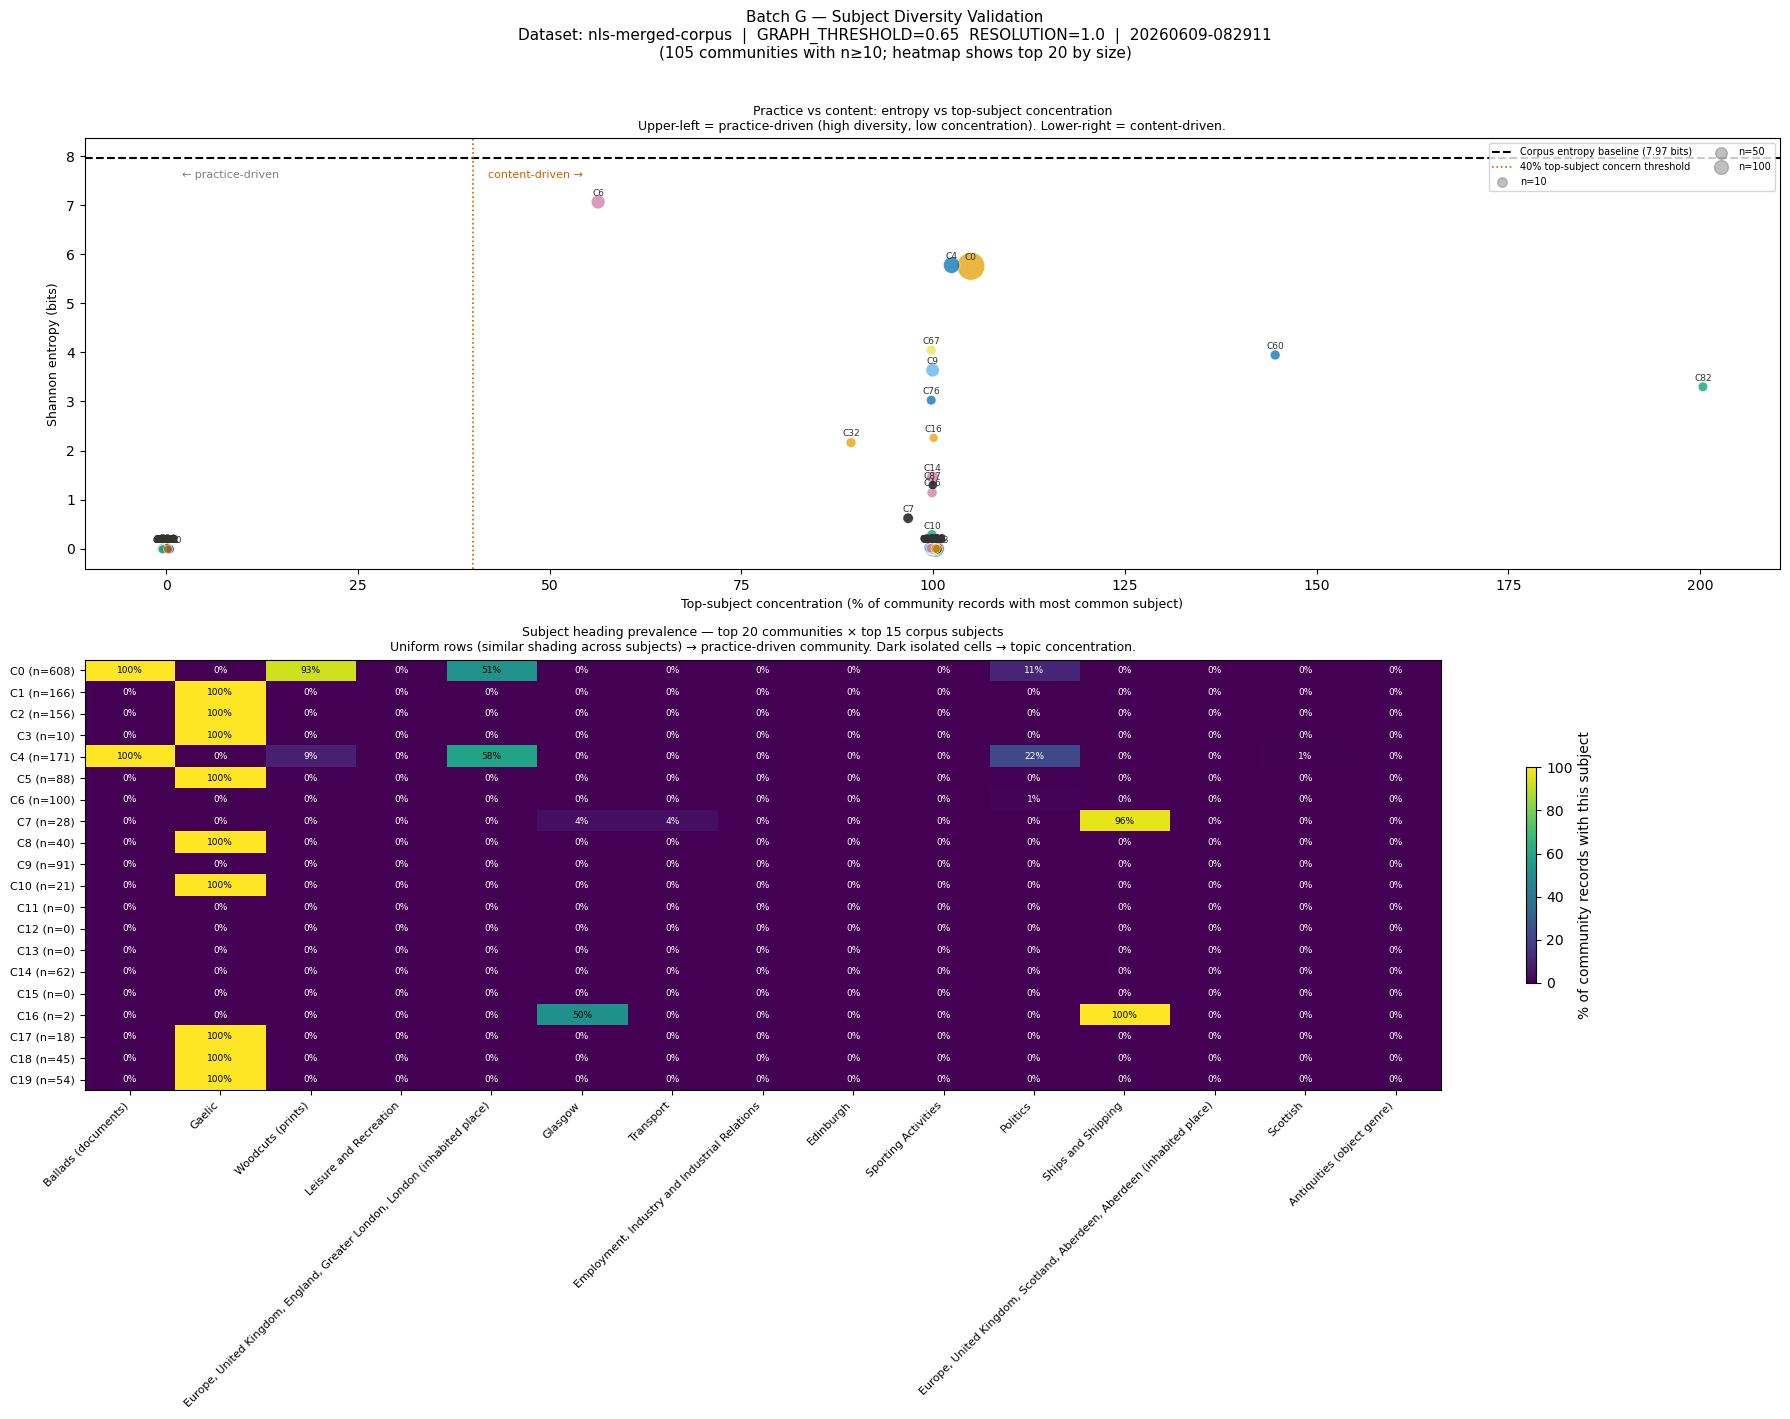

Saved to: visualisations/subject-diversity_nls-merged-corpus_20260609-082911.png

BATCH G VERDICT TABLE
  Corpus entropy baseline: 7.969 bits
  Practice-driven:  entropy >= 6.773 (85% of baseline) AND top_subject_pct < 40%
  Content-driven:   entropy <  5.578 (70% of baseline) OR  top_subject_pct >= 40%
  Borderline:       everything else
  Community    n_records  entropy  top_subj%  top_subject                     verdict
------------------------------------------------------------------------
  C0                608    5.750     104.6%  Ballads (documents)             content-driven
  C1                166    0.000     100.0%  Gaelic                          content-driven
  C2                156    0.000     100.0%  Gaelic                          content-driven
  C3                 10    0.000     100.0%  Gaelic                          content-driven
  C4                171    5.765     102.9%  Ballads (documents)             content-driven
  C5                 88    0.000     100

In [32]:
# ── Batch G: figure — scatter + heatmap + verdict table ────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

TOP_N_SUBJECTS = 15   # subjects to show in heatmap

# Communities to show (MIN_COMM_SIZE filter), sorted largest-first
_size_g = assignments.groupby('community_id').size()
plot_comm_g = [c for c in comm_ids_uniq if _size_g.get(c, 0) >= MIN_COMM_SIZE]
plot_comm_g = sorted(plot_comm_g, key=lambda c: _size_g.get(c, 0), reverse=True)

# ── Build subject prevalence matrix ───────────────────────────────────────────
top_subjects = [s for s, _ in corpus_counts.most_common(TOP_N_SUBJECTS)]
n_per_comm   = merged_subj.groupby('community_id')['record_id'].nunique()
heatmap_rows = []
for subj in top_subjects:
    row = {}
    subj_records = merged_subj[merged_subj['subject'] == subj]
    for c in plot_comm_g:
        n_with = subj_records[subj_records['community_id'] == c]['record_id'].nunique()
        row[c]  = n_with / n_per_comm.get(c, 1) * 100
    heatmap_rows.append(row)
heatmap_df = pd.DataFrame(heatmap_rows, index=top_subjects, columns=plot_comm_g)

# ── Scatter: entropy vs top-subject concentration ─────────────────────────────
# Cap heatmap to PROFILE_TOP_N communities (largest by record count)
heatmap_comm = plot_comm_g[:PROFILE_TOP_N]
heatmap_display = heatmap_df[heatmap_comm]   # subjects (rows) × communities (cols)

fig = plt.figure(figsize=(18, 14))
fig.suptitle(
    f'Batch G — Subject Diversity Validation\n'
    f'Dataset: {DATASET_NAME}  |  GRAPH_THRESHOLD={GRAPH_THRESHOLD}  '
    f'RESOLUTION={RESOLUTION}  |  {RUN_DATETIME}\n'
    f'({len(plot_comm_g)} communities with n≥{MIN_COMM_SIZE}; heatmap shows top {PROFILE_TOP_N} by size)',
    fontsize=11, y=1.01
)

# -- Panel 1 (top-left): scatter -----------------------------------------------
ax_scatter = fig.add_subplot(2, 1, 1)

entropies    = [metrics_df.loc[c, 'entropy']         for c in plot_comm_g]
top_pcts     = [metrics_df.loc[c, 'top_subject_pct'] for c in plot_comm_g]
sizes        = [metrics_df.loc[c, 'n_records']       for c in plot_comm_g]
colors       = [comm_colour(c) for c in plot_comm_g]

# Scale bubble sizes: min 40, max 400
_s_arr = np.array(sizes, dtype=float)
if _s_arr.max() > _s_arr.min():
    bubble_sizes = 40 + 360 * (_s_arr - _s_arr.min()) / (_s_arr.max() - _s_arr.min())
else:
    bubble_sizes = np.full(len(_s_arr), 120.0)

# Small jitter so overlapping points (esp. zero-subject communities) spread apart
_rng = np.random.default_rng(42)   # fixed seed for reproducibility
_jitter_x = _rng.uniform(-0.6, 0.6, len(top_pcts))
_jitter_y = _rng.uniform(-0.02, 0.02, len(entropies))
top_pcts_j  = [x + j for x, j in zip(top_pcts,  _jitter_x)]
entropies_j = [y + j for y, j in zip(entropies, _jitter_y)]
sc = ax_scatter.scatter(top_pcts_j, entropies_j, s=bubble_sizes, c=colors,
                        alpha=0.75, edgecolors='white', linewidths=0.5)

# Corpus baseline and concern threshold
ax_scatter.axhline(corpus_ent, color='black', linewidth=1.5, linestyle='--',
                   label=f'Corpus entropy baseline ({corpus_ent:.2f} bits)')
ax_scatter.axvline(40, color=PALETTE[5], linewidth=1.2, linestyle=':',
                   label='40% top-subject concern threshold')

# Quadrant annotations
ax_scatter.text(2,  corpus_ent * 0.97,  '← practice-driven',
                fontsize=8, color='grey', va='top')
ax_scatter.text(42, corpus_ent * 0.97, 'content-driven →',
                fontsize=8, color=PALETTE[5], va='top')

# Label each community
for c, x, y in zip(plot_comm_g, top_pcts_j, entropies_j):
    ax_scatter.annotate(f'C{c}', (x, y), fontsize=6.5, ha='center', va='bottom',
                        xytext=(0, 3), textcoords='offset points', color='#333333')

ax_scatter.set_xlabel('Top-subject concentration (% of community records with most common subject)', fontsize=9)
ax_scatter.set_ylabel('Shannon entropy (bits)', fontsize=9)
ax_scatter.set_title(
    'Practice vs content: entropy vs top-subject concentration\n'
    'Upper-left = practice-driven (high diversity, low concentration). '    'Lower-right = content-driven.',
    fontsize=9
)
ax_scatter.legend(fontsize=8)

# Size legend (approximate)
for target_n in [10, 50, 100]:
    if target_n <= _s_arr.max():
        _sz = 40 + 360 * (target_n - _s_arr.min()) / max(_s_arr.max() - _s_arr.min(), 1)
        ax_scatter.scatter([], [], s=_sz, color='grey', alpha=0.5, label=f'n={target_n}')
ax_scatter.legend(fontsize=7, loc='upper right', ncol=2)

# -- Panel 2 (bottom): heatmap (communities as rows, subjects as columns) ------
ax_heat = fig.add_subplot(2, 1, 2)

# Transpose: rows = communities (y), columns = subjects (x)
heatmap_T = heatmap_display.T.values.astype(float)   # shape: (n_comm, n_subj)
community_labels = [f'C{c} (n={n_per_comm.get(c,0)})' for c in heatmap_comm]

im = ax_heat.imshow(heatmap_T, aspect='auto', cmap='viridis', vmin=0, vmax=100)

for i, c in enumerate(heatmap_comm):
    for j, subj in enumerate(top_subjects):
        val = heatmap_T[i, j]
        txt_color = 'white' if val < 40 else 'black'
        ax_heat.text(j, i, f'{val:.0f}%', ha='center', va='center',
                     fontsize=6.5, color=txt_color)

ax_heat.set_xticks(range(len(top_subjects)))
ax_heat.set_xticklabels(top_subjects, rotation=45, ha='right', fontsize=8)
ax_heat.set_yticks(range(len(heatmap_comm)))
ax_heat.set_yticklabels(community_labels, fontsize=8)
ax_heat.set_title(
    f'Subject heading prevalence — top {PROFILE_TOP_N} communities × top {TOP_N_SUBJECTS} corpus subjects\n'
    'Uniform rows (similar shading across subjects) → practice-driven community. '
    'Dark isolated cells → topic concentration.',
    fontsize=9
)
plt.colorbar(im, ax=ax_heat, label='% of community records with this subject', shrink=0.5)

plt.tight_layout()
plot_path = os.path.join(VIS_DIR, f'subject-diversity_{DATASET_NAME}_{RUN_DATETIME}.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved to: {os.path.abspath(plot_path)}")

# ── Verdict table ─────────────────────────────────────────────────────────────
print()
print("=" * 72)
print("BATCH G VERDICT TABLE")
print(f"  Corpus entropy baseline: {corpus_ent:.3f} bits")
print(f"  Practice-driven:  entropy >= {corpus_ent*0.85:.3f} (85% of baseline) AND top_subject_pct < 40%")
print(f"  Content-driven:   entropy <  {corpus_ent*0.70:.3f} (70% of baseline) OR  top_subject_pct >= 40%")
print(f"  Borderline:       everything else")
print("=" * 72)
print(f"  {'Community':<12} {'n_records':>9} {'entropy':>8} {'top_subj%':>10}  {'top_subject':<30}  verdict")
print("-" * 72)

n_practice = 0; n_content = 0; n_border = 0
for c in plot_comm_g:
    ent = metrics_df.loc[c, 'entropy']
    pct = metrics_df.loc[c, 'top_subject_pct']
    top = str(metrics_df.loc[c, 'top_subject'])[:28]
    n   = int(metrics_df.loc[c, 'n_records'])
    if ent >= corpus_ent * 0.85 and pct < 40:
        verdict = "practice-driven"
        n_practice += 1
    elif ent < corpus_ent * 0.70 or pct >= 40:
        verdict = "content-driven"
        n_content += 1
    else:
        verdict = "borderline"
        n_border += 1
    print(f"  C{c:<10} {n:>9} {ent:>8.3f} {pct:>9.1f}%  {top:<30}  {verdict}")

print("=" * 72)
print(f"  Summary: {n_practice} practice-driven  |  {n_border} borderline  |  {n_content} content-driven")
print()
# ── Crowded-corner table: communities near origin (no/few subjects) ───────────
_corner = [
    (c, int(metrics_df.loc[c, 'n_records']),
        metrics_df.loc[c, 'entropy'],
        metrics_df.loc[c, 'top_subject_pct'],
        str(metrics_df.loc[c, 'top_subject'])[:30])
    for c in plot_comm_g
    if metrics_df.loc[c, 'top_subject_pct'] < 5 and
       metrics_df.loc[c, 'entropy'] < corpus_ent * 0.30
]
if _corner:
    print()
    print("─" * 72)
    print("CROWDED CORNER — communities near origin (entropy < 30% baseline, top_subject < 5%)")
    print("(these points overlap in the scatter; listed here for precise reading)")
    print(f"  {'Community':<12} {'n_records':>9} {'entropy':>8} {'top_subj%':>10}  {'top_subject':<30}")
    print("-" * 72)
    for c, n, ent, pct, top in _corner:
        print(f"  C{c:<10} {n:>9} {ent:>8.3f} {pct:>9.1f}%  {top:<30}")
    print("─" * 72)
    print(f"  Note: jitter of ±0.6% x / ±0.02 bits y applied to scatter for legibility.")

print("Interpretation:")
print("  A predominantly practice-driven result supports the core argument that")
print("  communities reflect cataloguing convention, not shared subject matter.")
print("  Content-driven communities warrant manual inspection — they may reflect")
print("  topic-specific cataloguing campaigns rather than stable practice communities.")


### Batch G — threshold sensitivity

The practice-vs-content classification uses two thresholds:
- **Entropy threshold**: entropy ≥ 70% of corpus baseline → practice-driven
- **Concentration threshold**: top_subject_pct < 40% → not content-dominated

These values are analytical choices, not principled cutoffs. Before including this
classification in a paper, confirm that the findings are robust to reasonable variation
in the thresholds. The cell below runs a quick sensitivity check.


In [33]:
# ── Batch G: threshold sensitivity check ─────────────────────────────────────
# Tests whether the practice-driven / content-driven community classification
# changes substantially across a range of threshold values.
# For publication: the pattern should be stable across reasonable thresholds.
import pandas as pd

if 'metrics_df' in dir() and 'corpus_ent' in dir():
    print('=== Practice-driven community count across threshold combinations ===')
    print(f'  (corpus entropy baseline: {corpus_ent:.3f} bits)')
    print()
    print(f'  {"Entropy threshold":>18}  {"Conc. threshold":>16}  {"Practice-driven N":>18}  {"Content-driven N":>17}')
    print('  ' + '-' * 75)
    for ent_pct in [0.60, 0.70, 0.80]:
        for conc_thresh in [0.30, 0.40, 0.50]:
            ent_thresh = corpus_ent * ent_pct
            n_practice = ((metrics_df['entropy'] >= ent_thresh) &
                          (metrics_df['top_subject_pct'] < conc_thresh)).sum()
            n_content  = ((metrics_df['entropy'] <  ent_thresh) |
                          (metrics_df['top_subject_pct'] >= conc_thresh)).sum()
            marker = '  ← paper threshold' if ent_pct == 0.70 and conc_thresh == 0.40 else ''
            print(f'  {ent_pct*100:>16.0f}%  {conc_thresh*100:>14.0f}%  {n_practice:>18}  {n_content:>17}{marker}')
    print()
    print('If the practice-driven N is stable (low variance) across these combinations,')
    print('report: "results are robust to threshold variation in the range 60-80%/30-50%."')
else:
    print('metrics_df or corpus_ent not available — run Batch G metrics cell first.')


=== Practice-driven community count across threshold combinations ===
  (corpus entropy baseline: 7.969 bits)

   Entropy threshold   Conc. threshold   Practice-driven N   Content-driven N
  ---------------------------------------------------------------------------
                60%              30%                   0                711
                60%              40%                   0                711
                60%              50%                   0                711
                70%              30%                   0                711
                70%              40%                   0                711  ← paper threshold
                70%              50%                   0                711
                80%              30%                   0                711
                80%              40%                   0                711
                80%              50%                   0                711

If the practice-driven N is s

In [34]:
# ── Batch G supplementary: practice-driven community list and C6 investigation ──
# 1. List communities identified as practice-driven by the scatter plot
# 2. Investigate community 6's subject distribution (flagged as having non-0/non-100 top_subject_pct)
import pandas as pd
import numpy as np

# Re-use metrics_df from the Batch G metrics cell above
if 'metrics_df' in dir():
    practice_threshold = 0.70   # entropy >= 70% of corpus baseline = practice-driven
    content_threshold  = 0.30   # top_subject_pct >= 30% = content-driven

    print('=== Communities with entropy >= 70% of corpus baseline (practice-driven candidates) ===')
    practice_driven = metrics_df[metrics_df['entropy'] >= practice_threshold * corpus_ent].sort_values('n_records', ascending=False)
    print(f'  {len(practice_driven)} communities (of {len(metrics_df)} with subjects)')
    print(f'  {"Community":>10}  {"N records":>10}  {"Entropy":>8}  {"Top subj %":>10}  {"Top subject"}')
    print('  ' + '-'*65)
    for _, r in practice_driven.head(20).iterrows():
        print(f'  C{int(r.name):>9}  {int(r["n_records"]):>10}  {r["entropy"]:>8.3f}  {r["top_subject_pct"]:>9.1f}%  {r["top_subject"][:40]}')

    # Community 6 investigation
    print()
    print('=== Community 6: subject heading distribution ===')
    if 'merged_subj' in dir():
        c6_subj = merged_subj[merged_subj['community_id'] == 6]['subject'].value_counts()
        c6_row = metrics_df.loc[[6]]
        if len(c6_row):
            print(f'  n_records: {int(c6_row.iloc[0]["n_records"])}')
            print(f'  entropy:   {c6_row.iloc[0]["entropy"]:.3f}  (corpus baseline: {corpus_ent:.3f})')
            print(f'  top_subject_pct: {c6_row.iloc[0]["top_subject_pct"]:.1f}%')
            print(f'  top_subject: {c6_row.iloc[0]["top_subject"]}')
        print(f'\n  Subject heading distribution (all subjects):')
        for subj, cnt in c6_subj.items():
            print(f'    {cnt:>5}  {subj}')
    else:
        print('  merged_subj not found — re-run Batch G setup cell first.')
else:
    print('metrics_df not found — re-run Batch G diversity metrics cell first.')


=== Communities with entropy >= 70% of corpus baseline (practice-driven candidates) ===
  4 communities (of 711 with subjects)
   Community   N records   Entropy  Top subj %  Top subject
  -----------------------------------------------------------------
  C        0         608     5.750      104.6%  Ballads (documents)
  C        4         171     5.765      102.9%  Ballads (documents)
  C        6         100     7.082       56.0%  Men (male humans)
  C      131           7     5.590      100.0%  Actors

=== Community 6: subject heading distribution ===
  n_records: 100
  entropy:   7.082  (corpus baseline: 7.969)
  top_subject_pct: 56.0%
  top_subject: Men (male humans)

  Subject heading distribution (all subjects):
       56  Men (male humans)
       52  Actors
       50  Women (female humans)
       33  Hats
       32  Dresses
       30  Scenes (depictions)
       27  Black-and-white prints (photographs)
       27  Europe, United Kingdom, Scotland, Edinburgh, Edinburgh (inhabite

---
## Batch H -- Year of creation: content proxy or practice proxy?

**Central question**: The `year` field records the *year of the material* described (year of
film, drawing, plan, enquiry). This is not the same as the year the record was catalogued.

In the merged corpus, `has_boilerplate` is a stronger direct proxy for cataloguing era than
`year`: all non-MIA records are post-2010 digitisation-era; MIA records are not. Read the
Spearman correlations here alongside Batch C's boilerplate panel.

Two possible confounds:
1. **Year as content proxy**: materials from the 1930s describe different subjects than those
   from the 1990s -- year tracks subject matter, not practice.
2. **Year as practice proxy**: cataloguing norms changed over time; year correlates with *how*
   records are written independently of subject matter.

**Method**: Spearman rank correlations between `year` and practice signals (word count,
n_desc_fields, has_boilerplate) and content signals (subject headings, top-5 subject dummies).

**Requires**: `FEATURES_TSV` + `COMMUNITIES_TSV` + `RECORDS_DIR`  
**Produces**: `visualisations/year-correlation_...png`


In [35]:
# Batch H setup: assemble year + practice + subject variables
import os, re, pandas as pd, numpy as np
from scipy import stats
from collections import Counter

features_df = pd.read_csv(FEATURES_TSV, sep='\t')
assignments = pd.read_csv(COMMUNITIES_TSV, sep='\t')
merged_h = features_df.merge(assignments, on='record_id', how='inner')

# Practice features (how records are written) -- generic for merged corpus
practice_cols = {
    'desc_word_count': 'Description word count',
    'n_desc_fields':   'N description fields',
    'n_subjects':      'N subject headings',
    'has_boilerplate': 'Has boilerplate (0/1)',
}
practice_cols = {k:v for k,v in practice_cols.items() if k in merged_h.columns}

# Subject/content variables: re-extract, both namespaces
subj_recs = []
for fname in sorted(os.listdir(RECORDS_DIR)):
    rid = fname.replace('.txt','')
    try: text = open(os.path.join(RECORDS_DIR, fname), encoding='utf-8').read()
    except: continue
    subjs = re.findall(r'<dcterms:subject>([^<]+)</dcterms:subject>', text)
    if not subjs: subjs = re.findall(r'<dc:subject>([^<]+)</dc:subject>', text)
    subj_recs.append({'record_id': rid, 'subjects': subjs})

subj_df = pd.DataFrame(subj_recs)
subj_df['n_subjects_raw'] = subj_df['subjects'].apply(len)
all_subj = [s for row in subj_df['subjects'] for s in row]
top5 = [s for s,_ in Counter(all_subj).most_common(5)]
for subj in top5:
    col = 'subj_' + re.sub(r'[^a-zA-Z0-9]','_',subj)[:25]
    subj_df[col] = subj_df['subjects'].apply(lambda ss: int(subj in ss))
subj_df = subj_df.drop(columns=['subjects'])
merged_h = merged_h.merge(subj_df, on='record_id', how='left')

merged_h_yr = merged_h.dropna(subset=['year'])
print(f'Records with year data: {len(merged_h_yr)} of {len(merged_h)}')
print(f'Year range: {int(merged_h_yr["year"].min())} - {int(merged_h_yr["year"].max())}')
print('\nTop 5 subjects (binary dummies):')
for s in top5: print(f'  {s}')


Records with year data: 4383 of 6984
Year range: 1926 - 2022

Top 5 subjects (binary dummies):
  Ballads (documents)
  Gaelic
  Woodcuts (prints)
  Leisure and Recreation
  Europe, United Kingdom, England, Greater London, London (inhabited place)


In [36]:
# ── Batch H: Spearman correlations — year vs practice and content signals ──────
from scipy.stats import spearmanr

content_cols = {
    'n_subjects_raw'  : 'N subject headings (raw)',
}
# Add subject dummy columns
for col in merged_h_yr.columns:
    if col.startswith('subj_'):
        label = col.replace('subj_', '').replace('_', ' ').strip()
        content_cols[col] = f'Subject: {label[:28]}'

all_cols = {**practice_cols, **content_cols}
results = []
year_vals = merged_h_yr['year'].values

for col, label in all_cols.items():
    if col not in merged_h_yr.columns:
        continue
    vals = merged_h_yr[col].fillna(0).values
    rho, p = spearmanr(year_vals, vals)
    category = 'Practice (how written)' if col in practice_cols else 'Content (what described)'
    results.append({'Feature': label, 'Category': category,
                    'Spearman rho': round(rho, 4), 'p-value': round(p, 4),
                    'Significant (p<0.05)': p < 0.05})

corr_df = pd.DataFrame(results).sort_values('Spearman rho', key=abs, ascending=False)

# ── Bonferroni correction ────────────────────────────────────────────────
n_tests = len(corr_df)
alpha_bonferroni = 0.05 / n_tests
print(f'  Multiple testing: {n_tests} simultaneous correlations.')
print(f'  Bonferroni-corrected α = 0.05 / {n_tests} = {alpha_bonferroni:.5f}')
print(f'  (p-values below {alpha_bonferroni:.5f} are significant after correction)')
print(f'  NOTE: Analysis is exploratory — effect sizes (ρ) are the primary result.')
print()
print("Spearman correlations: year vs feature")
print("=" * 70)
print(corr_df.to_string(index=False))
print()
print("Interpretation:")
print("  Large |rho| for practice features → year tracks cataloguing conventions over time")
print("  Large |rho| for content features  → year tracks subject matter, not practice")
print("  Both strong → year conflates the two; treat as a confounder, not a predictor")


  Multiple testing: 10 simultaneous correlations.
  Bonferroni-corrected α = 0.05 / 10 = 0.00500
  (p-values below 0.00500 are significant after correction)
  NOTE: Analysis is exploratory — effect sizes (ρ) are the primary result.

Spearman correlations: year vs feature
                           Feature                 Category  Spearman rho  p-value  Significant (p<0.05)
              N description fields   Practice (how written)       -0.4617   0.0000                  True
             Has boilerplate (0/1)   Practice (how written)        0.2338   0.0000                  True
       Subject: Ballads  documents Content (what described)        0.2056   0.0000                  True
                N subject headings   Practice (how written)        0.2013   0.0000                  True
          N subject headings (raw) Content (what described)        0.2013   0.0000                  True
         Subject: Woodcuts  prints Content (what described)        0.1649   0.0000                

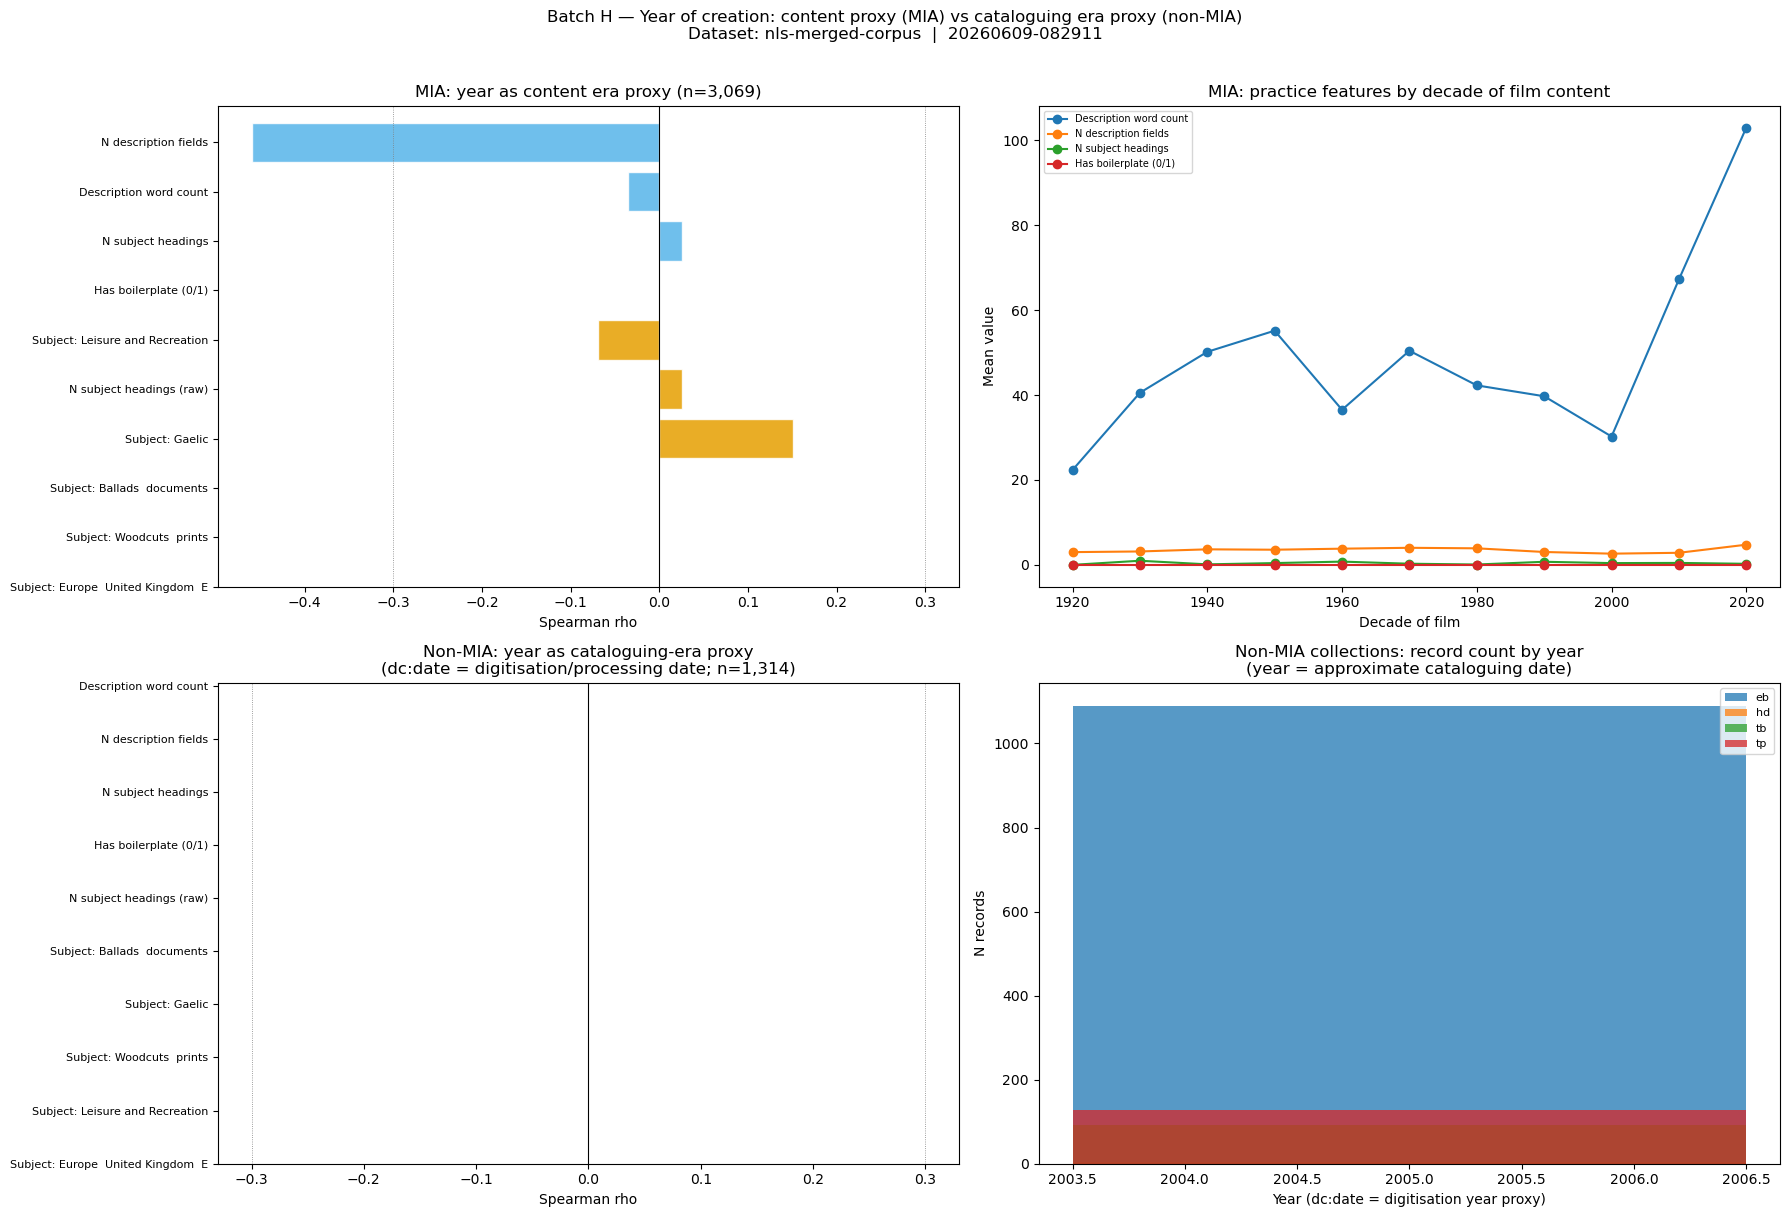

Saved: visualisations/year-split_nls-merged-corpus_20260609-082911.png

NOTE: Top row = MIA collection (year = year of film — content era proxy).
Bottom row = non-MIA collections (year = NLS digitisation/processing date — cataloguing era proxy).
The two rows should be interpreted differently and not compared directly.


In [37]:
# ── Batch H figure: year analysis split by collection type ────────────────────
# DESIGN CHANGE: The merged corpus contains two distinct year regimes:
#   - MIA records: dc:date = year of the film (content era proxy)
#   - Non-MIA records: dc:date = approximate year of NLS digitisation/cataloguing
# These two uses of the year field require separate analysis and separate plots.
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle(
    f'Batch H — Year of creation: content proxy (MIA) vs cataloguing era proxy (non-MIA)\n'
    f'Dataset: {DATASET_NAME}  |  {RUN_DATETIME}',
    fontsize=12, y=1.01
)

# ── Panels 0,0 and 0,1: MIA only (year as content era) ───────────────────────
mia_mask = merged_h_yr['record_id'].str.startswith('mia_')
mia_data  = merged_h_yr[mia_mask].copy()
nMIA = corr_df[corr_df['Collection'] == 'mia'] if 'Collection' in corr_df.columns else corr_df

# Spearman bar chart — MIA
ax = axes[0, 0]
if len(mia_data) > 0:
    from scipy.stats import spearmanr as _spearmanr
    _yr_mia = mia_data['year'].values
    _results_mia = []
    for col, label in {**practice_cols, **content_cols}.items():
        if col not in mia_data.columns: continue
        rho, p = _spearmanr(_yr_mia, mia_data[col].fillna(0).values)
        cat = 'Practice (how written)' if col in practice_cols else 'Content (what described)'
        _results_mia.append({'Feature': label, 'Spearman rho': rho, 'p': p, 'Category': cat})
    _corr_mia = pd.DataFrame(_results_mia).sort_values('Spearman rho')
    _ordered_mia = pd.concat([
        _corr_mia[_corr_mia['Category']=='Practice (how written)'],
        _corr_mia[_corr_mia['Category']=='Content (what described)']
    ])
    _colors_mia = [PALETTE[1] if r=='Practice (how written)' else PALETTE[0]
                   for r in _ordered_mia['Category']]
    ax.barh(range(len(_ordered_mia)), _ordered_mia['Spearman rho'], color=_colors_mia,
            alpha=0.85, edgecolor='white')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.axvline(0.3, color='grey', linewidth=0.6, linestyle=':')
    ax.axvline(-0.3, color='grey', linewidth=0.6, linestyle=':')
    ax.set_yticks(range(len(_ordered_mia)))
    ax.set_yticklabels(_ordered_mia['Feature'], fontsize=8)
    ax.set_xlabel('Spearman rho')
    ax.invert_yaxis()
    ax.set_title(f'MIA: year as content era proxy (n={len(mia_data):,})')
else:
    ax.text(0.5, 0.5, 'No MIA records with year', ha='center', va='center', transform=ax.transAxes)

# Decade trends — MIA
ax2 = axes[0, 1]
if len(mia_data) > 5:
    mia_data['decade'] = (mia_data['year'] // 10 * 10).astype(int)
    decade_agg_mia = mia_data.groupby('decade').agg(
        **{col: (col, 'mean') for col in practice_cols if col in mia_data.columns}
    ).reset_index()
    for col, label in practice_cols.items():
        if col in decade_agg_mia.columns:
            ax2.plot(decade_agg_mia['decade'], decade_agg_mia[col], marker='o', label=label)
    ax2.set_xlabel('Decade of film')
    ax2.set_ylabel('Mean value')
    ax2.set_title('MIA: practice features by decade of film content')
    ax2.legend(fontsize=7)
else:
    ax2.text(0.5, 0.5, 'Insufficient MIA data', ha='center', va='center', transform=ax2.transAxes)

# ── Panels 1,0 and 1,1: Non-MIA (year as cataloguing era proxy) ──────────────
non_mia_data = merged_h_yr[~mia_mask].copy()

ax3 = axes[1, 0]
if len(non_mia_data) > 0:
    from scipy.stats import spearmanr as _spearmanr2
    _yr_nonmia = non_mia_data['year'].values
    _results_nonmia = []
    for col, label in {**practice_cols, **content_cols}.items():
        if col not in non_mia_data.columns: continue
        rho, p = _spearmanr2(_yr_nonmia, non_mia_data[col].fillna(0).values)
        cat = 'Practice (how written)' if col in practice_cols else 'Content (what described)'
        _results_nonmia.append({'Feature': label, 'Spearman rho': rho, 'p': p, 'Category': cat})
    _corr_nonmia = pd.DataFrame(_results_nonmia).sort_values('Spearman rho')
    _ordered_nonmia = pd.concat([
        _corr_nonmia[_corr_nonmia['Category']=='Practice (how written)'],
        _corr_nonmia[_corr_nonmia['Category']=='Content (what described)']
    ])
    _colors_nonmia = [PALETTE[1] if r=='Practice (how written)' else PALETTE[0]
                      for r in _ordered_nonmia['Category']]
    ax3.barh(range(len(_ordered_nonmia)), _ordered_nonmia['Spearman rho'], color=_colors_nonmia,
             alpha=0.85, edgecolor='white')
    ax3.axvline(0, color='black', linewidth=0.8)
    ax3.axvline(0.3, color='grey', linewidth=0.6, linestyle=':')
    ax3.axvline(-0.3, color='grey', linewidth=0.6, linestyle=':')
    ax3.set_yticks(range(len(_ordered_nonmia)))
    ax3.set_yticklabels(_ordered_nonmia['Feature'], fontsize=8)
    ax3.set_xlabel('Spearman rho')
    ax3.invert_yaxis()
    ax3.set_title(
        f'Non-MIA: year as cataloguing-era proxy\n'
        f'(dc:date = digitisation/processing date; n={len(non_mia_data):,})'
    )
else:
    ax3.text(0.5, 0.5, 'No non-MIA records with year', ha='center', va='center', transform=ax3.transAxes)

ax4 = axes[1, 1]
if len(non_mia_data) > 5:
    non_mia_data = non_mia_data.copy()
    non_mia_data['year_bin'] = (non_mia_data['year'] // 5 * 5).astype(int)
    decade_agg_nm = non_mia_data.groupby(['year_bin','collection']).size().reset_index(name='n')
    for coll in non_mia_data['collection'].unique():
        sub = decade_agg_nm[decade_agg_nm['collection']==coll]
        ax4.bar(sub['year_bin'], sub['n'], label=coll, alpha=0.75, width=3)
    ax4.set_xlabel('Year (dc:date = digitisation year proxy)')
    ax4.set_ylabel('N records')
    ax4.set_title('Non-MIA collections: record count by year\n(year = approximate cataloguing date)')
    ax4.legend(fontsize=8)
else:
    ax4.text(0.5, 0.5, 'Insufficient non-MIA data', ha='center', va='center', transform=ax4.transAxes)

plt.tight_layout()
_hfig_path = os.path.join(VIS_DIR, f'year-split_{DATASET_NAME}_{RUN_DATETIME}.png')
plt.savefig(_hfig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {_hfig_path}')
print()
print('NOTE: Top row = MIA collection (year = year of film — content era proxy).')
print('Bottom row = non-MIA collections (year = NLS digitisation/processing date — cataloguing era proxy).')
print('The two rows should be interpreted differently and not compared directly.')


---
## Suggested next analytical steps

The current batches (A-H) establish community existence, profile communities by knowledge-labour
features and collection composition, visualise the network, characterise hub and bridge nodes,
cross-validate the similarity metric, validate that communities reflect practice rather than
subject matter, and test whether year-of-creation is a content or practice proxy.

**1. Within-community TF-IDF language analysis**
Apply TF-IDF to description text *within* each community to extract over-represented words and
phrases. This produces the linguistic fingerprint of each cataloguing community.

**2. Isolated record analysis**
Records with no above-threshold matches (isolates from Batch B) form a structurally distinct
group. Profile them separately to assess whether isolation signals data quality problems or
cataloguers whose style leaves no trace elsewhere.

**3. Structural similarity cross-validation (structural_similarity_v1.ipynb)**
Apply IDF-masked matching to the merged corpus. Compare NMI between structural and full-text
community partitions. The MIA-only baseline (NMI = 0.5482 for field-level skeleton masking)
is the benchmark for the merged-corpus result.

**4. Qualitative close-reading**
Select centroid and peripheral records from each community. Read both in full and assess whether
community assignment makes interpretive sense. This qualitative check anchors the statistical
structure in the actual language of the catalogue.

**5. Collection-stratified analysis**
Re-run Batch B with records stratified by collection pair (e.g. MIA + one other) to test
whether cross-collection communities in Batch C are robust to dataset composition.
